# **Capitolo 3. Analisi ed Elaborazione dell'Offerta Second-Hand**

Concluso il processo di estrazione e fusione delle diverse fonti, si prosegue con la **preparazione** e l’**analisi del dataset relativo ai prodotti del catalogo dell’usato**. L’obiettivo è trasformare i dati grezzi in una base strutturata per le successive analisi congiunte. 

> Questo primo notebook riguardante le procedure descritte nel terzo capitolo, parte dalla pulizia preliminare del dataset sino ad arrivare a una serie di approfondimenti mirati sulle variabili chiave (*dall'inizio del capitolo 3 sino al paragrafo 3.3, incluso con annessi sottoparagrafi*).

## **3.1. Data cleaning e validazione strutturale**

Si garantisce l'**integrità** e la **coerenza dei dati**, attuando una serie di interventi di pulizia e validazione laddove necessari.

Preliminarmente, si prepara l'ambiente di lavoro, caricando il dataset grezzo dei prodotti presenti nel catalogo second-hand.

In [ ]:
import os
import time
import glob
import re
import pandas as pd
import numpy as np
import umap
import hdbscan
import math
import spacy
import anthropic
import json
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from collections import Counter
from collections import defaultdict
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kruskal
from IPython.display import display, HTML
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
import google.generativeai as genai
import seaborn as sns
from sklearn.preprocessing import normalize
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from itertools import combinations

try:
    nlp_it = spacy.load('it_core_news_sm', disable=['parser', 'ner'])
    SW_SPACY = nlp_it.Defaults.stop_words  
    display(HTML("<ul><li>Modello spaCy <code>it_core_news_sm</code> caricato correttamente.</li></ul>"))
except OSError:
    display(HTML("<ul><li><b>⚠ Modello spaCy non trovato.</b> Esegui nel terminale: <code>python -m spacy download it_core_news_sm</code> e riavvia il kernel.</li></ul>"))
    raise

import subprocess
subprocess.run(['pip', 'install', 'sentence-transformers', 'umap-learn', 'hdbscan', '-q', 'google-generativeai', '--quiet'])

while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")

cartella = Path("Circular Second Hand", "Mercato Usato", "Usato", "Dati - Usato")
file_trovati = list(cartella.glob("second_hand_clean__*.csv"))

if not file_trovati:
    print(f"ERRORE: Nessun file trovato in {cartella}")
    raise SystemExit(1)

file_prodotti = file_trovati[0]
print(f"File dei Prodotti Identificato: {file_prodotti.name}")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
try:
    df = pd.read_csv(file_prodotti, dtype={'Numero Articolo Catalogo': str, 'ID Prodotto': str, 'Numero Offerta': str, 'ID Negozio': str},)
    print("\nDataset dei Prodotti Second Hand letto con successo!")
    display(HTML(f"<b>Righe totali</b>: {df.shape[0]} <br><b>Colonne totali</b>: {df.shape[1]}"))

except FileNotFoundError as e:
    print(f"Errore durante la lettura: {e}. Assicurarsi che i file esistano.")
    raise SystemExit(1)

tipi_df = pd.DataFrame(df.dtypes, columns=['Tipo']).reset_index()
tipi_df.columns = ['Colonna', 'Tipo']
tipi_df['Tipo'] = tipi_df['Tipo'].astype(str) 

tipi_grezzi = tipi_df.groupby('Tipo').agg(N_Colonne=('Colonna', 'count'), Elenco_Colonne=('Colonna', lambda x: ', '.join(x))).reset_index().sort_values('N_Colonne', ascending=False)
tipi_grezzi.index = tipi_grezzi.index + 1

display(HTML("<h3><b>Tipi di dato grezzi rilevati all'importazione:</b></h3>"))

tabella_tipi = tipi_grezzi.style.set_properties(subset=['Elenco_Colonne'], **{'text-align': 'left', 'white-space': 'pre-wrap', 'word-wrap': 'break-word'}).set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}])
display(tabella_tipi)


Dataset dei Prodotti Second Hand letto con successo!


,Tipo,N_Colonne,Elenco_Colonne
4,str,29,"Numero Offerta, ID Prodotto, Numero Articolo Catalogo, Nome Prodotto, Descrizione Prodotto, Note Extra Usato, Condizione Usato, Descrizione Condizione, Motivo Vendita, Classe Energetica, Valuta, Sconto, ID Negozio, Nome Negozio, Tipologia Negozio, Città Negozio, Provincia Negozio, Data Apertura Negozio, Fuso Orario Negozio, Descrizione Breve Catalogo, Dettagli Articolo Catalogo, Designer, Materiali, Cura, Buono a sapersi + Sicurezza e conformità, Informazioni Tecniche, Misure, Timestamp Prodotto, Timestamp Info"
1,float64,2,"Prezzo Originale, Prezzo Scontato"
2,int64,1,Disponibilità
3,object,1,Imballaggio Presente


Acquisito il dataset grezzo, lo si sottopone a un processo di validazione e pulizia: dalla semplice pulizia a livello di riga, ad un'analisi verticale per esplorare le colonne, fino a verifiche relazionali e a trasformazioni critiche.

In [ ]:
# PULIZIA A LIVELLO DI RIGA: DUPLICATI E MISSING ASSOLUTI
display(HTML("<h3><b>Pulizia a livello di riga: duplicati e missing assoluti</b></h3>"))

# Ricerca e rimozione righe interamente duplicate
duplicati_totali = df.duplicated().sum()

if duplicati_totali > 0:
    print(f"Trovate {duplicati_totali} righe interamente duplicate. Procedo con la rimozione...")
    df.drop_duplicates(inplace=True)
else:
    print("Nessuna riga duplicata trovata.")

# Ricerca e rimozione righe interamente vuote (tutti i valori sono NaN)
righe_vuote = df.isna().all(axis=1).sum()

if righe_vuote > 0:
    print(f"Trovate {righe_vuote} righe interamente vuote (ghost rows). Procedo con la rimozione...")
    df.dropna(how='all', inplace=True)
else:
    print("Nessuna riga interamente vuota trovata.")

# Riepilogo
display(HTML(
    f"<hr style='border-top: 1px solid #d3d3d3; margin-top: 5px; margin-bottom: 15px;'/>"
    f"Pulizia iniziale completata. <br/>"
    f"Dataset aggiornato: <b>{df.shape[0]} righe</b> × <b>{df.shape[1]} colonne</b>. <br/>"
    f"Le <b>colonne</b> sono:"))

nomi_colonne = list(df.columns)
num_colonne_visive = 3
num_righe = math.ceil(len(nomi_colonne) / num_colonne_visive)

html_colonne = "<table style='width:100%; border:none; text-align:left;'>"

for r in range(num_righe):
    html_colonne += "<tr>"
    for c in range(num_colonne_visive):
        idx = c * num_righe + r  # Ordinamento verticale (colonna-major)
        if idx < len(nomi_colonne):
            html_colonne += f"<td style='padding:4px 8px;'><code>{nomi_colonne[idx]}</code></td>"
        else:
            html_colonne += "<td></td>"
    html_colonne += "</tr>"

html_colonne += "</table>"
display(HTML(html_colonne))

Nessuna riga duplicata trovata.
Nessuna riga interamente vuota trovata.


Numero Offerta,Classe Energetica,Fuso Orario Negozio
ID Prodotto,Valuta,Descrizione Breve Catalogo
Numero Articolo Catalogo,Prezzo Originale,Dettagli Articolo Catalogo
Nome Prodotto,Prezzo Scontato,Designer
Descrizione Prodotto,Sconto,Materiali
Note Extra Usato,ID Negozio,Cura
Disponibilità,Nome Negozio,Buono a sapersi + Sicurezza e conformità
Condizione Usato,Tipologia Negozio,Informazioni Tecniche
Descrizione Condizione,Città Negozio,Misure
Imballaggio Presente,Provincia Negozio,Timestamp Prodotto
Motivo Vendita,Data Apertura Negozio,Timestamp Info


Risolte le anomalie a livello di riga, il ciclo seguente esplora ogni colonna in modo puramente descrittivo: lo scopo è raccogliere osservazioni e annotare i candidati alla rimozione, senza eseguire ancora alcuna modifica al dataset.

In [ ]:
# ANALISI INDIVIDUALE PER COLONNA
display(HTML("<h3><b>ANALISI INDIVIDUALE COLONNA PER COLONNA</b></h3>"))
colonne_da_eliminare_cell1 = {}   # {nome_colonna: motivazione} 
n_righe = len(df)

# -----------------------------------------------------------------------------
# FUNZIONI DI SUPPORTO

# Funzione centralizzata per il calcolo dei valori mancanti (real NaN + placeholder stringa)
PLACEHOLDER_MISSING = {'nan', '<na>', 'none', 'no info', '-', '--', '', 'vuoto', 'n/a', 'nd'}
def conta_missing(serie):
    n_null = serie.isna().sum()                              
    serie_valida = serie.dropna().astype(str).str.strip().str.lower()
    n_str = serie_valida.isin(PLACEHOLDER_MISSING).sum()   
    n_tot = n_null + n_str
    perc = round(n_tot / n_righe * 100, 2)
    return int(n_tot), perc

# Funzione per normalizzazione temporale
def normalizza_date_miste(serie):
    formati_da_testare = [
        '%Y%m%d__%H%M%S',       # Il nostro formato attuale prevalente (es. 20220116__153058)
        '%Y-%m-%d %H:%M:%S',    # Standard DB ISO (es. 2022-01-16 15:30:58)
        '%d/%m/%Y %H:%M:%S',    # Formato Europeo classico (es. 16/01/2022 15:30:58)
        '%Y-%m-%dT%H:%M:%S',    # Formato API ISO 8601 (es. 2022-01-16T15:30:58)
        '%Y-%m-%d',             # Solo data (es. 2022-01-16)
        '%d/%m/%Y'              # Solo data europea (es. 16/01/2022)
        ]
     
    risultato = pd.Series(pd.NaT, index=serie.index)
    report_formati = {}
    
    for formato in formati_da_testare:
        da_convertire = serie[risultato.isna() & serie.notna()]
        if da_convertire.empty:
            break
            
        tentativo = pd.to_datetime(da_convertire, format=formato, errors='coerce')
        successi = tentativo.notna().sum()
        
        if successi > 0:
            report_formati[formato] = successi
            risultato = risultato.fillna(tentativo)
        
    rimanenti = serie[risultato.isna() & serie.notna()]
    if not rimanenti.empty:
        tentativo_fallback = pd.to_datetime(rimanenti, errors='coerce')
        successi_fallback = tentativo_fallback.notna().sum()
        
        if successi_fallback > 0:
            report_formati['Fallback automatico di Pandas'] = successi_fallback
            risultato = risultato.fillna(tentativo_fallback)
            
    return risultato, report_formati
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# CICLO DI ISPEZIONE E ANNOTAZIONE INDIVIDUALE
for col in df.columns:
    serie = df[col]
    n_dist = serie.nunique(dropna=False)
    conteggi = serie.value_counts(dropna=False)
    n_missing, perc_missing = conta_missing(serie)

    # Header statistico della colonna
    display(HTML(
        f"<b>Colonna: '<span style='color:#e35205;'>{col}</span>' "
        f"| Valori distinti: {n_dist} "
        f"| Valori mancanti: {n_missing} ({perc_missing}%)</b>"))

    # Distribuzione visiva dei valori
    if n_dist <= 10:
        df_vis = conteggi.reset_index()
        df_vis.columns = ['Valore', 'Conteggio']
        df_vis.index   = df_vis.index + 1
        display(df_vis)
    else:
        display(HTML("<i>Primi 3 valori più frequenti:</i>"))
        df_vis = conteggi.head(3).reset_index()
        df_vis.columns = ['Valore', 'Conteggio']
        df_vis.index   = df_vis.index + 1
        display(df_vis)

    osservazioni = []

    # Verifica regola 1: colonna costante (un unico valore distinto o un valore reale + solo missing)
    valori_reali = serie.dropna()
    valori_reali_str = valori_reali.astype(str).str.strip().str.lower()
    valori_reali_puliti = valori_reali_str[~valori_reali_str.isin(PLACEHOLDER_MISSING)]
    n_valori_reali_distinti = valori_reali_puliti.nunique()

    if n_valori_reali_distinti == 1:
        val_unico = valori_reali_puliti.iloc[0] if not valori_reali_puliti.empty else 'N/A'
        osservazioni.append(f"<b>Colonna costante</b>: assume sempre il valore <i>'{val_unico}'</i>. Nessuna varianza informativa: <b>candidata alla rimozione</b>.")
        colonne_da_eliminare_cell1[col] = f"Costante: valore unico reale ({val_unico})"

    # Verifica regola 2: identificatore univoco (ogni riga ha un valore diverso)
    elif n_dist == n_righe:
        osservazioni.append("<b>Identificatore univoco</b>: ogni riga presenta un valore distinto. Struttura tipica di chiavi primarie o identificativi rigidi.")


    # Annotazioni specifiche basate sulle caratteristiche intrinseche

    # 3) 'Numero Articolo Catalogo'
    if col == 'Numero Articolo Catalogo':
        serie_str = serie.dropna().astype(str).str.strip()
        lunghezze = serie_str.str.len()
        unica_len = lunghezze.nunique() == 1
        if unica_len:
            osservazioni.append(f"Tutti i codici hanno lunghezza uniforme di <b>{int(lunghezze.iloc[0])}</b> caratteri: formato omogeneo confermato.")
        else:
            osservazioni.append(f"Lunghezze variabili rilevate (min {int(lunghezze.min())}, max {int(lunghezze.max())}): verificare presenza di codici anomali.")

    # 6) 'Note Extra Usato'
    if col == 'Note Extra Usato':
        serie_lower = serie.dropna().astype(str).str.lower().str.strip()
        gruppi_sinonimi = {'imballo/scatola/confezione danneggiata o rovinata': ['imballo rovinato', 'imballo danneggiato', 'confezione danneggiata', 'confezione rovinata', 'scatola danneggiata', 'scatola rovinata',]}
        trovati_report = []
        for gruppo, termini in gruppi_sinonimi.items():
            dettaglio = []
            for termine in termini:
                n = serie_lower.str.contains(termine, na=False, regex=False).sum()
                if n > 0:
                    dettaglio.append(f"<i>'{termine}'</i> ({n})")
            if dettaglio:
                trovati_report.append(f"Gruppo '<b>{gruppo}</b>': " + ", ".join(dettaglio))

        if trovati_report:
            osservazioni.append("Presenti valori <b>sinonimi</b> rilevati con ricerca parziale (contains):<br>"
                + "<br>".join(trovati_report)
                + ". Verranno unificati nella fase di normalizzazione.")

    # 7) 'Disponibilità'
    if col == 'Disponibilità':
        try:
            serie_num = pd.to_numeric(serie, errors='coerce')
            n_min_zero = (serie_num <= 0).sum()
            if n_min_zero > 0:
                osservazioni.append(f"Presenti <b>{n_min_zero}</b> record con Disponibilità ≤ 0. Anomalia potenziale di scraping dal catalogo attivo.")
            else:
                osservazioni.append("<b>Nessun record con Disponibilità ≤ 0</b>: coerente con l'estrazione di articoli attivi.")
        except Exception:
            pass
    
    # 8) 'Condizione Usato'
    if col == 'Condizione Usato':
        if n_missing > 0:
            osservazioni.append(f"Presenti <b>{n_missing}</b> record con condizione mancante ({perc_missing}%). Richiede un approfondimento.")

    # 10) 'Imballaggio Presente'
    if col == 'Imballaggio Presente':
        if n_missing > 0:
            osservazioni.append(f"Il <b>{perc_missing}%</b> dei record è privo di informazione. Richiede un'indagine.")

    # 11) 'Motivo Vendita'
    if col == 'Motivo Vendita':
        if n_missing > 0:
            osservazioni.append(f"Presenti <b>{n_missing}</b> record con Motivo Vendita mancante ({perc_missing}%). Richiede un approfondimento.")

    # 12) 'Classe Energetica'
    if 'Classe Energetica' in col or 'Energetica' in col:
        osservazioni.append("Potenziale sovrapposizione informativa latente con le <b>Informazioni Tecniche</b>.")

    # 14) 'Prezzo Originale'
    if col == 'Prezzo Originale':
        try:
            serie_num = pd.to_numeric(serie, errors='coerce')
            n_anomali = (serie_num <= 0).sum()
            if n_anomali > 0:
                osservazioni.append(f"Presenti <b>{n_anomali}</b> record con Prezzo Originale ≤ 0. Anomalia potenziale di scraping da approfondire.")
            else:
                osservazioni.append("<b>Nessun record con Prezzo Originale ≤ 0</b>: valori coerenti con un catalogo attivo.")
        except Exception:
            pass

    # 15) 'Prezzo Scontato'
    if col == 'Prezzo Scontato':
        try:
            serie_num = pd.to_numeric(serie, errors='coerce')
            n_anomali = (serie_num <= 0).sum()
            if n_anomali > 0:
                osservazioni.append(f"Presenti <b>{n_anomali}</b> record con Prezzo Scontato ≤ 0. Valore anomalo: da approfondire.")
            else:
                osservazioni.append("<b>Nessun record con Prezzo Scontato ≤ 0</b>: valori coerenti.")
        except Exception:
            pass

    # 16) 'Sconto'
    if col == 'Sconto':
        valori_sconto = serie.dropna().astype(str).str.strip()
        if not valori_sconto.empty:
            ha_simbolo = valori_sconto.str.contains('%', regex=False)
            n_con_simbolo = ha_simbolo.sum()
            perc_simbolo = (n_con_simbolo / len(valori_sconto)) * 100
            
            if perc_simbolo == 100:
                osservazioni.append("Nel <b>100%</b> dei casi (valori non nulli) si ha un numero accompagnato dal simbolo <b>'%'</b>. Richiede una rimozione dello stesso e una conversione della colonna in formato numerico.")
                
            elif n_con_simbolo > 0:
                osservazioni.append(f"Il simbolo '%' è presente in <b>{n_con_simbolo}</b> casi su {len(valori_sconto)} valori non nulli ({perc_simbolo:.2f}%). I valori corrispondenti verranno ripuliti e convertiti in formato numerico (float).")

    # 21) 'Provincia Negozio'
    if col == 'Provincia Negozio':
        perc_it = (serie.dropna().astype(str).str.startswith('IT')).mean() * 100
        osservazioni.append(f"Il <b>{perc_it:.1f}%</b> dei valori inizia correttamente con il prefisso nazionale <b>'IT'</b>.")
    
    # 32 - 33) 'Timestamp' 
    if 'Timestamp' in col:
        campione = serie.dropna().astype(str).head(3).tolist()
        campione_str = " | ".join([f"<code>{v}</code>" for v in campione])
        osservazioni.append(f"Campione di estrazione: {campione_str}.")
        
        if len(serie.dropna()) > 1:
            serie_date, report_formati = normalizza_date_miste(serie.dropna())
            serie_date = serie_date.dropna()
            
            if not serie_date.empty:
                # Stampiamo il report del parsing
                lista_formati = "".join([f"<li>Formato <b>{k}</b>: {v} valori convertiti</li>" for k, v in report_formati.items()])
                osservazioni.append(f"Parsing temporale dinamico applicato: <ul style='margin-top: 5px; margin-bottom: 5px;'>{lista_formati}</ul>")
                
                data_min = serie_date.min()
                data_max = serie_date.max()
                durata = data_max - data_min
                durata_str = str(durata).split('.')[0]
                
                osservazioni.append(f"Estrazione registrata dal <b>{data_min}</b> al <b>{data_max}</b>.")
                osservazioni.append(f"Durata temporale misurata: <b>{durata_str}</b>.")
                
                if durata.days < 2:
                    osservazioni.append("<b>Variabile tecnica</b> legata unicamente al momento dell'estrazione web (range limitato). <b>Candidata alla rimozione</b>.")
                    colonne_da_eliminare_cell1[col] = f"Metadato tecnico di scraping (durata < 2 giorni)."
                else:
                    # CONVERSIONE AUTOMATICA: se la durata è > 2 giorni, convertiamo la colonna da stringa a datetime
                    osservazioni.append("<b>Variabile informativa</b> con ampio range temporale, utile per l'analisi storica. <b>Conversione a datetime attivata</b>.")
                    df[col] = pd.to_datetime(df[col], errors='coerce')

    # Stampa blocco osservazioni della colonna
    if osservazioni:
        lista_html = "".join([f"<li style='margin-bottom:6px;'>{o}</li>" for o in osservazioni])
        display(HTML(f"<ul style='margin-top:6px; margin-bottom:0px;'>{lista_html}</ul>"))

    display(HTML("<hr style='border-top: 1px solid #d3d3d3; margin-top:8px; margin-bottom:15px;'>"))
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# RIEPILOGO ED ELIMINAZIONE FINALE DI TALE FASE
display(HTML("<h3><b>Riepilogo Pruning</b></h3>"))
n_colonne_iniziali = len(df.columns)

if colonne_da_eliminare_cell1:
    riepilogo_c1_df = pd.DataFrame(list(colonne_da_eliminare_cell1.items()), columns=['Colonna Rimossa', 'Motivazione'])
    riepilogo_c1_df.index = riepilogo_c1_df.index + 1
    display(riepilogo_c1_df)

    # Drop effettivo
    colonne_effettive_c1 = [c for c in colonne_da_eliminare_cell1 if c in df.columns]
    df.drop(columns=colonne_effettive_c1, inplace=True)

    display(HTML(f"""<br> <ul> <li>Colonne rimosse in questa fase: <b>{len(colonne_effettive_c1)}</b>.</li>
                 Dimensione dataframe temporaneo: <b>{df.shape[0]}</b> righe × <b>{df.shape[1]}</b> colonne."""))
else:
    display(HTML("<b>Nessuna colonna</b> rimossa in questa prima fase."))
# -----------------------------------------------------------------------------


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In questa fase, il sistema testa matematicamente l'esistenza di corrispondenze biunivoche (1:1) tra specifiche coppie di variabili sospette. Qualora la sovrapposizione informativa risulti totale (per ogni valore di A esiste sempre e solo un valore di B, e viceversa), una delle due variabili viene dichiarata come ridondanza pura di sistema ed eliminata per ottimizzare la matrice finale dei dati.

In [ ]:
# VERIFICHE DI CORRISPONDENZA BIUNIVOCA 
display(HTML("<h3> <b>ANALISI DELLE CORRISPONDENZE BIUNIVOCHE E RIDONDANZE DI SISTEMA</b> </h3>"))

colonne_da_eliminare_cell2 = {} # {nome_colonna: motivazione}

# -----------------------------------------------------------------------------
# Controllo 1: Numero Offerta ↔ ID Prodotto
if 'ID Prodotto' in df.columns and 'Numero Offerta' in df.columns:
    df_check_id = df[['Numero Offerta', 'ID Prodotto']].copy().dropna()
    
    # Test di biunivocità matematica
    n_off_per_id = df_check_id.groupby('ID Prodotto')['Numero Offerta'].nunique()
    n_id_per_off = df_check_id.groupby('Numero Offerta')['ID Prodotto'].nunique()
    e_biunivoca_id = (n_off_per_id == 1).all() and (n_id_per_off == 1).all()

    if e_biunivoca_id:
        colonne_da_eliminare_cell2['Numero Offerta'] = "Corrispondenza biunivoca perfetta con 'ID Prodotto' (Identificatore univoco ridondante)"
        
        display(HTML("<h4><b>Verifica Relazione: ID Prodotto ↔ Numero Offerta</b></h4>"
            "<ul style='margin-top:5px; margin-bottom:10px;'>"
            "<li><b>Corrispondenza biunivoca verificata con successo</b>: ogni codice ID Prodotto risponde a un solo e univoco Numero Offerta e viceversa. Esiste una sovrapposizione informativa totale al 100%.</li>"
            "<li>Regola di eliminazione automatica applicata: <b>'Numero Offerta' viene marcata per la rimozione</b>.</li> </ul>"))
        
        # Estrazione campione (Primi 5 record)
        mappa_vis_id = df_check_id.drop_duplicates().head(5).reset_index(drop=True)
        mappa_vis_id.index = mappa_vis_id.index + 1
        
        display(HTML("<b>Tabella Campione: Numero Offerta ↔ ID Prodotto</b>"))
        
        html_tabella_id = "<table style='border-collapse:collapse; width:100%; color:black; font-family:inherit;'>"
        html_tabella_id += "<tr style='background-color:#592378; color:white; font-weight:bold; text-align:left;'>"
        html_tabella_id += "<th style='padding:10px; border:1px solid #ccc;'>Numero Offerta (Candidata Rimozione)</th>"
        html_tabella_id += "<th style='padding:10px; border:1px solid #ccc;'>ID Prodotto (Mantenuta)</th>"
        html_tabella_id += "</tr>"
        
        colori_id = ['#f9f5fc', '#f3ebf7', '#ebdcf2', '#e4ceee', '#dcbee9']
        for idx, (_, row) in enumerate(mappa_vis_id.iterrows()):
            colore = colori_id[idx % len(colori_id)]
            html_tabella_id += f"<tr style='background-color:{colore};'>"
            html_tabella_id += f"<td style='padding:10px; border:1px solid #ccc; font-weight:normal; color:black;'>{row['Numero Offerta']}</td>"
            html_tabella_id += f"<td style='padding:10px; border:1px solid #ccc; font-weight:bold; color:black;'>{row['ID Prodotto']}</td>"
            html_tabella_id += "</tr>"
        html_tabella_id += "</table>"
        display(HTML(html_tabella_id))

display(HTML("<hr style='border-top: 2px solid #d3d3d3; margin: 20px 0;'>"))
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# Controllo 2: Condizione Usato ↔ Descrizione Condizione
if 'Descrizione Condizione' in df.columns and 'Condizione Usato' in df.columns:
    
    # Isolamento dati reali ignorando stringhe-placeholder
    df_check_cond = df[['Condizione Usato', 'Descrizione Condizione']].copy()
    df_check_cond = df_check_cond[
        df_check_cond['Condizione Usato'].notna() &
        df_check_cond['Descrizione Condizione'].notna() &
        (~df_check_cond['Condizione Usato'].astype(str).str.strip().str.lower().isin(PLACEHOLDER_MISSING)) &
        (~df_check_cond['Descrizione Condizione'].astype(str).str.strip().str.lower().isin(PLACEHOLDER_MISSING))]
    
    # Test di biunivocità matematica
    n_desc_per_cond = df_check_cond.groupby('Condizione Usato')['Descrizione Condizione'].nunique()
    n_cond_per_desc = df_check_cond.groupby('Descrizione Condizione')['Condizione Usato'].nunique()
    e_biunivoca_cond = (n_desc_per_cond == 1).all() and (n_cond_per_desc == 1).all()

    if e_biunivoca_cond:
        n_coppie = df_check_cond.groupby('Condizione Usato')['Descrizione Condizione'].first().shape[0]
        colonne_da_eliminare_cell2['Descrizione Condizione'] = "Corrispondenza biunivoca perfetta con 'Condizione Usato' (Spiegazione testuale predefinita)"
        
        display(HTML(
            f"<h4><b>Verifica Relazione: Condizione Usato ↔ Descrizione Condizione</b></h4>"
            f"<ul style='margin-top:5px; margin-bottom:10px;'>"
            f"<li><b>Corrispondenza biunivoca verificata con successo</b>: individuati {n_coppie} accoppiamenti rigidi. "
            f"Ad ogni stringa di classificazione corrisponde sistematicamente la stessa identica descrizione standard del retail.</li>"
            f"<li>Regola di eliminazione automatica applicata: <b>'Descrizione Condizione' viene marcata per la rimozione</b>.</li> </ul>"))
        
        # Calcolo volumetrie per ordinamento decrescente basato sulla frequenza reale
        freq_cond = df_check_cond['Condizione Usato'].value_counts().reset_index()
        freq_cond.columns = ['Condizione Usato', 'Frequenza']
        
        mappa_vis_cond = df_check_cond.drop_duplicates(subset='Condizione Usato')[['Condizione Usato', 'Descrizione Condizione']]
        mappa_vis_cond = mappa_vis_cond.merge(freq_cond, on='Condizione Usato').sort_values('Frequenza', ascending=False).reset_index(drop=True)
        mappa_vis_cond.index = mappa_vis_cond.index + 1
        
        # Creazione della tabella HTML con colorazione pastello graduata e testo rigorosamente nero
        html_tabella_cond = "<table style='border-collapse:collapse; width:100%; color:black; font-family:inherit;'>"
        html_tabella_cond += "<tr style='background-color:#592378; color:white; font-weight:bold; text-align:left;'>"
        html_tabella_cond += "<th style='padding:10px; border:1px solid #ccc; width:25%;'>Condizione Usato (Mantenuta)</th>"
        html_tabella_cond += "<th style='padding:10px; border:1px solid #ccc; width:75%;'>Descrizione Condizione (Candidata Rimozione)</th>"
        html_tabella_cond += "</tr>"
        
        colori_cond = ['#f9f5fc', '#f3ebf7', '#ebdcf2', '#e4ceee', '#dcbee9', '#d3addf', '#ca9cd5']
        for idx, (_, row) in enumerate(mappa_vis_cond.iterrows()):
            colore = colori_cond[idx % len(colori_cond)]
            html_tabella_cond += f"<tr style='background-color:{colore};'>"
            html_tabella_cond += f"<td style='padding:10px; border:1px solid #ccc; font-weight:bold; color:black;'>{row['Condizione Usato']}</td>"
            html_tabella_cond += f"<td style='padding:10px; border:1px solid #ccc; font-weight:normal; color:black;'>{row['Descrizione Condizione']}</td>"
            html_tabella_cond += "</tr>"
        html_tabella_cond += "</table>"
        display(HTML(html_tabella_cond))

display ((HTML("<hr style='border-top: 2px solid #d3d3d3; margin: 20px 0;'>")))
# -----------------------------------------------------------------------------

# -----------------------------------------------------------------------------
# Eventuale eliminazione effettiva
display(HTML("<h3> <b>Riepilogo di Pruning:</b></h3>"))

if colonne_da_eliminare_cell2:
    riepilogo_c2_df = pd.DataFrame(list(colonne_da_eliminare_cell2.items()), columns=['Colonna Ridondante Eliminata', 'Dettaglio Relazione Biunivoca'])
    riepilogo_c2_df.index = riepilogo_c2_df.index + 1

    tabella_stile = riepilogo_c2_df.style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap', 'word-wrap': 'break-word'}).set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}])
    display(tabella_stile)

    colonne_effettive_c2 = [c for c in colonne_da_eliminare_cell2 if c in df.columns]
    df.drop(columns=colonne_effettive_c2, inplace=True)

    display(HTML(f"""<br> <ul> <li>Colonne rimosse per ridondanza relazionale: <b>{len(colonne_effettive_c2)}</b> (<i>{', '.join(colonne_effettive_c2)}</i>).</li>
                 <li><b>Matrice finale dei dati</b>: <b>{df.shape[0]}</b> righe × <b>{df.shape[1]}</b> colonne.</li> </ul>"""))
else:
    display(HTML("<b>Nessuna ridondanza</b> relazionale eliminata in questa cella."))
# -----------------------------------------------------------------------------

Numero Offerta (Candidata Rimozione),ID Prodotto (Mantenuta)
861100095,3384601
861100096,3384602
861100097,3384603
860561731,3359235
860634950,3363121


Condizione Usato (Mantenuta),Descrizione Condizione (Candidata Rimozione)
Nuovissimo,"Il prodotto è in perfette condizioni, come non utilizzato e viene fornito esattamente nel suo stato originale."
Come nuovo,"Il prodotto è stato maneggiato o usato poco, ma rimane in condizioni quasi perfette senza segni visibili di usura."
Buono,"Il prodotto è stato utilizzato e può mostrare lievi segni di usura, ma è perfettamente funzionante e in buone condizioni generali."
Discreto,"Il prodotto mostra segni evidenti di utilizzo o usura, ma rimane perfettamente funzionante e sicuro da usare."
Seconda scelta,"Il prodotto può presentare lievi differenze rispetto al design o alla finitura standard, ad esempio a causa di una deviazione estetica o di produzione. Ciò non influisce sul funzionamento né sull’uso sicuro del prodotto."
Pezzi mancanti,Il prodotto è funzionante ma manca uno o più componenti originali. Gli eventuali pezzi mancanti non influiscono sulla sicurezza o sul funzionamento di base se non diversamente indicato.


,Colonna Ridondante Eliminata,Dettaglio Relazione Biunivoca
1,Numero Offerta,Corrispondenza biunivoca perfetta con 'ID Prodotto' (Identificatore univoco ridondante)
2,Descrizione Condizione,Corrispondenza biunivoca perfetta con 'Condizione Usato' (Spiegazione testuale predefinita)


Superate le macro-ridondanze di sistema, ci si concentra sulla trasformazione e sull'anonimizzazione di alcuni dati.

In [ ]:
# TRASFORMAZIONE E ANONIMIZZAZIONE DI ALCUNI DATI
display(HTML("<h3> <b>TRASFORMAZIONE E ANONIMIZZAZIONE DEL DATO</b> </h3>"))

# Anonimizzazione: Rimozione Nome Prodotto
if 'Nome Prodotto' in df.columns:
    df.drop(columns=['Nome Prodotto'], inplace=True)
    display(HTML("<ul> <li> <b>Privacy & NDA</b>: colonna <code>Nome Prodotto</code> rimossa con successo. </li> </ul>"))
else:
    display(HTML("<ul><li>Colonna <code>Nome Prodotto</code> non trovata o già rimossa.</li></ul>"))

# Normalizzazione Sconto
if 'Sconto' in df.columns:
    # Rimuoviamo il simbolo % e gli eventuali spazi, poi convertiamo in float
    df['Sconto'] = df['Sconto'].astype(str).str.replace('%', '', regex=False).str.strip()
    df['Sconto'] = pd.to_numeric(df['Sconto'], errors='coerce')
    
    display(HTML("<ul> <li><b>Data Transformation</b>: Colonna <code>Sconto</code> ripulita dal carattere speciale '%' e convertita in formato numerico (float). </li> </ul>"))

display(HTML(f"<b>Assetto aggiornato del dataset</b>: <b>{df.shape[0]}</b> righe × <b>{df.shape[1]}</b> colonne."))

Il successivo intervento di riduzione dimensionale mira a ottimizzare il patrimonio informativo non strutturato (text data). Il dataset presenta attualmente il testo descrittivo frammentato su tre variabili distinte: `Descrizione Prodotto`, `Descrizione Breve Catalogo` e `Dettagli Articolo Catalogo`. Si procede con una concatenazione intelligente: le stringhe presenti nelle tre colonne vengono fuse in una singola macro-variabile denominata `Descrizione Completa`. 

In [ ]:
# CONSOLIDAMENTO DEL TESTO DESCRITTIVO
display(HTML("<h3> <b>CONSOLIDAMENTO DEL TESTO DESCRITTIVO</b> </h3>"))

# Elenco delle colonne testuali da consolidare
colonne_testuali = ['Descrizione Prodotto', 'Descrizione Breve Catalogo', 'Dettagli Articolo Catalogo']
colonne_testuali_presenti = [c for c in colonne_testuali if c in df.columns]

if len(colonne_testuali_presenti) > 0:
    
    # Creazione della nuova colonna concatenata (ignorando i NaN). Usiamo ' | ' come separatore visivo tra i blocchi di testo.
    df['Descrizione Completa'] = df[colonne_testuali_presenti].apply(lambda row: ' | '.join(row.dropna().astype(str).str.strip()), axis=1)
    
    # Pulizia di sicurezza: se una riga aveva tutti NaN, la concatenazione lascia una stringa vuota. La riportiamo a NaN.
    df['Descrizione Completa'] = df['Descrizione Completa'].replace('', np.nan)
    
    # Eliminazione delle colonne originali
    df.drop(columns=colonne_testuali_presenti, inplace=True)
    
    display(HTML(f"<ul> <li><b>Testo Aggregato</b>: creata una nuova colonna <code>Descrizione Completa</code> a partire dalle variabili frammentate (<i>{', '.join(colonne_testuali_presenti)}</i>).</li>"
        f"<li><b>Pruning</b>: le colonne testuali originali sono state rimosse con successo.</li></ul>"))
    
    # Mostriamo un'anteprima della nuova colonna per verificarne la qualità
    display(HTML("<i><b>Anteprima della nuova macro-variabile testuale:</b></i>"))
    
    anteprima = df[['Descrizione Completa']].dropna().head(3).reset_index(drop=True)
    anteprima.index = anteprima.index + 1
    
    # Tabella HTML con il testo che va a capo automaticamente
    html_testo = "<table style='border-collapse:collapse; width:100%; color:black; font-family:inherit;'>"
    html_testo += "<tr style='background-color:#592378; color:white; font-weight:bold; text-align:left;'>"
    html_testo += "<th style='padding:8px; border:1px solid #ccc;'>Record</th>"
    html_testo += "<th style='padding:8px; border:1px solid #ccc;'>Descrizione Completa (Concatenata)</th>"
    html_testo += "</tr>"
    
    colori_testo = ['#f9f5fc', '#f3ebf7', '#ebdcf2']
    for idx, (_, row) in enumerate(anteprima.iterrows()):
        colore = colori_testo[idx % len(colori_testo)]
        testo_pulito = row['Descrizione Completa'][:300] + "..." if len(row['Descrizione Completa']) > 300 else row['Descrizione Completa']
        html_testo += f"<tr style='background-color:{colore};'>"
        html_testo += f"<td style='padding:8px; border:1px solid #ccc; font-weight:bold; width:10%;'>{idx+1}</td>"
        html_testo += f"<td style='padding:8px; border:1px solid #ccc; font-style:italic;'>{testo_pulito}</td>"
        html_testo += "</tr>"
    html_testo += "</table>"
    display(HTML(html_testo))

else:
    display(HTML("<ul><li>Nessuna delle colonne testuali specificate è stata trovata nel dataset.</li></ul>"))

# Riepilogo
display(HTML(f"<hr style='border-top: 1px solid #d3d3d3; margin: 15px 0;'>"
    f"<b>Assetto aggiornato del dataset prodotti</b>: <b>{df.shape[0]}</b> righe × <b>{df.shape[1]}</b> colonne."))

Record,Descrizione Completa (Concatenata)
1,"fodera per divano a 2 posti, Hakebo grigio scuro | Questa fodera rende il tuo divano ancora più invitante. Ha una superficie leggermente in rilievo che la rende morbida e confortevole ed è facilmente asportabile e lavabile in lavatrice. | La fodera Hakebo è morbida e liscia e ha una texture piacevol..."
2,"fodera per divano a 2 posti, Hakebo grigio scuro | Questa fodera rende il tuo divano ancora più invitante. Ha una superficie leggermente in rilievo che la rende morbida e confortevole ed è facilmente asportabile e lavabile in lavatrice. | La fodera Hakebo è morbida e liscia e ha una texture piacevol..."
3,"fodera per divano a 2 posti, Hakebo grigio scuro | Questa fodera rende il tuo divano ancora più invitante. Ha una superficie leggermente in rilievo che la rende morbida e confortevole ed è facilmente asportabile e lavabile in lavatrice. | La fodera Hakebo è morbida e liscia e ha una texture piacevol..."


Si affronta ora il blocco delle variabili collegate ai punti vendita fisici: `ID Negozio`, `Nome Negozio`, `Tipologia Negozio`, `Città Negozio`, `Provincia Negozio` e `Data Apertura Negozio`. Prima di procedere con la riduzione dimensionale, è metodologicamente corretto estrarne tutto il valore informativo tramite analisi mirate. Solo al termine, l'intervento di pruning verrà eseguito.

In [ ]:
# LOOKUP TABLE NEGOZI
display(HTML("<h3><b>LOOKUP TABLE NEGOZI</b></h3>"))

# Anonimizzazione preventiva: rimozione del brand da Nome Negozio
if 'Nome Negozio' in df.columns:
    df['Nome Negozio'] = (df['Nome Negozio'].astype(str).str.replace(r'(?i)\b[redacted]\b\s*', '', regex=True).str.strip())

# Lookup table 
colonne_negozio   = ['ID Negozio', 'Nome Negozio', 'Tipologia Negozio', 'Città Negozio', 'Provincia Negozio', 'Data Apertura Negozio']
colonne_presenti  = [c for c in colonne_negozio if c in df.columns]

if 'Nome Negozio' not in df.columns:
    display(HTML("<i>Colonna <code>Nome Negozio</code> non trovata.</i>"))
else:
    freq_negozi = df['Nome Negozio'].value_counts().reset_index()
    freq_negozi.columns = ['Nome Negozio', 'Frequenza']

    df_negozi = (df[colonne_presenti].drop_duplicates(subset=['Nome Negozio']).copy().merge(freq_negozi, on='Nome Negozio').sort_values('Frequenza', ascending=False).reset_index(drop=True))
    df_negozi.index = df_negozi.index + 1

    n_neg = len(df_negozi)
    display(HTML(f"<b>Mappatura completata</b>: individuati <b>{n_neg}</b> punti vendita unici nel dataset."))
    display(HTML("<i><b>Matrice Anagrafica dei Punti Vendita (ordinata per volume stock):</b></i>"))

    # Tabella HTML 
    colori = ['#f9f5fc','#f3ebf7','#ebdcf2','#e4ceee','#dcbee9','#d3addf','#ca9cd5']
    th = "style='padding:8px; border:1px solid #ccc;'"
    td_b = "style='padding:8px; border:1px solid #ccc; font-weight:bold;'"
    td_n = "style='padding:8px; border:1px solid #ccc;'"

    h = "<table style='border-collapse:collapse; width:100%; color:black;'>"
    h += "<tr style='background-color:#592378; color:white; font-weight:bold; text-align:left;'>"
    for c in colonne_presenti:
        h += f"<th {th}>{c}</th>"
    h += f"<th {th}>Prodotti in Stock</th></tr>"

    for i, (_, row) in enumerate(df_negozi.iterrows()):
        colore = colori[i % len(colori)]
        h += f"<tr style='background-color:{colore};'>"
        for c in colonne_presenti:
            stile = td_b if c in ('Nome Negozio','Tipologia Negozio') else td_n
            h += f"<td {stile}>{row[c]}</td>"
        h += f"<td {td_b}>{row['Frequenza']}</td></tr>"
    h += "</table>"
    display(HTML(h))

ID Negozio,Nome Negozio,Tipologia Negozio,Città Negozio,Provincia Negozio,Data Apertura Negozio,Prodotti in Stock
353,Napoli,STORE,Afragola,ITNA,2004-06-03T00:00:00Z,931
356,Bari,STORE,Bari,ITBA,2007-02-14T00:00:00Z,844
098,Catania,STORE,Catania,ITCT,2011-02-23T00:00:00Z,830
295,Milano - San Giuliano,STORE,San Giuliano,ITMI,2010-05-12T00:00:00Z,722
233,Milano - Carugate,STORE,Carugate,ITMI,1998-10-21T00:00:00Z,635
455,Milano - Corsico,STORE,Corsico,ITMI,2007-04-04T00:00:00Z,442
427,Rome - Porta di Roma,STORE,Roma,ITRM,2005-06-15T00:00:00Z,442
458,Salerno,STORE,Baronissi,ITSA,2010-02-24T00:00:00Z,439
355,Padova,STORE,Padova,ITPD,2005-09-28T00:00:00Z,426
234,Rome - Anagnina,STORE,Roma,ITRM,2000-06-21T00:00:00Z,415


,Tipologia,N. Negozi,% Negozi,N. Prodotti,% Prodotti
1,STORE,21,91.3,8811,93.66
2,SMALL,2,8.7,596,6.34


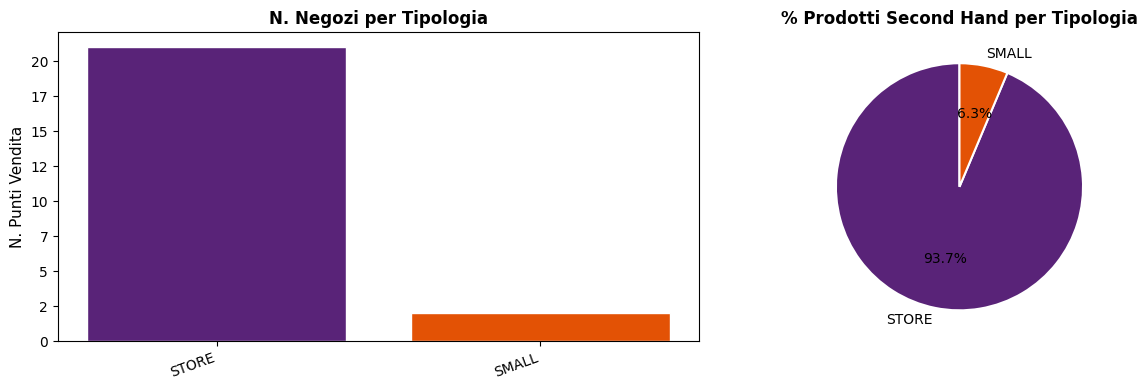

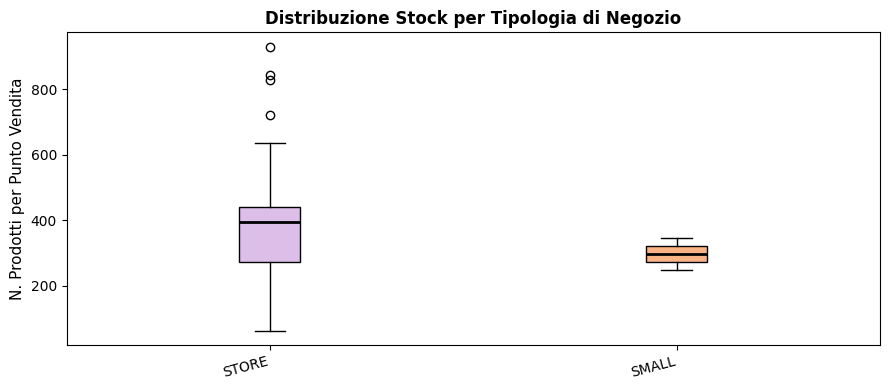

,Provincia Negozio,N. Negozi,N. Prodotti
1,ITMI,3,1799
2,ITRM,3,1204


,Provincia Negozio,N. Negozi,N. Prodotti
0,ITMI,3,1799
1,ITRM,3,1204
2,ITAN,1,112
3,ITBO,1,314
4,ITBA,1,844
5,ITCH,1,201
6,ITBS,1,177
7,ITCT,1,830
8,ITFI,1,286
9,ITGE,1,145


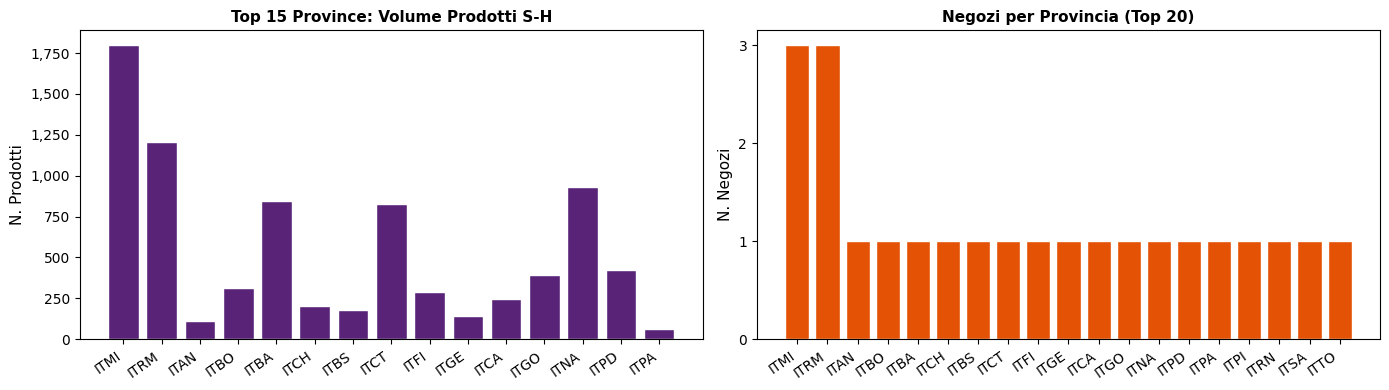

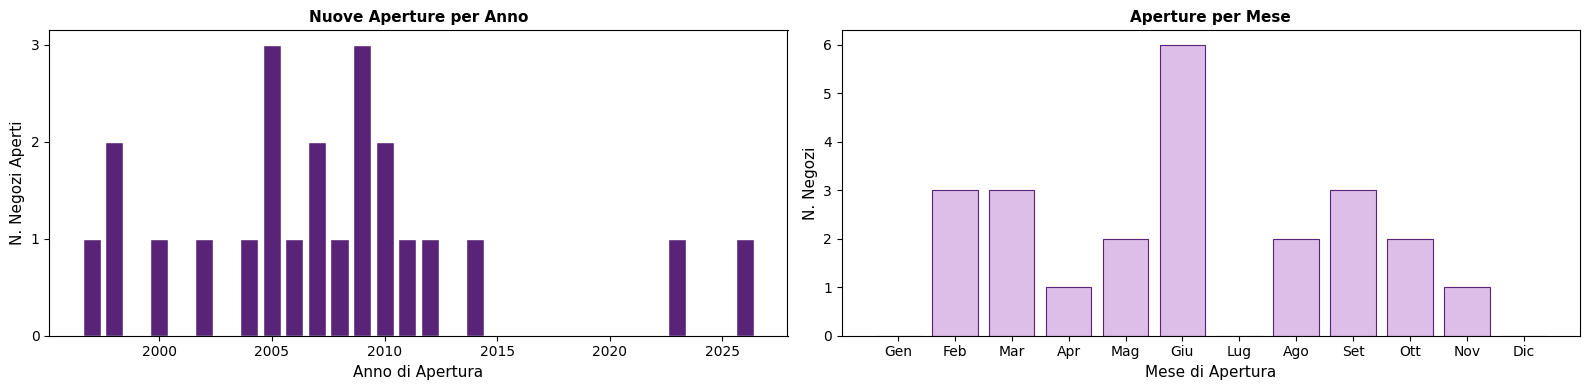

In [ ]:
# APPROFONDIMENTO: ANALISI MULTIVARIATA DEI PUNTI VENDITA
display(HTML("<h3><b>ANALISI MULTIVARIATA NEGOZI (Prima del Pruning)</b></h3>"))

colonne_negozio_check = ['ID Negozio', 'Nome Negozio','Tipologia Negozio','Città Negozio','Provincia Negozio','Data Apertura Negozio']
colonne_neg_presenti = [c for c in colonne_negozio_check if c in df.columns]

if not colonne_neg_presenti:
    display(HTML("<i>Colonne negozio già rimosse. Analisi non eseguibile.</i>"))

else:
    # Costruzione dataset univoco dei negozi
    freq_neg2 = df['Nome Negozio'].value_counts().reset_index()
    freq_neg2.columns = ['Nome Negozio', 'Frequenza']

    df_neg2 = (df[colonne_neg_presenti].drop_duplicates(subset=['Nome Negozio']).merge(freq_neg2, on='Nome Negozio').sort_values('Frequenza', ascending=False).reset_index(drop=True))

    # -----------------------------------------------------------------------------
    # Analisi 1: Tipologia Negozi
    if 'Tipologia Negozio' in df.columns:

        display(HTML("<h4>Distribuzione per Tipologia di Negozio</h4>"))

        tipo_prod = df['Tipologia Negozio'].value_counts(dropna=False).reset_index()
        tipo_prod.columns = ['Tipologia', 'N. Prodotti']
        tipo_prod['% Prodotti'] = (tipo_prod['N. Prodotti'] / len(df) * 100).round(2)

        tipo_neg = df_neg2['Tipologia Negozio'].value_counts().reset_index()
        tipo_neg.columns = ['Tipologia', 'N. Negozi']

        tipo_tab = (tipo_prod.merge(tipo_neg, on='Tipologia').sort_values('N. Prodotti', ascending=False))

        tipo_tab['% Negozi'] = (tipo_tab['N. Negozi'] / tipo_tab['N. Negozi'].sum() * 100).round(2)

        tipo_tab.index = range(1, len(tipo_tab) + 1)

        display(tipo_tab[['Tipologia', 'N. Negozi', '% Negozi', 'N. Prodotti', '% Prodotti']])

        # Grafici
        colori_tipo = [ '#592378', '#e35205', '#dcbee9', '#f9b384', '#8e44ad', '#27ae60', '#2980b9']
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))

        axes[0].bar(tipo_tab['Tipologia'].astype(str),tipo_tab['N. Negozi'],color=colori_tipo[:len(tipo_tab)],edgecolor='white')
        axes[0].set_ylabel('N. Punti Vendita', fontsize=11)
        axes[0].set_title('N. Negozi per Tipologia',fontsize=12,fontweight='bold')

        axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

        plt.setp(axes[0].get_xticklabels(), rotation=20, ha='right')

        axes[1].pie(tipo_tab['N. Prodotti'],labels=tipo_tab['Tipologia'],colors=colori_tipo[:len(tipo_tab)],autopct='%1.1f%%',startangle=90,wedgeprops=dict(edgecolor='white',linewidth=1.5))

        axes[1].set_title('% Prodotti Second Hand per Tipologia',fontsize=12,fontweight='bold')

        plt.tight_layout()
        plt.show()

        # Boxplot Stock per Tipologia

        if df_neg2['Tipologia Negozio'].nunique() > 1:

            display(HTML("<b>Distribuzione dello Stock per Tipologia:</b>"))

            tipologie_uniche = (df_neg2['Tipologia Negozio'].dropna().unique())

            gruppi = [df_neg2.loc[df_neg2['Tipologia Negozio'] == t,'Frequenza'].values for t in tipologie_uniche]

            gruppi = [(t, g) for t, g in zip(tipologie_uniche, gruppi) if len(g) > 0]

            fig, ax = plt.subplots(figsize=(9, 4))

            bp = ax.boxplot([g for _, g in gruppi], tick_labels=[t for t, _ in gruppi], patch_artist=True, medianprops=dict(color='black',linewidth=2))

            colori_box = ['#dcbee9','#f9b384','#c8e6c9','#bbdefb','#ffe082']

            for patch, color in zip(bp['boxes'], colori_box):
                patch.set_facecolor(color)

            ax.set_ylabel('N. Prodotti per Punto Vendita',fontsize=11)
            ax.set_title('Distribuzione Stock per Tipologia di Negozio',fontsize=12,fontweight='bold')
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
            plt.xticks(rotation=15, ha='right')
            plt.tight_layout()
            plt.show()

            # Test Kruskal-Wallis 
            vettori = [g for _, g in gruppi if len(g) >= 2]
            if len(vettori) >= 2:
                stat, p_val = kruskal(*vettori)
                interp = ( "differenza statisticamente significativa" if p_val < 0.05 else "nessuna differenza significativa")

                display(HTML(f"<ul> <li> <b>Test di Kruskal-Wallis</b> sullo stock per tipologia: "
                    f"H = {stat:.2f}, p-value = {p_val:.4f} → "
                    f"<b>{interp}</b> tra tipologie (α = 0.05)."
                    f"</li> </ul>"))

    display(HTML("<hr style='border-top:2px solid #d3d3d3; margin:20px 0;'>"))
    # -----------------------------------------------------------------------------

    # -----------------------------------------------------------------------------
    # Analisi 2: Distribuzione Geografica
    if 'Provincia Negozio' in df.columns:

        display(HTML("<h4>Distribuzione Geografica per Provincia</h4>"))
        prov_neg = (df_neg2.groupby('Provincia Negozio').size().reset_index(name='N. Negozi').sort_values('N. Negozi', ascending=False))
        prov_prod = (df.groupby('Provincia Negozio').size().reset_index(name='N. Prodotti'))
        prov_tab = prov_neg.merge(prov_prod,on='Provincia Negozio')
        prov_tab['Negozi Multipli'] = prov_tab['N. Negozi'].apply(lambda x: '✔' if x > 1 else '')
        prov_tab.index = range(1, len(prov_tab) + 1)

        display(HTML("<b>Province con più di un punto vendita:</b>"))
        multi = (prov_tab[prov_tab['N. Negozi'] > 1].reset_index(drop=True))
        multi.index = multi.index + 1
        if len(multi) > 0:
            display(multi[['Provincia Negozio', 'N. Negozi', 'N. Prodotti']])
        else:
            display(HTML("<i>Nessuna provincia presenta più di un punto vendita.</i>"))

        # Top province
        display(HTML("<br><b>Top 15 Province per Volume Prodotti Second Hand:</b>"))
        top15 = prov_tab.head(15)

        display(top15[['Provincia Negozio', 'N. Negozi', 'N. Prodotti']].reset_index(drop=True))

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Barplot prodotti
        axes[0].bar(top15['Provincia Negozio'].astype(str),top15['N. Prodotti'],color='#592378',edgecolor='white')
        axes[0].set_ylabel('N. Prodotti', fontsize=11)
        axes[0].set_title('Top 15 Province: Volume Prodotti S-H',fontsize=11,fontweight='bold')
        axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

        plt.setp(axes[0].get_xticklabels(),rotation=35,ha='right')

        # Barplot negozi
        prov_all = (prov_tab.sort_values('N. Negozi', ascending=False).head(20))
        axes[1].bar(prov_all['Provincia Negozio'].astype(str),prov_all['N. Negozi'],color='#e35205',edgecolor='white')
        axes[1].set_ylabel('N. Negozi', fontsize=11)
        axes[1].set_title('Negozi per Provincia (Top 20)',fontsize=11,fontweight='bold')
        plt.setp(axes[1].get_xticklabels(),rotation=35,ha='right')
        axes[1].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
        plt.tight_layout()
        plt.show()

    display(HTML("<hr style='border-top:2px solid #d3d3d3; margin:20px 0;'>"))
    # -----------------------------------------------------------------------------

    # -----------------------------------------------------------------------------
    # Analisi 3: Date di Apertura
    if 'Data Apertura Negozio' in df.columns:
        display(HTML("<h4>Analisi delle Date di Apertura dei Punti Vendita</h4>"))

        ap = df_neg2[['Nome Negozio', 'Data Apertura Negozio', 'Frequenza']].copy()

        # Parsing date 
        ap['Data Apertura dt'] = pd.to_datetime(ap['Data Apertura Negozio'],errors='coerce')

        # FIX timezone-aware vs timezone-naive
        ap['Data Apertura dt'] = (ap['Data Apertura dt'].dt.tz_localize(None))

        ap_ok = ap.dropna(subset=['Data Apertura dt']).copy()

        ap_ok['Anno'] = ap_ok['Data Apertura dt'].dt.year
        ap_ok['Mese'] = ap_ok['Data Apertura dt'].dt.month

        n_con_data = len(ap_ok)
        n_senza_data = len(ap) - n_con_data

        display(HTML(f"Negozi con data di apertura nota: "
            f"<b>{n_con_data}</b> &nbsp;|&nbsp; "
            f"Senza data: <b>{n_senza_data}</b> &nbsp;|&nbsp; "
            f"Apertura più antica: "
            f"<b>{ap_ok['Data Apertura dt'].min().date()}</b> "
            f"&nbsp;|&nbsp; "
            f"Più recente: "
            f"<b>{ap_ok['Data Apertura dt'].max().date()}</b>"))

        if not ap_ok.empty:
            fig, axes = plt.subplots(1, 2, figsize=(16, 4))

            # Aperture per anno 
            anni_counts = ap_ok.groupby('Anno').size()
            axes[0].bar(anni_counts.index,anni_counts.values,color='#592378',edgecolor='white')
            axes[0].set_xlabel('Anno di Apertura',fontsize=11)
            axes[0].set_ylabel('N. Negozi Aperti',fontsize=11)
            axes[0].set_title('Nuove Aperture per Anno',fontsize=11,fontweight='bold')
            axes[0].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

            # Distribuzione mensile
            mesi_labels = ['Gen', 'Feb', 'Mar', 'Apr', 'Mag', 'Giu', 'Lug', 'Ago', 'Set', 'Ott', 'Nov', 'Dic']
            mesi_counts = (ap_ok.groupby('Mese').size().reindex(range(1, 13), fill_value=0))
            axes[1].bar(mesi_labels,mesi_counts.values,color='#dcbee9',edgecolor='#592378',linewidth=0.8)
            axes[1].set_xlabel('Mese di Apertura',fontsize=11)
            axes[1].set_ylabel('N. Negozi',fontsize=11)
            axes[1].set_title('Aperture per Mese',fontsize=11,fontweight='bold')
            axes[1].yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
            plt.tight_layout()
            plt.show()
    # -----------------------------------------------------------------------------

    display(HTML("Analisi Negozi completata. Si procede con il <b>pruning relazionale</b>."))

In [ ]:
# PRUNING RELAZIONALE EFFETTIVO
display(HTML("<h3><b>PRUNING RELAZIONALE: RIMOZIONE COLONNE ANAGRAFICHE</b></h3>"))

colonne_negozio_all = ['ID Negozio','Città Negozio','Provincia Negozio','Data Apertura Negozio']
colonne_da_rm = [c for c in colonne_negozio_all if c in df.columns]

if colonne_da_rm:
    df.drop(columns=colonne_da_rm, inplace=True)
    display(HTML(f"<ul> <li><b>Pruning Eseguito</b>. Colonne rimosse: <i>{', '.join(colonne_da_rm)}</i>.</li>"
        f"<li>L'identificazione del punto vendita è ora affidata a <code>Nome Negozio</code> e alla sua dimensione strategica <code>Tipologia Negozio</code>.</li> </ul>"))
else:
    display(HTML("<i>Nessuna colonna anagrafica residua da rimuovere.</i>"))

display(HTML(f"<b>Assetto aggiornato del dataset prodotti</b>: <b>{df.shape[0]}</b> righe × <b>{df.shape[1]}</b> colonne."))

## **3.2. Analisi statistica descrittiva**

Conclusa la fase di data cleaning e feature engineering, il dataset conta 20 colonne nella sua forma definitiva. Si procede con l'**analisi statistica descrittiva** del dataset, condotta in funzione delle differenti nature delle variabili di studio.

| Categoria | Colonne |
|-----------|---------|
| **Identificatori** | `ID Prodotto`, `Numero Articolo Catalogo` |
| **Numeriche** | `Disponibilità`, `Prezzo Originale`, `Prezzo Scontato`, `Sconto` |
| **Booleana** | `Imballaggio Presente` |
| **Categoriali** | `Condizione Usato`, `Motivo Vendita`, `Classe Energetica`, `Nome Negozio`, `Tipologia Negozio` |
| **Testuali** | `Descrizione Completa`, `Note Extra Usato`, `Designer`, `Materiali`, `Cura`, `Buono a sapersi + Sicurezza e conformità`, `Informazioni Tecniche`, `Misure`  |

In [ ]:
# CLASSIFICAZIONE RAGIONATA DELLE VARIABILI
COL_ID = ['ID Prodotto', 'Numero Articolo Catalogo',]

COL_NUMERICHE = ['Disponibilità', 'Prezzo Originale', 'Prezzo Scontato', 'Sconto',]

COL_BOOLEANE = ['Imballaggio Presente',]

COL_CATEGORIALI = ['Condizione Usato', 'Motivo Vendita', 'Classe Energetica', 'Nome Negozio', 'Tipologia Negozio',]

COL_TESTO = ['Descrizione Completa', 'Note Extra Usato', 'Designer', 'Materiali', 'Cura', 'Buono a sapersi + Sicurezza e conformità', 'Informazioni Tecniche', 'Misure',]

# Verifica: tutte le colonne del df sono coperte 
TUTTE = COL_ID + COL_NUMERICHE + COL_BOOLEANE + COL_CATEGORIALI + COL_TESTO
colonne_non_coperte = set(df.columns).symmetric_difference(set(TUTTE))
assert not colonne_non_coperte, f"Colonne non coperte o extra: {colonne_non_coperte}"

# Tabella di riepilogo
display(HTML("<h3><b>CLASSIFICAZIONE RAGIONATA DELLE COLONNE</b></h3>"))

MAPPA_CATEGORIA = {**{c: 'Identificatore'  for c in COL_ID}, **{c: 'Numerica' for c in COL_NUMERICHE},  **{c: 'Booleana' for c in COL_BOOLEANE}, **{c: 'Categoriale' for c in COL_CATEGORIALI}, **{c: 'Testuale' for c in COL_TESTO},}

COLORI_CAT = {'Identificatore' : '#f5f5f5', 'Numerica' : '#dcbee9', 'Booleana' : '#c8e6c9', 'Categoriale' : '#bbdefb', 'Testuale' : '#ffe0b2',}

righe = []
for col in df.columns:
    cat = MAPPA_CATEGORIA[col]
    n_uniq = df[col].nunique(dropna=True)
    n_miss  = df[col].isna().sum()
    perc_miss = round(n_miss / len(df) * 100, 2)
    righe.append({'Colonna' : col,'Categoria' : cat,'Valori Distinti': n_uniq,'Missing (%)' : perc_miss,})

df_class = pd.DataFrame(righe)
df_class.index = df_class.index + 1

th = "style='padding:9px 12px; border:1px solid #ccc;'"
td = "style='padding:8px 12px; border:1px solid #ccc;'"
td_it = "style='padding:8px 12px; border:1px solid #ccc; font-style:italic; color:#555;'"

h = "<table style='border-collapse:collapse; width:100%; color:black; font-family:inherit;'>"
h += (f"<tr style='background-color:#592378; color:white; font-weight:bold; text-align:left;'>"
      f"<th {th}>#</th><th {th}>Colonna</th><th {th}>Categoria</th>"
      f"<th {th}>Valori Distinti</th><th {th}>Missing (%)</th></tr>")

for i, row in df_class.iterrows():
    bg = COLORI_CAT.get(row['Categoria'], '#ffffff')
    h += (f"<tr style='background-color:{bg};'>"
          f"<td {td}>{i}</td>"
          f"<td {td}><code>{row['Colonna']}</code></td>"
          f"<td {td}><b>{row['Categoria']}</b></td>"
          f"<td {td}>{row['Valori Distinti']}</td>"
          f"<td {td}>{row['Missing (%)']}%</td>")
h += "</table>"
display(HTML(h))

# Riepilogo conteggi per categoria
display(HTML("<br><b>Riepilogo:</b> " + " &nbsp;|&nbsp; ".join([f"{cat}: <b>{sum(1 for c in TUTTE if MAPPA_CATEGORIA[c]==cat)}</b>" for cat in ['Identificatore','Numerica','Booleana','Categoriale','Testuale']])))

#,Colonna,Categoria,Valori Distinti,Missing (%)
1,ID Prodotto,Identificatore,9407,0.0%
2,Numero Articolo Catalogo,Identificatore,3371,0.0%
3,Note Extra Usato,Testuale,835,63.59%
4,Disponibilità,Numerica,22,0.0%
5,Condizione Usato,Categoriale,6,3.54%
6,Imballaggio Presente,Booleana,2,6.74%
7,Motivo Vendita,Categoriale,9,0.37%
8,Classe Energetica,Categoriale,11,0.0%
9,Prezzo Originale,Numerica,239,0.0%
10,Prezzo Scontato,Numerica,676,0.0%


In [ ]:
# VARIABILI NUMERICHE
display(HTML("<h3><b>VARIABILI NUMERICHE</b></h3>"))

col_num = [c for c in COL_NUMERICHE if c in df.columns]
display(HTML("<b>Controllo Coerenza Pre-Analisi:</b>"))

# Valori zero o negativi su colonne che non dovrebbero averli
col_no_zero = ['Prezzo Originale', 'Prezzo Scontato', 'Disponibilità']
for col in [c for c in col_no_zero if c in df.columns]:
    n_zero     = (df[col] == 0).sum()
    n_negativi = (df[col] < 0).sum()
    if n_zero > 0 or n_negativi > 0:
        display(HTML(f"<ul><li><code>{col}</code>: <b>{n_zero}</b> valori = 0, <b>{n_negativi}</b> valori negativi. Campione dei record con valore zero:</li></ul>"))
        campione_zero = df[df[col] == 0][col_num].head(5)
        campione_zero.index = campione_zero.index + 1
        display(campione_zero)
    else:
        display(HTML(f"<ul><li><code>{col}</code>: nessun valore zero o negativo.</li></ul>"))

# Coerenza Prezzo Scontato ≤ Prezzo Originale
if 'Prezzo Originale' in df.columns and 'Prezzo Scontato' in df.columns:
    mask_incoerente = df['Prezzo Scontato'] > df['Prezzo Originale']
    n_inc = mask_incoerente.sum()
    if n_inc > 0:
        display(HTML(f"<ul><li><b>Attenzione</b>: {n_inc} record con <code>Prezzo Scontato</code> &gt; <code>Prezzo Originale</code>. Campione:</li></ul>"))
        display(df[mask_incoerente][['Prezzo Originale', 'Prezzo Scontato', 'Sconto']].head(5))
    else:
        display(HTML("<ul><li>Coerenza Prezzo Scontato ≤ Prezzo Originale: verificata su tutti i record. ✔</li></ul>"))

,Disponibilità,Prezzo Originale,Prezzo Scontato,Sconto
7088,1,0.0,89.9,NaN
7125,1,0.0,59.9,NaN


,Prezzo Originale,Prezzo Scontato,Sconto
7087,0.0,89.9,NaN
7124,0.0,59.9,NaN


In [14]:
# Rimozione record con Prezzo Originale = 0
mask_prezzo_zero = df['Prezzo Originale'] == 0
n_rimossi = mask_prezzo_zero.sum()

if n_rimossi > 0:
    display(HTML(f"<ul><li><b>Rimozione record anomali</b>: eliminati <b>{n_rimossi}</b> record con <code>Prezzo Originale = 0</code> (artefatto di scraping). Dataset aggiornato: <b>{len(df) - n_rimossi}</b> righe.</li></ul>"))
    df = df[~mask_prezzo_zero].reset_index(drop=True)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,missing %
Disponibilità,9405.0,3.549,3.972,1.0,1.0,2.0,4.0,26.0,2.348,6.147,0.0
Prezzo Originale,9405.0,51.672,80.363,1.0,13.0,25.0,56.0,1599.0,5.647,56.514,0.0
Prezzo Scontato,9405.0,28.150,43.075,0.7,7.2,14.9,30.0,1120.0,6.226,80.184,0.0
Sconto,9405.0,42.218,12.023,0.0,34.0,39.0,50.0,80.0,1.062,0.935,0.0


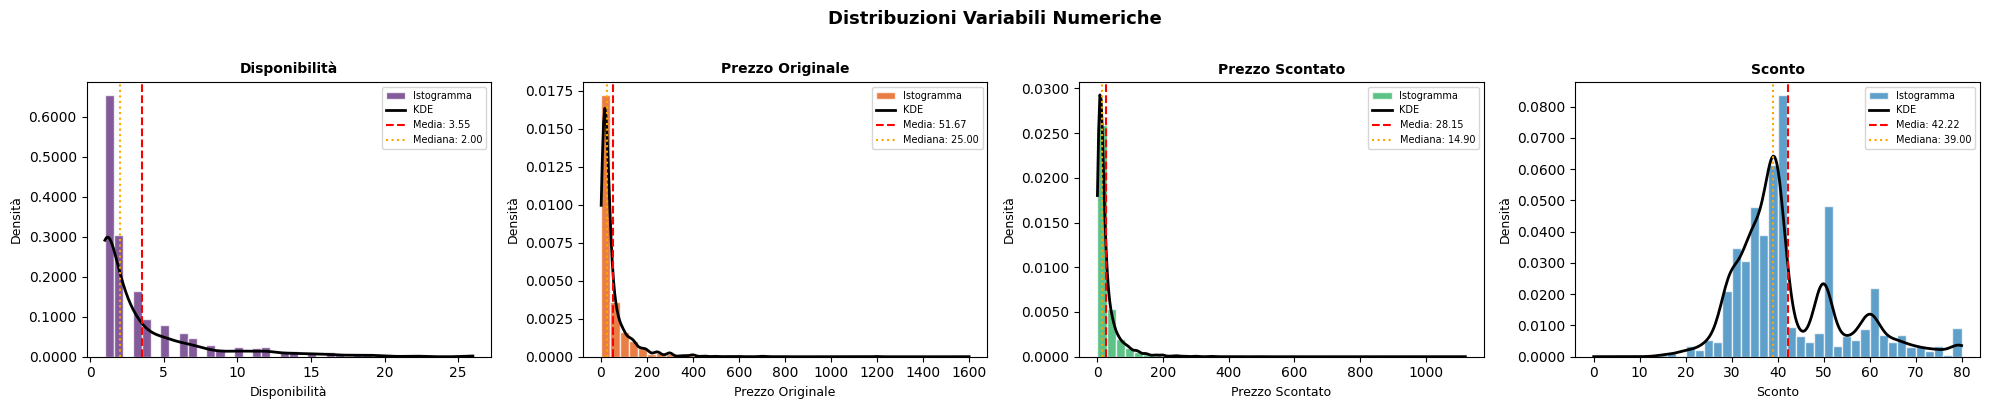

,Colonna,Q1,Q3,IQR,Soglia Inf,Soglia Sup,N. Outlier,% Outlier
1,Disponibilità,1.0,4.0,3.0,-3.5,8.5,984,10.46
2,Prezzo Originale,13.0,56.0,43.0,-51.5,120.5,968,10.29
3,Prezzo Scontato,7.2,30.0,22.8,-27.0,64.2,988,10.51
4,Sconto,34.0,50.0,16.0,10.0,74.0,221,2.35


,Disponibilità,Prezzo Originale,Prezzo Scontato,Sconto
Disponibilità,1.000,-0.180,-0.194,0.145
Prezzo Originale,-0.180,1.000,0.959,0.156
Prezzo Scontato,-0.194,0.959,1.000,-0.001
Sconto,0.145,0.156,-0.001,1.000


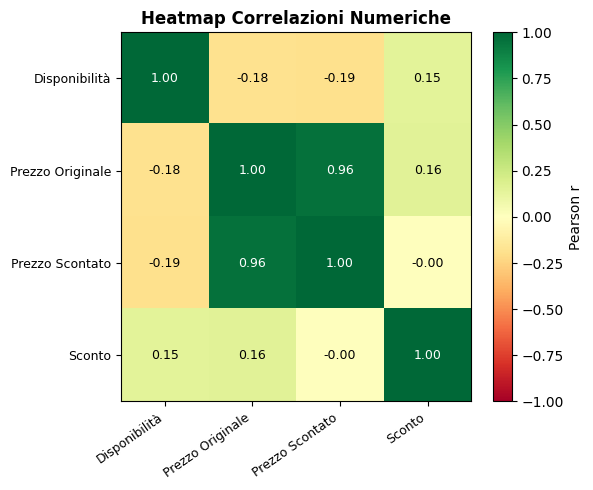

In [ ]:
# ANALISI DELLE VARIABILI NUMERICHE
display(HTML("<h3><b>VARIABILI NUMERICHE</b></h3>"))

col_num = [c for c in COL_NUMERICHE if c in df.columns]

# Statistiche descrittive estese
display(HTML("<b>Statistiche Descrittive Estese:</b>"))
desc = df[col_num].describe().T
desc['skewness']  = df[col_num].skew().round(3)
desc['kurtosis']  = df[col_num].kurtosis().round(3)
desc['missing %'] = (df[col_num].isna().sum() / len(df) * 100).round(2)
display(desc.round(3))

# Istogrammi + KDE
display(HTML("<br><b>Distribuzioni (Istogramma + KDE):</b>"))
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(1, len(col_num), figsize=(5 * len(col_num), 4))
if len(col_num) == 1:
    axes = [axes]
colori_num = ['#592378', '#e35205', '#27ae60', '#2980b9']

for i, col in enumerate(col_num):
    s = df[col].dropna()
    axes[i].hist(s, bins=40, color=colori_num[i % len(colori_num)], edgecolor='white', density=True, alpha=0.75, label='Istogramma')
    try:
        kde = gaussian_kde(s)
        x_r = np.linspace(s.min(), s.max(), 300)
        axes[i].plot(x_r, kde(x_r), color='black', linewidth=2, label='KDE')
    except Exception:
        pass
    axes[i].axvline(s.mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Media: {s.mean():.2f}')
    axes[i].axvline(s.median(), color='orange', linestyle=':',  linewidth=1.5, label=f'Mediana: {s.median():.2f}')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel('Densità', fontsize=9)
    axes[i].legend(fontsize=7)
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.4f}'))

plt.suptitle('Distribuzioni Variabili Numeriche', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Outlier Detection via IQR 
display(HTML("<br><b>Outlier Detection via IQR (1.5 × IQR):</b>"))
out_rows = []
for col in col_num:
    s = df[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)).sum()
    out_rows.append({'Colonna': col, 'Q1' : round(Q1, 3), 'Q3' : round(Q3, 3), 'IQR' : round(IQR, 3), 'Soglia Inf' : round(Q1 - 1.5 * IQR, 3), 'Soglia Sup' : round(Q3 + 1.5 * IQR, 3), 'N. Outlier' : int(n_out), '% Outlier'  : round(n_out / len(df) * 100, 2),})

df_out = pd.DataFrame(out_rows)
df_out.index = df_out.index + 1
display(df_out)

# Matrice di correlazione
if len(col_num) >= 2:
    display(HTML("<br><b>Matrice di Correlazione di Pearson:</b>"))
    corr = df[col_num].corr()
    display(corr.round(3).style.background_gradient(cmap='RdYlGn', vmin=-1, vmax=1).format("{:.3f}"))
    fig, ax = plt.subplots(figsize=(len(col_num) + 2, len(col_num) + 1))
    im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
    plt.colorbar(im, ax=ax, label='Pearson r')
    ax.set_xticks(range(len(col_num))); ax.set_yticks(range(len(col_num)))
    ax.set_xticklabels(col_num, rotation=35, ha='right', fontsize=9)
    ax.set_yticklabels(col_num, fontsize=9)
    for r in range(len(col_num)):
        for c in range(len(col_num)):
            v = corr.values[r, c]
            ax.text(c, r, f'{v:.2f}', ha='center', va='center', fontsize=9, color='white' if abs(v) > 0.6 else 'black')
    ax.set_title('Heatmap Correlazioni Numeriche', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

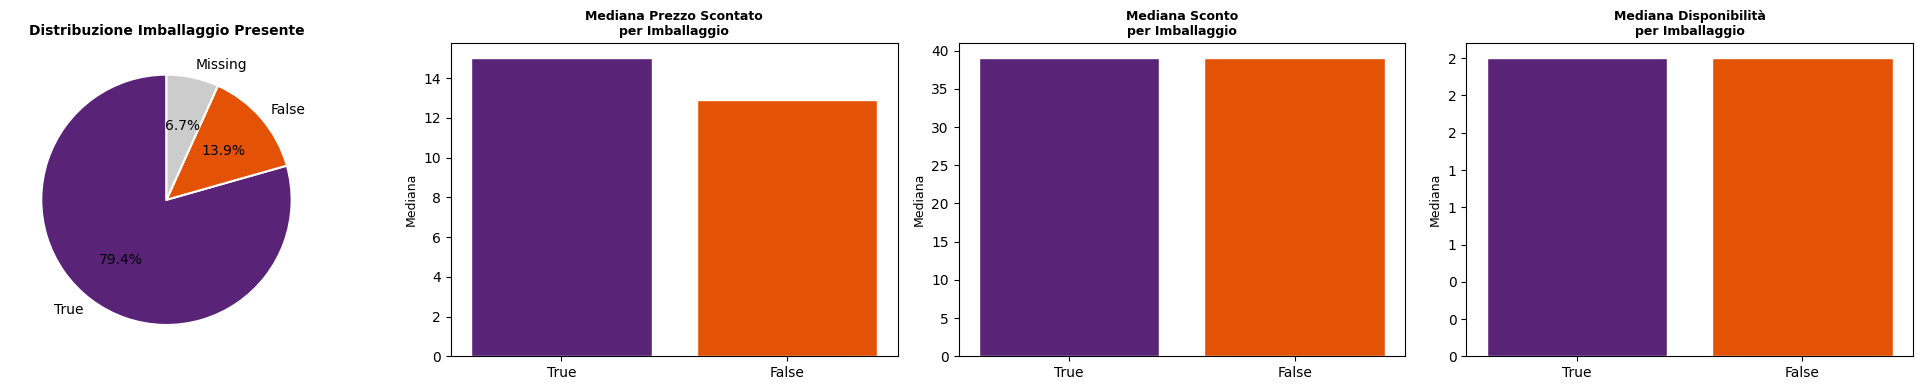

In [ ]:
# ANALISI VARIABILE BOOLEANA
display(HTML("<h3><b>VARIABILE BOOLEANA</b></h3>"))

col_b = 'Imballaggio Presente'
if col_b not in df.columns:
    display(HTML(f"<i>Colonna <code>{col_b}</code> non trovata.</i>"))
else:
    serie_b = df[col_b].astype(str).str.strip().str.lower()
    mask_t  = serie_b.isin(['true', 'yes', 'si', 'sì', '1', 'vero'])
    mask_f  = serie_b.isin(['false', 'no', '0', 'falso'])
    n_t, n_f = mask_t.sum(), mask_f.sum()
    n_miss   = df[col_b].isna().sum()
    tot      = len(df)

    display(HTML(f"<ul> <li><b>True</b> (imballo presente): {n_t:,} record — <b>{n_t/tot*100:.2f}%</b></li>"
        f"<li><b>False</b> (imballo assente):  {n_f:,} record — <b>{n_f/tot*100:.2f}%</b></li>"
        f"<li><b>Missing</b>: {n_miss:,} record — <b>{n_miss/tot*100:.2f}%</b></li> </ul>"))

    # Solo le colonne su cui il confronto ha senso nel contesto usato
    COL_CONFRONTO = ['Prezzo Scontato', 'Sconto', 'Disponibilità']
    col_plot = [c for c in COL_CONFRONTO if c in df.columns]

    n_axes = 1 + len(col_plot)
    fig, axes = plt.subplots(1, n_axes, figsize=(5 * n_axes, 4))
    if n_axes == 1:
        axes = [axes]

    # Torta distribuzione
    labels_pie = [l for l, s in [('True', n_t), ('False', n_f), ('Missing', n_miss)] if s > 0]
    sizes_pie  = [s for s in [n_t, n_f, n_miss] if s > 0]
    colori_pie = ['#592378', '#e35205', '#cccccc'][:len(labels_pie)]
    axes[0].pie(sizes_pie, labels=labels_pie, colors=colori_pie, autopct='%1.1f%%', startangle=90, wedgeprops=dict(edgecolor='white', linewidth=1.5))
    axes[0].set_title('Distribuzione Imballaggio Presente', fontsize=10, fontweight='bold')

    # Bar chart mediane (solo colonne rilevanti)
    for i, col_n in enumerate(col_plot, start=1):
        med_t = df.loc[mask_t, col_n].median()
        med_f = df.loc[mask_f, col_n].median()
        axes[i].bar(['True', 'False'], [med_t, med_f], color=['#592378', '#e35205'], edgecolor='white')
        axes[i].set_title(f'Mediana {col_n}\nper Imballaggio', fontsize=9, fontweight='bold')
        axes[i].set_ylabel('Mediana', fontsize=9)
        axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

    plt.tight_layout()
    plt.show()
    
    # Test di Mann-Whitney su Sconto
    from scipy.stats import mannwhitneyu
    col_tests = [c for c in ['Sconto'] if c in df.columns]

    for col_test in col_tests:
        g_t = df.loc[mask_t, col_test].dropna()
        g_f = df.loc[mask_f, col_test].dropna()
        if len(g_t) >= 5 and len(g_f) >= 5:
            stat, p = mannwhitneyu(g_t, g_f, alternative='two-sided')
            interp = ("differenza statisticamente significativa" if p < 0.05 else "nessuna differenza significativa")
            display(HTML(f"<ul><li><b>Test di Mann-Whitney</b> su <code>{col_test}</code> (True vs False): U = {stat:.0f}, p-value = {p:.4f} → <b>{interp}</b> tra i due gruppi (α = 0.05).</li></ul>"))

In [ ]:
# ANALISI DELLE VARIABILI CATEGORIALI
display(HTML("<h3><b>VARIABILI CATEGORIALI</b></h3>"))

col_cat = [c for c in COL_CATEGORIALI if c in df.columns]

# Tabella di sintesi 
display(HTML("<b>Tabella di Sintesi — Cardinalità e Concentrazione</b>"))
sintesi = []
for col in col_cat:
    n_miss, perc_miss = conta_missing(df[col])          # usa la funzione del cap.2
    s_valida = df[col].dropna().astype(str).str.strip()
    s_valida = s_valida[~s_valida.str.lower().isin(PLACEHOLDER_MISSING)]  # escludi placeholder
    n_uniq   = s_valida.nunique()
    top_val  = s_valida.value_counts().index[0] if not s_valida.empty else 'N/A'
    top_pct  = (s_valida.value_counts().iloc[0] / len(df)) * 100 if not s_valida.empty else 0  # su totale righe
    avg_len  = round(s_valida.str.len().mean(), 1)
    hhi      = round((s_valida.value_counts(normalize=True).values ** 2).sum(), 4)
    sintesi.append({'Colonna' : col, 'N. Valori Unici' : n_uniq, 'Missing (%)' : perc_miss, 'Valore Modale' : str(top_val)[:45], '% Modale' : round(top_pct, 2), 'Lung. Media Etichetta': avg_len, 'HHI' : hhi,})
df_sint = pd.DataFrame(sintesi)
df_sint.index = df_sint.index + 1
display(df_sint)

SOGLIA_BAR = 30

for col in col_cat:
    n_miss, perc_miss = conta_missing(df[col])
    s_valida = df[col].dropna().astype(str).str.strip()
    s_valida = s_valida[~s_valida.str.lower().isin(PLACEHOLDER_MISSING)]
    vc       = s_valida.value_counts()
    n_uniq   = s_valida.nunique()
    display(HTML(f"<hr style='border-top:1px solid #e0e0e0; margin:12px 0;'>"))
    display(HTML(f"<b><code>{col}</code></b> — {n_uniq} valori distinti | Missing (NaN + placeholder): {n_miss} ({perc_miss}%)"))
    top_n  = vc if n_uniq <= SOGLIA_BAR else vc.head(15)
    df_top = top_n.reset_index()
    df_top.columns = [col, 'N.']
    df_top['%'] = (df_top['N.'] / len(df) * 100).round(2)
    df_top.index = df_top.index + 1
    display(df_top)
display(HTML("<hr style='border-top:1px solid #d3d3d3; margin:15px 0;'>"))

,Colonna,N. Valori Unici,Missing (%),Valore Modale,% Modale,Lung. Media Etichetta,HHI
1,Condizione Usato,6,3.54,Nuovissimo,44.54,9.2,0.3652
2,Motivo Vendita,9,0.37,Prodotto fuori produzione,36.97,17.0,0.2629
3,Classe Energetica,10,93.89,Classe di efficienza energetica G,2.17,33.2,0.2216
4,Nome Negozio,23,0.00,Napoli,9.90,11.2,0.0576
5,Tipologia Negozio,2,0.00,STORE,93.66,5.0,0.8813


,Condizione Usato,N.,%
1,Nuovissimo,4189,44.54
2,Come nuovo,3175,33.76
3,Buono,1554,16.52
4,Discreto,84,0.89
5,Seconda scelta,41,0.44
6,Pezzi mancanti,29,0.31


,Motivo Vendita,N.,%
1,Prodotto fuori produzione,3477,36.97
2,Reso cliente,2807,29.85
3,Danneggiato,1217,12.94
4,Esposizione,1204,12.80
5,Prodotto imballato,375,3.99
6,Imballaggio mancante,172,1.83
7,Seconda scelta,101,1.07
8,Incompleto,12,0.13
9,Seconda mano,5,0.05


,Classe Energetica,N.,%
1,Classe di efficienza energetica G,204,2.17
2,Classe di efficienza energetica F,129,1.37
3,Classe di efficienza energetica E,87,0.93
4,Classe di efficienza energetica D,66,0.70
5,Classe di efficienza energetica C,44,0.47
6,Classe di efficienza energetica A+,23,0.24
7,Classe di efficienza energetica A,9,0.10
8,Classe di efficienza energetica per cavità A,5,0.05
9,Classe di efficienza energetica A++,4,0.04
10,Classe di efficienza energetica per cavità A+,2,0.02


,Nome Negozio,N.,%
1,Napoli,931,9.90
2,Bari,844,8.97
3,Catania,830,8.83
4,Milano - San Giuliano,722,7.68
5,Milano - Carugate,635,6.75
6,Milano - Corsico,442,4.70
7,Rome - Porta di Roma,442,4.70
8,Salerno,439,4.67
9,Padova,426,4.53
10,Rome - Anagnina,415,4.41


,Tipologia Negozio,N.,%
1,STORE,8809,93.66
2,SMALL,596,6.34


,Colonna,Copertura (%),Missing (%),Lung. Media (char),Lung. Mediana (char),Parole Medie,Vocabolario Unico
1,Descrizione Completa,100.00,0.00,615.4,539,100.7,8077
2,Note Extra Usato,36.37,63.61,21.8,19,2.8,429
3,Designer,89.71,10.29,24.7,24,4.6,256
4,Materiali,97.98,2.02,74.0,59,10.3,222
5,Cura,94.32,5.68,157.8,135,25.2,632
6,Buono a sapersi + Sicurezza e conformità,99.47,0.53,457.2,381,78.0,3315
7,Informazioni Tecniche,8.63,91.35,562.7,502,90.7,265
8,Misure,84.24,15.75,85.9,75,16.4,181


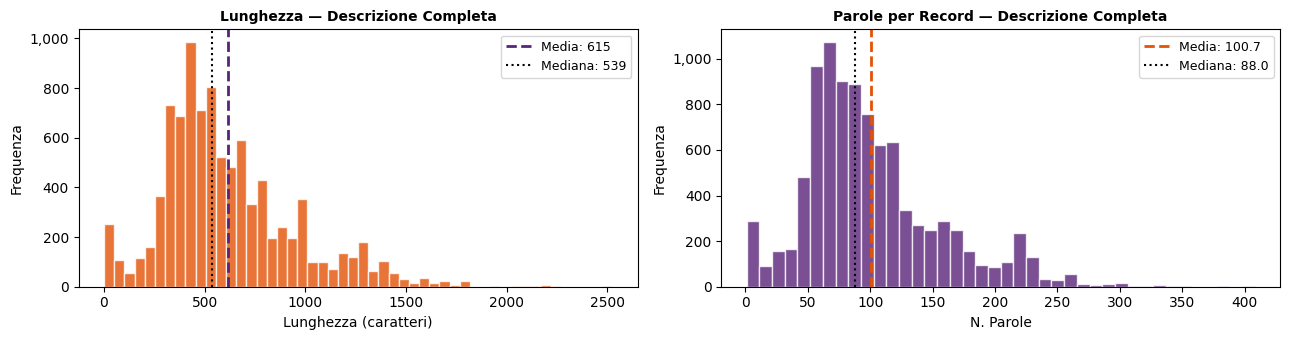

,Token,Freq
1,puoi,8055
2,luce,5014
3,facile,4352
4,fodera,4317
5,facilmente,3732
6,stile,3728
7,bianco,3302
8,cucina,2881
9,resistente,2775
10,led,2766


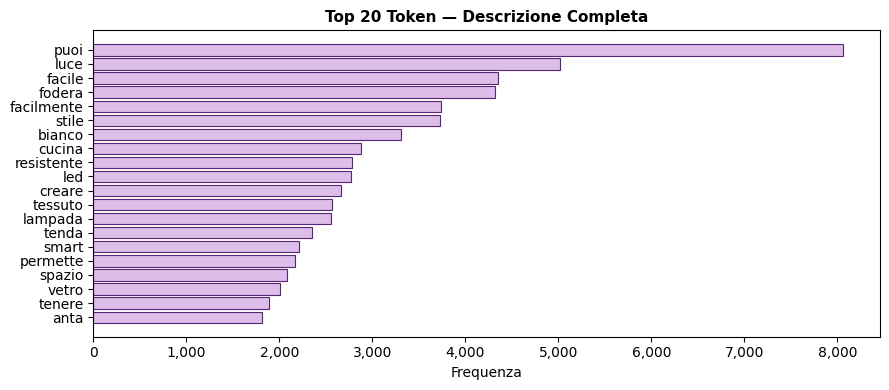

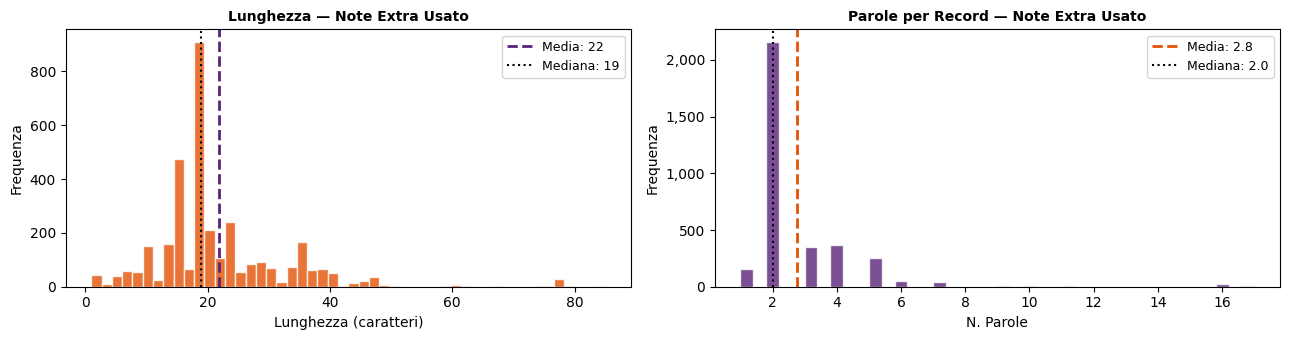

,Token,Freq
1,imballo,1197
2,danneggiato,994
3,imballaggio,450
4,rovinato,401
5,prodotto,357
6,integro,344
7,assortimento,260
8,scatola,181
9,articolo,162
10,cambio,149


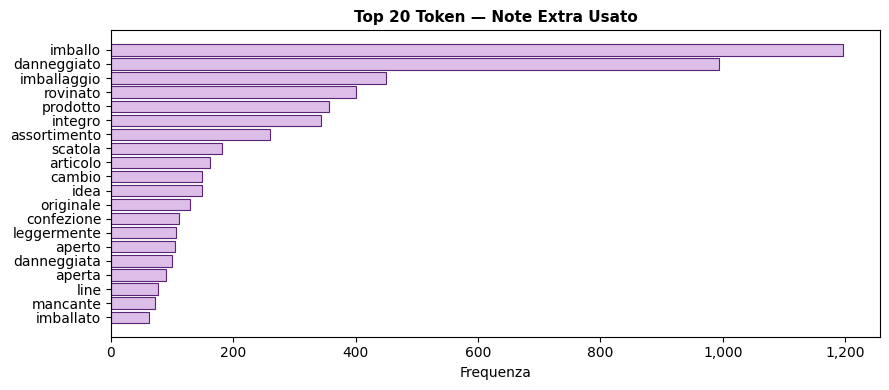

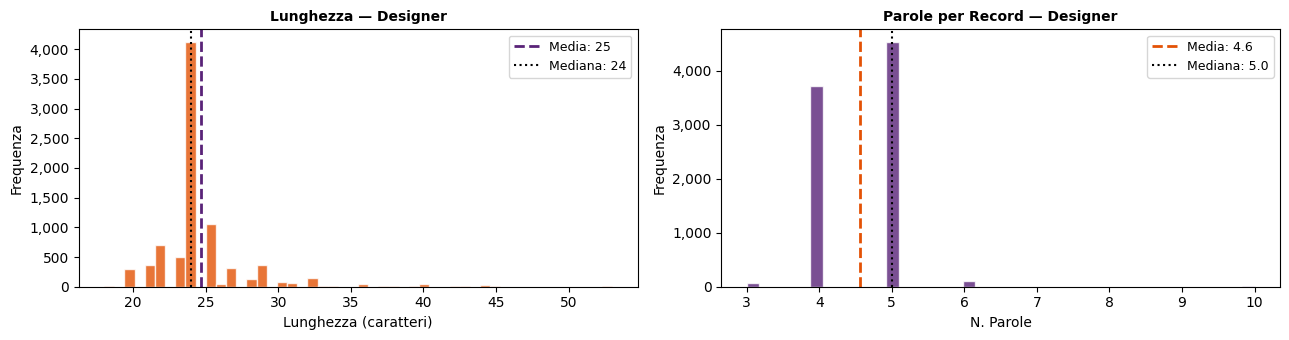

,Token,Freq
1,sweden,3906
2,preutz,581
3,wihlborg,480
4,ola,460
5,johansson,399
6,ehlén,381
7,henrik,334
8,fredriksson,278
9,wahl,272
10,cayouette,270


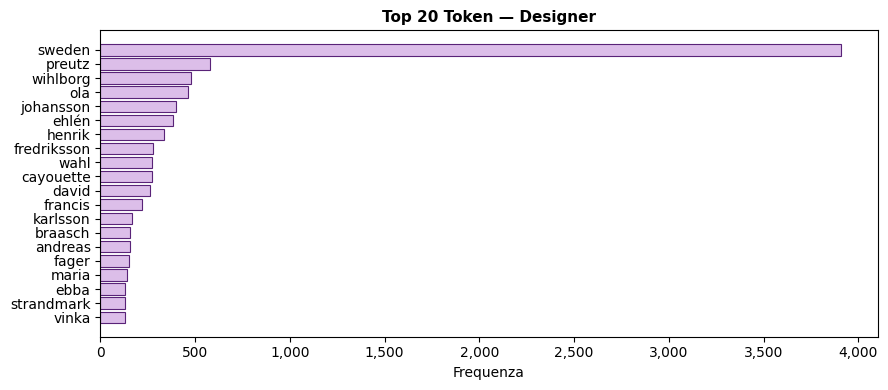

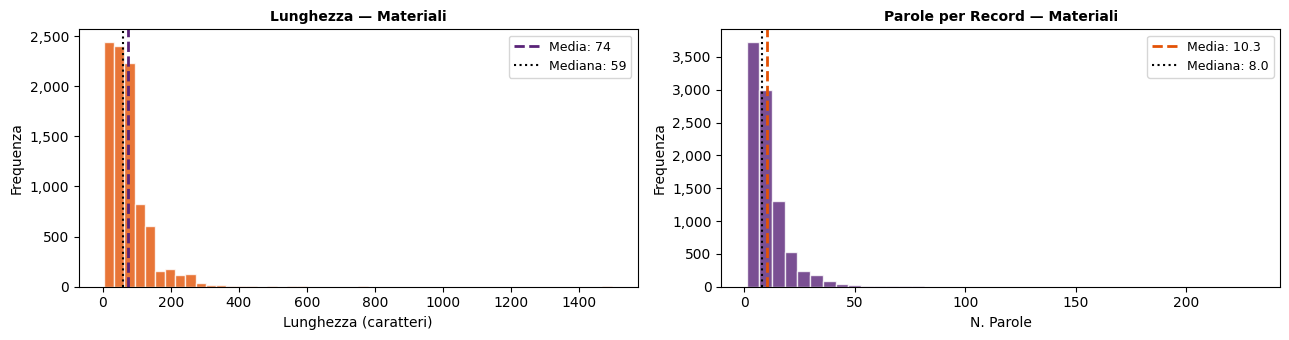

,Token,Freq
1,plastica,4792
2,poliestere,4687
3,riciclato,3481
4,acciaio,3330
5,lamina,2575
6,rivestimento,2315
7,min,2274
8,polvere,2179
9,polipropilene,1899
10,legno,1882


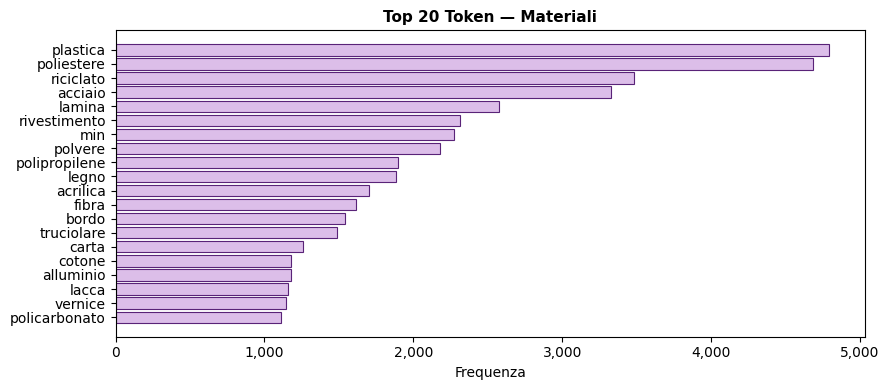

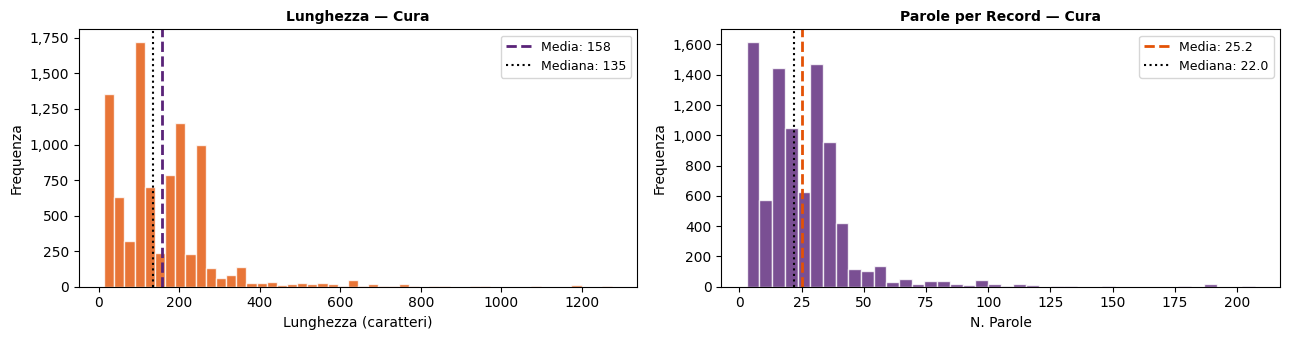

,Token,Freq
1,panno,10049
2,pulisci,6509
3,asciuga,4109
4,max,3971
5,pulito,3943
6,inumidito,3782
7,acqua,3260
8,normale,3070
9,azione,2936
10,meccanica,2936


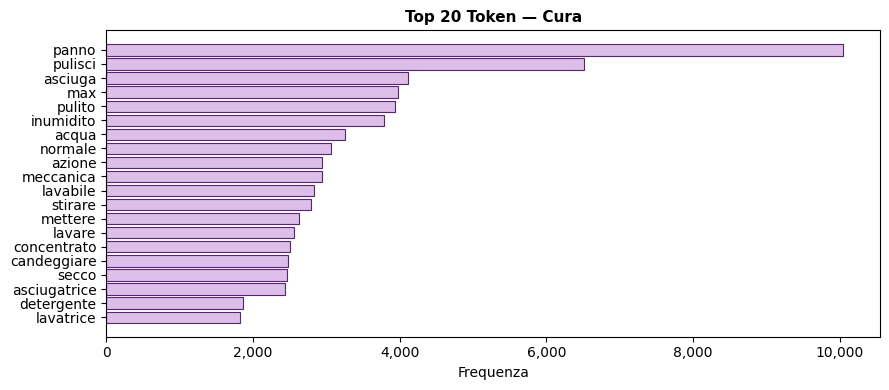

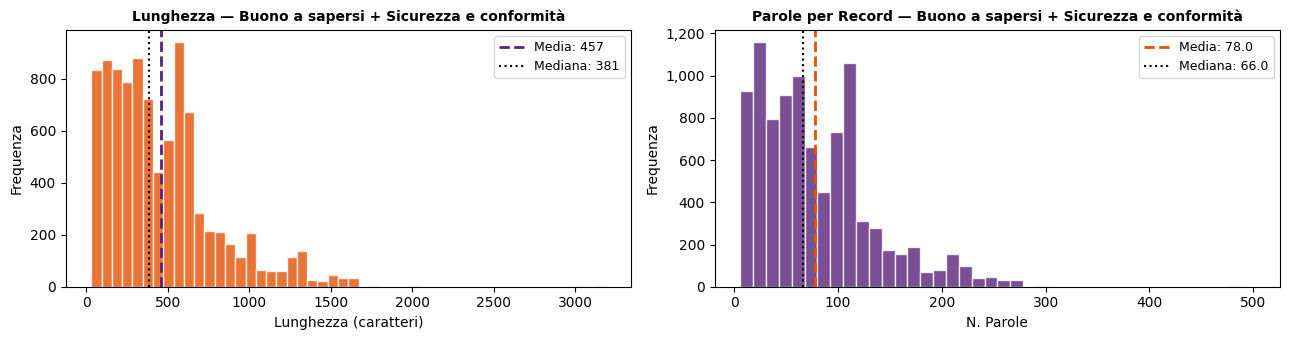

,Token,Freq
1,com,9352
2,sweden,9324
3,prodotto,5740
4,fodera,4125
5,completare,2728
6,accessori,2646
7,luce,2621
8,smart,2591
9,resistere,2569
10,cicli,2435


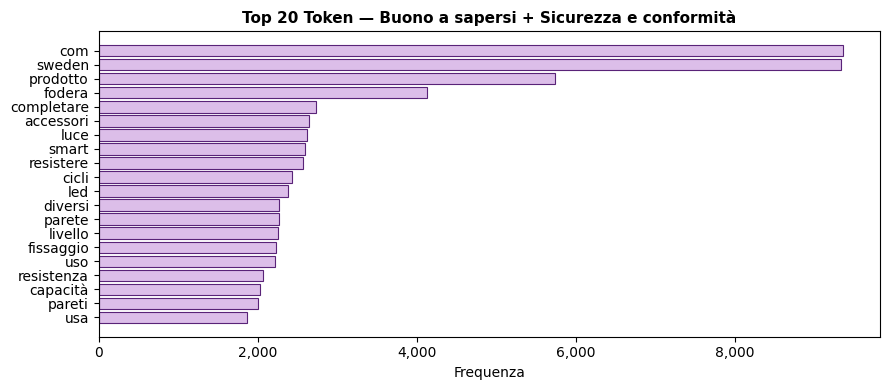

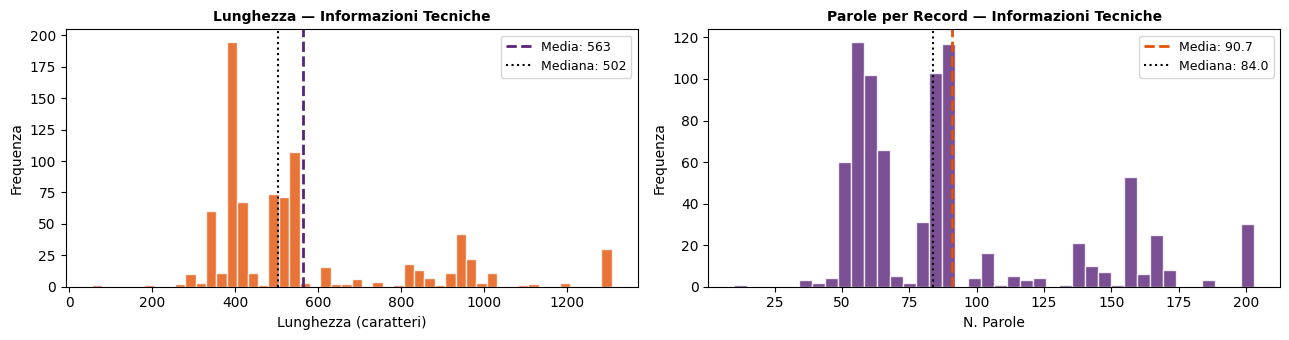

,Token,Freq
1,driver,1820
2,nominale,1519
3,consumo,1502
4,energetico,1178
5,efficienza,979
6,potenza,836
7,modello,737
8,classe,687
9,fonte,686
10,nome,684


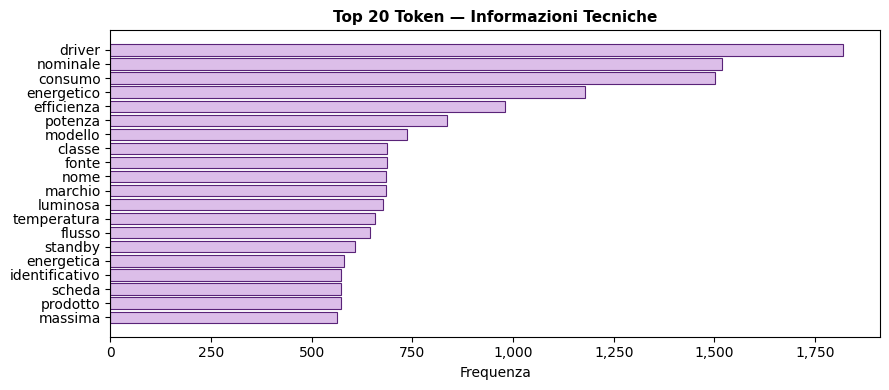

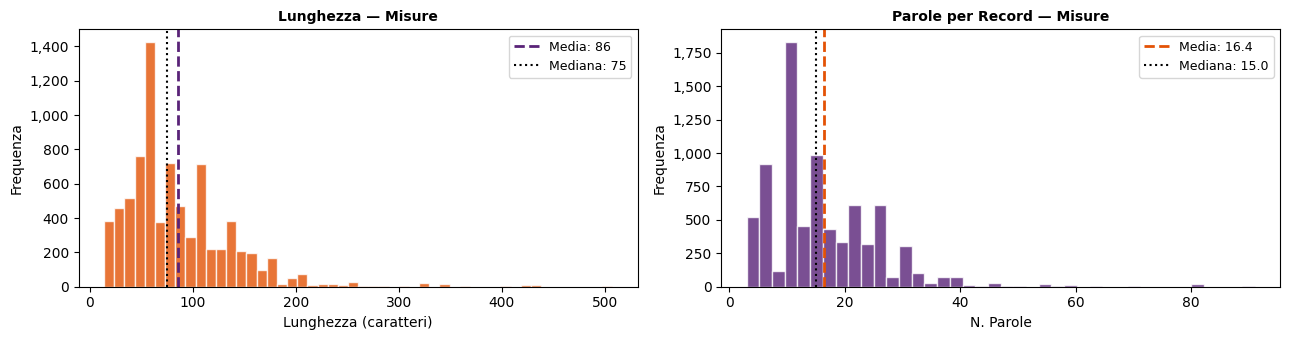

,Token,Freq
1,larghezza,6742
2,altezza,5500
3,lunghezza,4152
4,profondità,3544
5,spessore,1652
6,diametro,1628
7,quantità,1365
8,confezione,1283
9,superficie,981
10,potenza,967


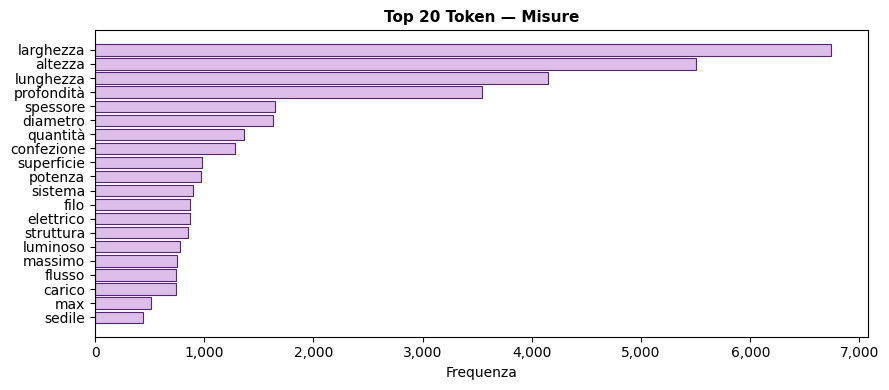

In [ ]:
# ANALISI DELLE VARIABILI TESTUALI

# Token da escludere aggiuntivi rispetto alle stopwords spaCy: numeri puri, unità di misura, residui di parsing tipici di questo dataset
EXTRA_EXCLUDE = {
    # unità e simboli
    'cm', 'mm', 'kg', 'ml', 'cl', 'lt', 'w', 'kw', 'hz', 'db', 'kwh',
    # token numerici e percentuali
    '100', '50', '40', '30', '20', '10', '0', '1', '2', '3', '4', '5',
    # residui separatore pipe e punteggiatura
    '|', '-', '–', '°', '%',
    # generici informativi nel contesto [redacted]
    '[redacted]', 'svezia', 'älmhult',}

def get_stopwords():
    return SW_SPACY | EXTRA_EXCLUDE

# Tokenizza una Serie pandas di testi: lowercasing; rimozione punteggiatura e simboli; rimozione stopwords spaCy + extra; rimozione token numerici puri e token < 3 caratteri
def tokenizza_pulito(serie_testo):
    sw = get_stopwords()
    tokens = (serie_testo.str.lower().str.replace(r'[^\w\s]', ' ', regex=True).str.replace(r'\d+', ' ', regex=True).str.split().explode())
    tokens_clean = tokens[tokens.notna() &(tokens.str.len() > 2) &(~tokens.isin(sw))]
    return tokens_clean

display(HTML("<h3><b>VARIABILI TESTUALI</b></h3>"))
col_testo = [c for c in COL_TESTO if c in df.columns]

# Tabella di sintesi comparativa
display(HTML("<b>Tabella di Sintesi Comparativa:</b>"))
sint_testo = []
for col in col_testo:
    n_miss, perc_miss = conta_missing(df[col]) 
    s = df[col].dropna().astype(str).str.strip()
    s = s[~s.str.lower().isin(PLACEHOLDER_MISSING)]
    chars = s.str.len()
    words = s.str.split().str.len()
    tokens_col = tokenizza_pulito(s)
    vocab = tokens_col.nunique()
    sint_testo.append({
        'Colonna'             : col,
        'Copertura (%)'       : round(len(s) / len(df) * 100, 2),
        'Missing (%)'         : perc_miss,
        'Lung. Media (char)'  : round(chars.mean(), 1),
        'Lung. Mediana (char)': int(chars.median()),
        'Parole Medie'        : round(words.mean(), 1),
        'Vocabolario Unico'   : vocab,})
df_sint_t = pd.DataFrame(sint_testo)
df_sint_t.index = df_sint_t.index + 1
display(df_sint_t)
display(HTML("Vocabolario Unico: token distinti dopo rimozione stopwords spaCy, numeri e unità di misura. Copertura e Missing calcolati sul totale righe del dataset."))

# Analisi individuale per colonna
for col in col_testo:
    n_miss, perc_miss = conta_missing(df[col])
    s = df[col].dropna().astype(str).str.strip()
    s = s[~s.str.lower().isin(PLACEHOLDER_MISSING)]
    display(HTML(f"<hr style='border-top:1px solid #e0e0e0; margin:14px 0;'>"))
    display(HTML(f"<h4><code>{col}</code> &nbsp;—&nbsp; {len(s):,} record validi &nbsp;|&nbsp; Missing: {n_miss:,} ({perc_miss}%)</h4>"))

    char_len = s.str.len()
    word_cnt = s.str.split().str.len()

    # Istogrammi lunghezza
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

    axes[0].hist(char_len, bins=50, color='#e35205', edgecolor='white', alpha=0.8)
    axes[0].axvline(char_len.mean(),   color='#592378', linestyle='--', linewidth=2, label=f'Media: {char_len.mean():.0f}')
    axes[0].axvline(char_len.median(), color='black',   linestyle=':',  linewidth=1.5, label=f'Mediana: {char_len.median():.0f}')
    axes[0].set_xlabel('Lunghezza (caratteri)', fontsize=10)
    axes[0].set_ylabel('Frequenza', fontsize=10)
    axes[0].set_title(f'Lunghezza — {col}', fontsize=10, fontweight='bold')
    axes[0].legend(fontsize=9)
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    axes[1].hist(word_cnt, bins=40, color='#592378', edgecolor='white', alpha=0.8)
    axes[1].axvline(word_cnt.mean(), color='#e35205', linestyle='--', linewidth=2, label=f'Media: {word_cnt.mean():.1f}')
    axes[1].axvline(word_cnt.median(), color='black', linestyle=':', linewidth=1.5, label=f'Mediana: {word_cnt.median():.1f}')
    axes[1].set_xlabel('N. Parole', fontsize=10)
    axes[1].set_ylabel('Frequenza', fontsize=10)
    axes[1].set_title(f'Parole per Record — {col}', fontsize=10, fontweight='bold')
    axes[1].legend(fontsize=9)
    axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    plt.show()

    # Top 20 token con spaCy
    tokens_col = tokenizza_pulito(s)
    top20 = pd.DataFrame(Counter(tokens_col).most_common(20),columns=['Token', 'Freq'])
    top20.index = top20.index + 1

    display(HTML(f"<b>Top 20 token più frequenti — <code>{col}</code>:</b>"))
    display(HTML("Stopwords rimosse tramite spaCy it_core_news_sm (~550 lemmi), più numeri, unità di misura e token generici del dominio."))
    display(top20)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(top20['Token'][::-1], top20['Freq'][::-1], color='#dcbee9', edgecolor='#592378', linewidth=0.8)
    ax.set_xlabel('Frequenza', fontsize=10)
    ax.set_title(f'Top 20 Token — {col}', fontsize=11, fontweight='bold')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    plt.show()
display(HTML("<hr style='border-top:1px solid #d3d3d3; margin:15px 0;'>"))

## **3.3. Approfondimenti mirati**

Avendo acquisito una visione statistica panoramica del dataset, è ora possibile dedicarsi a **ispezioni verticali** sulle variabili di maggiore rilevanza strategica per il mercato del second hand. 

#### **3.3.1. Condizione dell'usato, imballaggio, motivo di vendita**

Le colonne qui presenti mostrano più campi vuoti e, prima di decidere come trattarli (imputazione, rimozione o mantenimento), è necessario rispondere ad alcune domande. **Possiamo recuperare l'informazione mancante da altre colonne**? 

In [ ]:
# APPROFONDIMENTO: MISSING IN 'CONDIZIONE USATO'
display(HTML("<h3><b>APPROFONDIMENTO: MISSING IN 'CONDIZIONE USATO'</b></h3>"))
COL_COND = 'Condizione Usato'

if COL_COND not in df.columns:
    display(HTML(f"<i>Colonna '{COL_COND}' non presente nel dataset corrente.</i>"))
else:
    PLACEHOLDER_M = {'nan', '<na>', 'none', 'no info', '-', '--', '', 'vuoto', 'n/a', 'nd'}

    def is_missing_val(serie):
        mask_nan = serie.isna()
        mask_str = serie.fillna('').astype(str).str.strip().str.lower().isin(PLACEHOLDER_M)
        return mask_nan | mask_str

    mask_cond_missing = is_missing_val(df[COL_COND])
    n_missing_cond = mask_cond_missing.sum()
    n_totale = len(df)

    display(HTML(f"Record con <code>{COL_COND}</code> mancante: <b>{n_missing_cond}</b> su {n_totale:,} (<b>{round(n_missing_cond/n_totale*100,2)}%</b>)"))
    df_missing_cond = df[mask_cond_missing].copy()
    df_present_cond = df[~mask_cond_missing].copy()

    # Co-occorrenza di missing su altre colonne
    # Confronto tra il tasso di missing nei record senza Condizione Usato vs. il tasso di missing nel resto del dataset
    display(HTML("<br><b>Co-occorrenza di Missing sulle altre Colonne</b>:"))
    cooccorr = []
    for c in df.columns:
        if c == COL_COND:
            continue
        n_miss_vuoti   = is_missing_val(df_missing_cond[c]).sum()
        n_miss_altri   = is_missing_val(df_present_cond[c]).sum()
        perc_vuoti     = round(n_miss_vuoti  / len(df_missing_cond) * 100, 1)
        perc_altri     = round(n_miss_altri  / len(df_present_cond) * 100, 1)
        delta          = round(perc_vuoti - perc_altri, 1)
        cooccorr.append({'Colonna' : c, 'N. Missing (Cond. assente)' : int(n_miss_vuoti), '% Missing (Cond. assente)' : perc_vuoti, '% Missing (Cond. presente)' : perc_altri, 'Δ (pp)' : delta,})

    df_cooccorr = (pd.DataFrame(cooccorr).sort_values('Δ (pp)', ascending=False).reset_index(drop=True))
    df_cooccorr.index = df_cooccorr.index + 1
    display(df_cooccorr[df_cooccorr['N. Missing (Cond. assente)'] > 0])


    # Recupero da Note Extra Usato 
    COL_NOTE = 'Note Extra Usato'
    if COL_NOTE in df.columns:
        display(HTML(f"<br><b>Potenziale Recupero da '{COL_NOTE}':</b>"))
        note_sui_missing = df_missing_cond[COL_NOTE].dropna()
        note_sui_missing_valide = note_sui_missing[~note_sui_missing.astype(str).str.lower().str.strip().isin(PLACEHOLDER_M)]
        n_recuperabili = len(note_sui_missing_valide)
        display(HTML(f"Dei <b>{n_missing_cond}</b> record senza condizione, <b>{n_recuperabili}</b> ({round(n_recuperabili/n_missing_cond*100,1)}%) hanno una nota extra non vuota che potrebbe fornire indicazioni indirette sulla condizione."))
        if n_recuperabili > 0:
            display(HTML("Campione delle note disponibili per i record senza condizione:"))
            campione_note = note_sui_missing_valide.value_counts().head(10).reset_index()
            campione_note.columns = ['Nota Extra Usato', 'Freq.']
            campione_note.index = campione_note.index + 1
            display(campione_note)

    # Recupero da Motivo Vendita 
    COL_MOTIVO = 'Motivo Vendita'
    if COL_MOTIVO in df.columns:
        display(HTML(f"<br><b>Potenziale Recupero da '{COL_MOTIVO}':</b>"))
        motivo_sui_missing = df_missing_cond[COL_MOTIVO].dropna()
        motivo_validi = motivo_sui_missing[~motivo_sui_missing.astype(str).str.lower().str.strip().isin(PLACEHOLDER_M)]
        n_motivo_rec = len(motivo_validi)
        display(HTML(f"Dei record senza condizione, <b>{n_motivo_rec}</b> ({round(n_motivo_rec/n_missing_cond*100,1)}%) hanno un Motivo Vendita valorizzato."))
        if n_motivo_rec > 0:
            campione_motivo = motivo_validi.value_counts().head(8).reset_index()
            campione_motivo.columns = ['Motivo Vendita', 'Freq.']
            campione_motivo.index = campione_motivo.index + 1
            display(campione_motivo)

,Colonna,N. Missing (Cond. assente),% Missing (Cond. assente),% Missing (Cond. presente),Δ (pp)
1,Note Extra Usato,262,78.7,63.1,15.6
2,Informazioni Tecniche,319,95.8,91.2,4.6
3,Imballaggio Presente,35,10.5,6.6,3.9
4,Misure,61,18.3,15.7,2.6
5,Classe Energetica,321,96.4,93.8,2.6
6,Designer,41,12.3,10.2,2.1
7,Motivo Vendita,6,1.8,0.3,1.5
8,Buono a sapersi + Sicurezza e conformità,6,1.8,0.5,1.3
9,Materiali,8,2.4,2.0,0.4
19,Cura,17,5.1,5.7,-0.6


,Nota Extra Usato,Freq.
1,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19
2,imballo danneggiato,10
3,imballo rovinato,10
4,IMBALLO DEFORMATO,5
5,Leggermente sfilacciate,3
6,Graffiato,2
7,Prodotto integro e pulito in imballo danneggiato,2
8,.,2
9,manca il coperchio,2
10,Ricondizionato,1


,Motivo Vendita,Freq.
1,Prodotto fuori produzione,203
2,Prodotto imballato,39
3,Esposizione,24
4,Reso cliente,23
5,Imballaggio mancante,16
6,Seconda scelta,11
7,Danneggiato,9
8,Incompleto,2


In [ ]:
# APPROFONDIMENTO: MISSING IN 'CONDIZIONE USATO'
display(HTML("<h3><b>APPROFONDIMENTO: MISSING IN 'IMBALLAGGIO PRESENTE'</b></h3>"))

COL_IMBALL = 'Imballaggio Presente'

if COL_IMBALL not in df.columns:
    display(HTML(f"<i>Colonna '{COL_IMBALL}' non presente nel dataset corrente.</i>"))
else:
    mask_imball_miss = is_missing_val(df[COL_IMBALL])
    n_miss = mask_imball_miss.sum()
    n_tot = len(df)

    display(HTML(f"Record con <code>{COL_IMBALL}</code> mancante: <b>{n_miss}</b> su {n_tot:,} (<b>{round(n_miss/n_tot*100,2)}%</b>)"))
    df_miss = df[mask_imball_miss].copy()
    df_pres = df[~mask_imball_miss].copy()

    # Co-occorrenza con confronto
    # Confronto tra il tasso di missing nei record senza Imballaggio vs. il tasso di missing nel resto del dataset
    display(HTML("<br><b>Co-occorrenza di Missing sulle altre Colonne:</b>"))
    cooccorr = []
    for c in df.columns:
        if c == COL_IMBALL:
            continue
        n_m_miss = is_missing_val(df_miss[c]).sum()
        n_m_pres = is_missing_val(df_pres[c]).sum()
        perc_miss = round(n_m_miss / len(df_miss) * 100, 1)
        perc_pres = round(n_m_pres / len(df_pres) * 100, 1)
        delta     = round(perc_miss - perc_pres, 1)
        cooccorr.append({'Colonna' : c, 'N. Missing (senza imballaggio)': int(n_m_miss), '% Missing (senza imballaggio)': perc_miss, '% Missing (con imballaggio)'  : perc_pres, 'Δ (pp)'                       : delta,})

    df_co = (pd.DataFrame(cooccorr).sort_values('Δ (pp)', ascending=False).reset_index(drop=True))
    df_co.index = df_co.index + 1
    display(df_co[df_co['N. Missing (senza imballaggio)'] > 0])

    # Distribuzione per Negozio 
    # Se il missing è concentrato su pochi negozi, è probabile che sia un problema di compilazione sistematica, non un dato mancante casuale
    display(HTML("<br><b>2. Distribuzione per Nome Negozio:</b>"))
    neg_miss = df_miss['Nome Negozio'].value_counts().reset_index()
    neg_miss.columns = ['Nome Negozio', 'N. record senza Imballaggio']
    neg_miss['% sul totale missing'] = (neg_miss['N. record senza Imballaggio'] / n_miss * 100).round(1)
    neg_tot = df['Nome Negozio'].value_counts().rename('N. record totali negozio')
    neg_miss = neg_miss.merge(neg_tot, on='Nome Negozio')
    neg_miss['% missing su negozio'] = (neg_miss['N. record senza Imballaggio'] / neg_miss['N. record totali negozio'] * 100).round(1)
    neg_miss.index = neg_miss.index + 1
    display(neg_miss)

    # Distribuzione per Motivo Vendita 
    # Se il missing è concentrato su certi motivi di vendita, potrebbe essere strutturale (es. i prodotti fuori produzione non hanno questa info)
    display(HTML("<br><b>3. Distribuzione per Motivo Vendita:</b>"))
    mot_miss = df_miss['Motivo Vendita'].value_counts().reset_index()
    mot_miss.columns = ['Motivo Vendita', 'N. record senza Imballaggio']
    mot_miss['% sul totale missing'] = (mot_miss['N. record senza Imballaggio'] / n_miss * 100).round(1)
    mot_tot = df['Motivo Vendita'].value_counts().rename('N. record totali motivo')
    mot_miss = mot_miss.merge(mot_tot, on='Motivo Vendita')
    mot_miss['% missing su motivo'] = (mot_miss['N. record senza Imballaggio'] / mot_miss['N. record totali motivo'] * 100).round(1)
    mot_miss.index = mot_miss.index + 1
    display(mot_miss)

    # Distribuzione per Condizione Usato
    # Se il missing è concentrato su certe condizioni, potrebbe indicare che per alcuni tipi di articolo l'imballo non viene registrato
    display(HTML("<br><b>4. Distribuzione per Condizione Usato:</b>"))
    cond_miss = df_miss['Condizione Usato'].value_counts(dropna=False).reset_index()
    cond_miss.columns = ['Condizione Usato', 'N. record senza Imballaggio']
    cond_miss['% sul totale missing'] = (cond_miss['N. record senza Imballaggio'] / n_miss * 100).round(1)
    cond_tot = df['Condizione Usato'].value_counts(dropna=False).rename('N. record totali condizione')
    cond_miss = cond_miss.merge(cond_tot, on='Condizione Usato')
    cond_miss['% missing su condizione'] = (cond_miss['N. record senza Imballaggio'] / cond_miss['N. record totali condizione'] * 100).round(1)
    cond_miss.index = cond_miss.index + 1
    display(cond_miss)

,Colonna,N. Missing (senza imballaggio),% Missing (senza imballaggio),% Missing (con imballaggio),Δ (pp)
1,Cura,66,10.4,5.3,5.1
2,Informazioni Tecniche,600,94.6,91.1,3.5
3,Condizione Usato,35,5.5,3.4,2.1
4,Note Extra Usato,415,65.5,63.5,2.0
5,Classe Energetica,605,95.4,93.8,1.6
6,Materiali,22,3.5,1.9,1.6
7,Misure,106,16.7,15.7,1.0
8,Designer,68,10.7,10.3,0.4
9,Motivo Vendita,4,0.6,0.4,0.2


,Nome Negozio,N. record senza Imballaggio,% sul totale missing,N. record totali negozio,% missing su negozio
1,Villesse,175,27.6,395,44.3
2,Catania,126,19.9,830,15.2
3,Rimini,65,10.3,392,16.6
4,Pescara,58,9.1,201,28.9
5,Milano - San Giuliano,52,8.2,722,7.2
6,Napoli,29,4.6,931,3.1
7,Bari,29,4.6,844,3.4
8,Rome - Porta di Roma,23,3.6,442,5.2
9,Salerno,18,2.8,439,4.1
10,Padova,18,2.8,426,4.2


,Motivo Vendita,N. record senza Imballaggio,% sul totale missing,N. record totali motivo,% missing su motivo
1,Prodotto fuori produzione,229,36.1,3477,6.6
2,Esposizione,187,29.5,1204,15.5
3,Reso cliente,142,22.4,2807,5.1
4,Danneggiato,41,6.5,1217,3.4
5,Prodotto imballato,19,3.0,375,5.1
6,Seconda scelta,10,1.6,101,9.9
7,Imballaggio mancante,2,0.3,172,1.2


,Condizione Usato,N. record senza Imballaggio,% sul totale missing,N. record totali condizione,% missing su condizione
1,Nuovissimo,282,44.5,4189,6.7
2,Come nuovo,256,40.4,3175,8.1
3,Buono,51,8.0,1554,3.3
4,NaN,35,5.5,333,10.5
5,Seconda scelta,9,1.4,41,22.0
6,Discreto,1,0.2,84,1.2


,Colonna,% Missing
1,Classe Energetica,95.4
2,Informazioni Tecniche,94.6
3,Note Extra Usato,65.5
4,Misure,16.7
5,Designer,10.7
6,Cura,10.4
7,Condizione Usato,5.5
8,Materiali,3.5
9,Motivo Vendita,0.6
10,Numero Articolo Catalogo,0.0


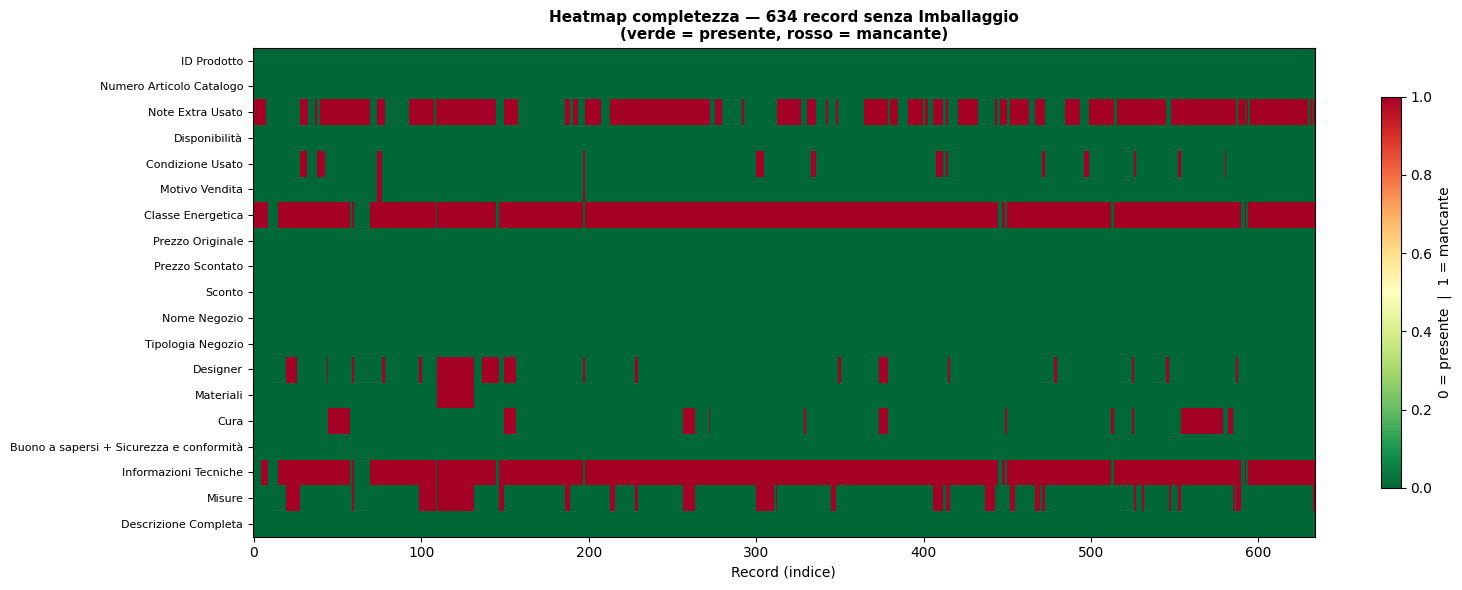

In [21]:
display(HTML("<h3><b>Pattern di completezza nei 634 record senza Imballaggio</b></h3>"))

# Costruiamo la matrice binaria: 1 = mancante, 0 = presente
df_miss_pattern = df[mask_imball_miss].copy()

# Applichiamo is_missing_val su ogni colonna
matrice = pd.DataFrame({col: is_missing_val(df_miss_pattern[col]).astype(int) for col in df_miss_pattern.columns if col != COL_IMBALL})

# Percentuale di missing per colonna, ordinata
perc_miss_col = matrice.mean().sort_values(ascending=False) * 100

display(HTML("<b>% di missing per colonna nei 634 record senza Imballaggio:</b>"))
df_perc = perc_miss_col.reset_index()
df_perc.columns = ['Colonna', '% Missing']
df_perc['% Missing'] = df_perc['% Missing'].round(1)
df_perc.index = df_perc.index + 1
display(df_perc)

# Heatmap
fig, ax = plt.subplots(figsize=(16, 6))
im = ax.imshow(matrice.T.values, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=1, interpolation='none')
ax.set_yticks(range(len(matrice.columns)))
ax.set_yticklabels(matrice.columns, fontsize=8)
ax.set_xlabel('Record (indice)', fontsize=10)
ax.set_title('Heatmap completezza — 634 record senza Imballaggio\n(verde = presente, rosso = mancante)', fontsize=11, fontweight='bold')
plt.colorbar(im, ax=ax, label='0 = presente  |  1 = mancante', shrink=0.8)
plt.tight_layout()
plt.show()

In [22]:
# Imputazione NaN → 'Non specificato' per Imballaggio Presente
df[COL_IMBALL] = df[COL_IMBALL].astype(str).str.strip()
df.loc[mask_imball_miss, COL_IMBALL] = 'Non specificato'

# Verifica
vc = df[COL_IMBALL].value_counts(dropna=False)
display(HTML("<b>Distribuzione aggiornata — Imballaggio Presente:</b>"))
df_vc = vc.reset_index()
df_vc.columns = ['Valore', 'N.']
df_vc['%'] = (df_vc['N.'] / len(df) * 100).round(2)
df_vc.index = df_vc.index + 1
display(df_vc)

,Valore,N.,%
1,True,7468,79.40
2,False,1303,13.85
3,Non specificato,634,6.74


In [ ]:
# APPROFONDIMENTO: MISSING IN 'MOTIVO VENDITA'
display(HTML("<h3><b>APPROFONDIMENTO: MISSING IN 'MOTIVO VENDITA'</b></h3>"))

COL_MOTIVO = 'Motivo Vendita'
COL_COND = 'Condizione Usato'
COL_NOTE = 'Note Extra Usato'

mask_mot_miss = is_missing_val(df[COL_MOTIVO])
n_miss = mask_mot_miss.sum()
df_miss = df[mask_mot_miss].copy()
df_pres = df[~mask_mot_miss].copy()

display(HTML(f"Record con <code>{COL_MOTIVO}</code> mancante: <b>{n_miss}</b> su {len(df):,} (<b>{round(n_miss/len(df)*100,2)}%</b>)"))

# Distribuzione empirica: Condizione → Motivo sul dataset completo 
# Per ogni condizione si mostra come si distribuiscono i motivi di vendita. L'obiettivo è valutare se esiste un'associazione sufficientemente stabile da giustificare un'imputazione rule-based sui 35 record mancanti.
display(HTML("<br><b>Associazione empirica tra Condizione Usato e Motivo Vendita (dataset completo)</b>"))

cross = pd.crosstab(df_pres[COL_COND].fillna('N/D').astype(str).str.strip(),df_pres[COL_MOTIVO].astype(str).str.strip(),normalize='index').round(3) * 100
display(HTML("% di riga — per ogni condizione, distribuzione dei motivi di vendita:"))
display(cross.style.background_gradient(cmap='Purples', axis=1).format("{:.1f}%"))

# Motivo dominante per condizione 
display(HTML("<br><b>Motivo dominante per ciascuna Condizione</b>"))
display(HTML("La soglia del 50% è usata come criterio minimo di affidabilità: sotto quella soglia la distribuzione è troppo dispersa per imputare con sicurezza."))

motivo_dominante = []
for cond in cross.index:
    row        = cross.loc[cond]
    top_motivo = row.idxmax()
    top_perc   = row.max()
    secondo    = row.drop(top_motivo).idxmax()
    sec_perc   = row.drop(top_motivo).max()
    affidabile = "Affidabile" if top_perc >= 50 else "Dispersa"
    motivo_dominante.append({'Condizione Usato': cond,'Motivo Dominante': top_motivo,'% Dominante': round(top_perc, 1),'2° Motivo': secondo,'% 2° Motivo': round(sec_perc, 1), 'Regola' : affidabile,})
df_dom = pd.DataFrame(motivo_dominante)
df_dom.index = df_dom.index + 1
display(df_dom)

# Condizione Usato nei 35 record mancanti 
display(HTML("<br><b>Condizione Usato nei 35 record con Motivo mancante</b>"))
cond_nei_miss = df_miss[COL_COND].value_counts(dropna=False).reset_index()
cond_nei_miss.columns = ['Condizione Usato', 'N.']
cond_nei_miss['%'] = (cond_nei_miss['N.'] / n_miss * 100).round(1)
cond_nei_miss.index = cond_nei_miss.index + 1
display(cond_nei_miss)

# Note Extra Usato nei 35 record mancanti 
display(HTML("<br><b>Note Extra Usato nei 35 record con Motivo mancante</b>"))
note_nei_miss = df_miss[COL_NOTE].dropna().astype(str).str.strip()
note_nei_miss = note_nei_miss[~note_nei_miss.str.lower().isin(PLACEHOLDER_MISSING)]

if note_nei_miss.empty:
    display(HTML("Nessuna nota extra disponibile per i record con motivo mancante."))
else:
    df_note = note_nei_miss.value_counts().reset_index()
    df_note.columns = ['Nota Extra Usato', 'Freq.']
    df_note['% sui record con nota'] = (df_note['Freq.'] / len(note_nei_miss) * 100).round(1)
    df_note.index = df_note.index + 1
    display(HTML(f"{len(note_nei_miss)} record su {n_miss} hanno una nota extra valorizzata:"))
    display(df_note)

Motivo Vendita,Danneggiato,Esposizione,Imballaggio mancante,Incompleto,Prodotto fuori produzione,Prodotto imballato,Reso cliente,Seconda mano,Seconda scelta
Condizione Usato,,,,,,,,,
Buono,18.8%,19.4%,0.2%,0.1%,7.1%,2.5%,51.8%,0.0%,0.1%
Come nuovo,23.6%,21.4%,0.7%,0.0%,20.0%,1.7%,31.9%,0.0%,0.6%
Discreto,48.8%,8.3%,0.0%,0.0%,1.2%,0.0%,41.7%,0.0%,0.0%
N/D,2.8%,7.3%,4.9%,0.6%,62.1%,11.9%,7.0%,0.0%,3.4%
Nuovissimo,2.6%,4.6%,3.1%,0.2%,60.6%,5.8%,22.3%,0.1%,0.7%
Pezzi mancanti,72.4%,13.8%,0.0%,0.0%,0.0%,0.0%,13.8%,0.0%,0.0%
Seconda scelta,0.0%,2.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,97.6%


,Condizione Usato,Motivo Dominante,% Dominante,2° Motivo,% 2° Motivo,Regola
1,Buono,Reso cliente,51.8,Esposizione,19.4,Affidabile
2,Come nuovo,Reso cliente,31.9,Danneggiato,23.6,Dispersa
3,Discreto,Danneggiato,48.8,Reso cliente,41.7,Dispersa
4,N/D,Prodotto fuori produzione,62.1,Prodotto imballato,11.9,Affidabile
5,Nuovissimo,Prodotto fuori produzione,60.6,Reso cliente,22.3,Affidabile
6,Pezzi mancanti,Danneggiato,72.4,Esposizione,13.8,Affidabile
7,Seconda scelta,Seconda scelta,97.6,Esposizione,2.4,Affidabile


,Condizione Usato,N.,%
1,Nuovissimo,19,54.3
2,NaN,6,17.1
3,Come nuovo,5,14.3
4,Buono,5,14.3


,Nota Extra Usato,Freq.,% sui record con nota
1,imballo rovinato,4,36.4
2,Fuori assortimento,3,27.3
3,"Prodotto non montato, integro e pulito in imba...",1,9.1
4,imballo danneggiato,1,9.1
5,Prodotto integro e pulito in imballo danneggiato,1,9.1
6,Imballo rovinato,1,9.1


In [24]:
df.loc[mask_mot_miss, COL_MOTIVO] = 'Non specificato'

vc = df[COL_MOTIVO].value_counts(dropna=False)
df_vc = vc.reset_index()
df_vc.columns = ['Valore', 'N.']
df_vc['%'] = (df_vc['N.'] / len(df) * 100).round(2)
df_vc.index = df_vc.index + 1
display(HTML("<b>Distribuzione aggiornata — Motivo Vendita:</b>"))
display(df_vc)

,Valore,N.,%
1,Prodotto fuori produzione,3477,36.97
2,Reso cliente,2807,29.85
3,Danneggiato,1217,12.94
4,Esposizione,1204,12.80
5,Prodotto imballato,375,3.99
6,Imballaggio mancante,172,1.83
7,Seconda scelta,101,1.07
8,Non specificato,35,0.37
9,Incompleto,12,0.13
10,Seconda mano,5,0.05


### **3.3.2. Classificazione semantica delle note aggiuntive**

Con 836 valori distinti, `Note Extra Usato` è una colonna ad altissima cardinalità testuale. Avere del testo libero implica una massima espressività, ma anche una **massima frammentazione**: note semanticamente identiche vengono trattate come categorie diverse. In questa sezione valutiamo le strategie disponibili per ridurre la cardinalità. Si sperimentano **4 approcci distinti** per normalizzare i valori della colonna in categorie semantiche coerenti. Le categorie target per i soli testi validi sono:

1. **Imballo danneggiato / mancante** (problemi relativi al packaging);

2. **Prodotto danneggiato** (difetti fisici, usura o imperfezioni dell'articolo);

3. **Prodotto integro** (stato positivo, articolo nuovo o pari al nuovo);

4. **Resi / Errori spedizione** (cambi idea del cliente, acquisti errati o mancate consegne);

5. **Fine serie / Fuori catalogo** (articoli fuori assortimento, fuori produzione);

6. **Promozioni / Offerte / Disponibilità** (sconti, promozioni, esclusive online o articoli su ordinazione);
 
7. **Altro** (testi validi non classificabili nelle categorie precedenti).

Le tecniche che implementiamo sono:
1. **Rule-based** (dizionari + regex);
2. **TF-IDF + KMeans** (scikit-learn);
3. **Sentence Embeddings + clustering** (sentence-transformers);
4. **Zero-shot LLM** (Gemini API).

In [ ]:
COL_NOTE = 'Note Extra Usato'
PLACEHOLDER_MISSING = {'nan', '<na>', 'none', 'no info', '-', '--', '', 'vuoto', 'n/a', 'nd'}

CATEGORIE = ['Imballo danneggiato / mancante',
    'Prodotto danneggiato',
    'Prodotto integro',
    'Resi / Errori spedizione',
    'Fine serie / Fuori catalogo',
    'Promozioni / Offerte / Disponibilità',
    'Altro',]

# Estrazione solo delle note non-missing e non quasi-vuote
note_raw = df[COL_NOTE].copy()
mask_valide = (note_raw.notna() & (~note_raw.astype(str).str.strip().str.lower().isin(PLACEHOLDER_MISSING)) & (note_raw.astype(str).str.strip().str.len() > 1) & (~note_raw.astype(str).str.strip().str.fullmatch(r'[.\-_\s]+')) & (~note_raw.astype(str).str.strip().str.fullmatch(r'\d+')))
note_valide = note_raw[mask_valide].astype(str).str.strip()
print(f'Note valide da classificare: {len(note_valide):,} su {len(df):,} record totali')
print(f'Valori distinti: {note_valide.nunique():,}')

Note valide da classificare: 3,374 su 9,405 record totali
Valori distinti: 779


In [ ]:
mask_base = (note_raw.notna() & (~note_raw.astype(str).str.strip().str.lower().isin(PLACEHOLDER_MISSING)))

mask_rumore = mask_base & ~mask_valide

display(HTML(f"Record totali ri-classificati come 'Vuoti' grazie ai nuovi filtri: <b>{mask_rumore.sum()}</b>"))

# Estraiamo la serie dei valori scartati
s_rumore = note_raw[mask_rumore].dropna().astype(str)

if not s_rumore.empty:
    display(HTML("Dettaglio del rumore rimosso:"))
    
    # Creiamo una singola tabella partendo dal conteggio delle frequenze
    df_unificato = s_rumore.value_counts().reset_index()
    df_unificato.columns = ['Valore (Rumore Scartato)', 'Frequenza (N. Record)']
    df_unificato['Valore (Rumore Scartato)'] = df_unificato['Valore (Rumore Scartato)'].apply(lambda x: f"'{x}'")
    df_unificato.index = df_unificato.index + 1
    display(df_unificato)

,Valore (Rumore Scartato),Frequenza (N. Record)
1,'.',35
2,'200',2
3,'191',2
4,'18001',1
5,'6',1
6,'92',1
7,'70',1
8,'60',1
9,'44',1
10,' .',1


-> **Approccio 1: rule-based**

Per strutturare il testo libero in categorie analitiche, si opta in primis per un approccio NLP deterministico basato su espressioni regolari (Regex) e Keyword Matching gerarchico.

In [ ]:
# CREAZIONE DI UN PRIMO DIZIONARIO
REGOLE = [
    # 1. Imballo danneggiato / mancante 
    (r'(imballo|imballaggio|inballo|scatola|confezione|packaging|cartone|box)'
     r'.{0,30}(dann|rovina|deformat|aperto|aperta|rott|mancan|assente|senza|busta|originale)',
     'Imballo danneggiato / mancante'),
    (r'(dann|rovina|deformat|rott).{0,30}(imballo|imballaggio|scatola|confezione)',
     'Imballo danneggiato / mancante'),
    (r'^(imballo|imballaggio|inballo|scatola|confezione)$',
     'Imballo danneggiato / mancante'),
    (r'imballo (non )?mancante|imballaggio mancante|senza (imballo|imballaggio|scatola)',
     'Imballo danneggiato / mancante'),

    # 2. Prodotto danneggiato 
    (r'(graffi|ammaccat|scheggiat|rigat|difetto|difettoso|usurato|sfilacci'
     r'|macchia|crepa|incrinat|piccoli segni|sporco|leggermente (dann|usur|rovina)'
     r'|verniciatura|segni (di )?usura)',
     'Prodotto danneggiato'),

    # 3. Prodotto integro 
    (r'(integro|pulito|nessun difetto|privo di difetti|in ottime|mai usato'
     r'|mai utilizzato|come nuovo|perfetto|ottimo stato|completo|articolo nuovo'
     r'|prodotto nuovo|ancora imballato|prodotto imballato|imballato$)',
     'Prodotto integro'),
    (r'^(nuovo|buono|ok|okay)$', 'Prodotto integro'),

    # 4. Resi / Errori spedizione
    (r'(cambio (idea|modello|collezione)|acquisto errato|consegn[ae] fallit|reso cliente|merce eccedente|eccedenz)',
     'Resi / Errori spedizione'),

    # 5. Fine serie / Fuori catalogo
    (r'(fuori assortimento|fuori ass\.?|fine serie|fuori produzione|non pi[uù] in catalogo'
     r'|discontinued|out of (line|stock|range)|clearance|non piu in catalogo)',
     'Fine serie / Fuori catalogo'),

    # 6. Promozioni / Offerte / Disponibilità
    (r'(on.?line|solo (online|in rete|web)|art(icolo)? su ordinazione|su ordinazione |deprezzato'
     r'|non disponibile in negozio|articolo non disponibile|solo web'
     r'|ultim[io] (pezz[oi]|unit[aà])|ribasso|offerta|promo|sconto'
     r'|18alle18|18 alle 18|ulteriore ribasso|last (piece|unit))',
     'Promozioni / Offerte / Disponibilità'),
]


def classifica_rule_based(testo):
    if pd.isna(testo):
        return np.nan                          
    t = str(testo).strip().lower()
    if t in PLACEHOLDER_MISSING or len(t) <= 1 or re.fullmatch(r'[.\-_\s]+', t):
        return np.nan                          
    for pattern, categoria in REGOLE:
        if re.search(pattern, t):
            return categoria
    return 'Altro'                            

df['cat_rule'] = df[COL_NOTE].apply(classifica_rule_based)

display(HTML('<h3>Approccio 1 - Rule-Based</h3>'))
vc1 = df['cat_rule'].value_counts().reset_index()
vc1.columns = ['Categoria', 'N.']
vc1['%'] = (vc1['N.'] / len(df) * 100).round(2)
vc1.index = vc1.index + 1
display(vc1)

display(HTML('Verifica qualitativa - campione per categoria:'))
for cat in CATEGORIE:
    sub = df[df['cat_rule'] == cat][COL_NOTE].dropna().astype(str)
    sub = sub[sub.str.len() > 1]
    if sub.empty:
        continue
    display(HTML(f'<hr><b>{cat}</b> ({len(sub)} record)'))
    display(sub.value_counts().head(5).reset_index().rename(columns={COL_NOTE: 'Nota originale', 'count': 'Freq.'}))

residui = df[df['cat_rule'].isna() & mask_valide][COL_NOTE]
display(HTML(f'<br>Residui non classificati con nota valorizzata: {len(residui):,}'))

if len(residui) > 0:
    display(residui.value_counts().head(20).reset_index().rename(columns={COL_NOTE: 'Nota', 'count': 'Freq.'}))

,Categoria,N.,%
1,Imballo danneggiato / mancante,1889,20.09
2,Altro,405,4.31
3,Fine serie / Fuori catalogo,326,3.47
4,Resi / Errori spedizione,214,2.28
5,Prodotto integro,203,2.16
6,Promozioni / Offerte / Disponibilità,185,1.97
7,Prodotto danneggiato,162,1.72


,Nota originale,Freq.
0,imballo danneggiato,269
1,imballo rovinato,136
2,IMBALLO DANNEGGIATO,86
3,imballaggio danneggiato,84
4,Imballo danneggiato,52


,Nota originale,Freq.
0,Nessun difetto,8
1,Leggermente sporco,6
2,imballo sporco,6
3,Piccoli difetti verniciatura,6
4,Graffiato,5


,Nota originale,Freq.
0,cambio idea mai usato,15
1,NUOVO,14
2,nuovo,13
3,ARTICOLO NUOVO,10
4,imballo non perfetto,10


,Nota originale,Freq.
0,cambio idea,55
1,CAMBIO IDEA,33
2,eccedenze da ordini on line,20
3,merce eccedente,14
4,Cambio idea,9


,Nota originale,Freq.
0,fuori assortimento,87
1,Fuori assortimento,41
2,prodotto fuori assortimento,32
3,FUORI ASSORTIMENTO,30
4,Fuori assortimento,26


,Nota originale,Freq.
0,ON LINE,49
1,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19
2,ULTERIORE RIBASSO!,18
3,18ALLE18,17
4,ULTIMI PEZZI!,14


,Nota originale,Freq.
0,Ordinalo a soli €10 in più presso i Plan & Ord...,19
1,IMMBALLAGGIO DANNEGGIATO,11
2,proveniente da ordine annullato,8
3,IMBALLAGGIO DANEGGIATO,7
4,ARTIOCOLO NUOVO,4


In [ ]:
# CREAZIONE DI UN SECONDO DIZIONARIO OTTIMIZZATO
REGOLE_2 = [
    # 1. Imballo danneggiato / mancante
    (r'(imb+all[ao]g?g?i?o?|inballo|scatola|confezione|packaging|cartone|box|busta)'
     r'.{0,30}(dann|rovina|deformat|aperto|aperta|rott|mancan|assente|senza|originale)',
     'Imballo danneggiato / mancante'),
    (r'(dann|rovina|deformat|rott).{0,30}(imb+all[ao]g?g?i?o?|scatola|confezione)',
     'Imballo danneggiato / mancante'),
    (r'^(imb+all[ao]g?g?i?o?|scatola|confezione)$',
     'Imballo danneggiato / mancante'),
    (r'imballo (non )?mancante|imballaggio mancante|senza (imballo|imballaggio|scatola)',
     'Imballo danneggiato / mancante'),
    # (Refusi frequenti: "immballaggio", "imbalaggio", "daneggiato")
    (r'imb{1,3}al{1,3}[ao]g{0,2}i?o?.{0,30}(dan{1,2}eg{1,2}i?ato|dann|rovina)',
     'Imballo danneggiato / mancante'),

    # 3. Prodotto integro (anticipato rispetto a Prodotto danneggiato)
    (r'(integro|pulito|nessun difetto|privo di difetti|in ottime|mai usato'
     r'|mai utilizzato|come nuovo|perfetto|ottimo stato|completo|articolo nuovo'
     r'|art{1,2}i?o?c?olo nuovo|prodotto nuovo|ancora imballato|prodotto imballato|imballato$)',
     'Prodotto integro'),
    (r'^(nuovo|buono|ok|okay)$', 'Prodotto integro'),

    # 2. Prodotto danneggiato (posticipato)
    (r'(graffi|ammaccat|scheggiat|rigat|difetto|difettoso|usurato|sfilacci'
     r'|macchia|crepa|incrinat|piccoli segni|sporco|leggermente (dann|usur|rovina)'
     r'|verniciatura|segni (di )?usura)',
     'Prodotto danneggiato'),

    # 4. Resi / Errori spedizione
    (r'(cambio (idea|modello|collezione)|acquisto errato|consegn[ae] fallit'
     r'|reso cliente|merce eccedente|ecceden[tz]|proveniente da ordine annullato'
     r'|ordine annullato)',
     'Resi / Errori spedizione'),

    # 5. Fine serie / Fuori catalogo
    (r'(fuori assortimento|fuori ass\.?|fine serie|fuori produzione|non pi[uù] in catalogo'
     r'|discontinued|out of (line|stock|range)|clearance|non piu in catalogo)',
     'Fine serie / Fuori catalogo'),

    # 6. Promozioni / Offerte / Disponibilità
    (r'(on.?line|solo (online|in rete|web)|art(icolo)? su ordinazione|su ordinazione'
     r'|deprezzato|non disponibile in negozio|articolo non disponibile|solo web'
     r'|ultim[io] (pezz[oi]|unit[aà])|ribasso|offerta|promo|sconto'
     r'|18alle18|18 alle 18|ulteriore ribasso|last (piece|unit))',
     'Promozioni / Offerte / Disponibilità'),
]

def classifica_rule_based_2(testo):
    if pd.isna(testo):
        return np.nan                                  

    t = str(testo).strip().lower()
    
    if (t in PLACEHOLDER_MISSING or 
        len(t) <= 1 or 
        re.fullmatch(r'[.\-_\s]+', t) or 
        re.fullmatch(r'\d+', t)):
        return np.nan                                  
        
    for pattern, categoria in REGOLE_2:
        if re.search(pattern, t):
            return categoria
            
    return 'Altro'      

df['cat_rule'] = df[COL_NOTE].apply(classifica_rule_based_2)

display(HTML('<h3>Approccio 1 - Rule-Based</h3>'))
vc1 = df['cat_rule'].value_counts().reset_index()
vc1.columns = ['Categoria', 'N.']
vc1['%'] = (vc1['N.'] / len(df) * 100).round(2)
vc1.index = vc1.index + 1
display(vc1)

display(HTML('Verifica qualitativa - campione per categoria:'))
for cat in CATEGORIE:
    sub = df[df['cat_rule'] == cat][COL_NOTE].dropna().astype(str)
    sub = sub[sub.str.len() > 1]
    if sub.empty:
        continue
    display(HTML(f'<hr><b>{cat}</b> ({len(sub)} record)'))
    display(sub.value_counts().head(5).reset_index().rename(columns={COL_NOTE: 'Nota originale', 'count': 'Freq.'}))

residui = df[df['cat_rule'].isna() & mask_valide][COL_NOTE]
display(HTML(f'<br>Residui non classificati con nota valorizzata: {len(residui):,}'))

if len(residui) > 0:
    display(residui.value_counts().head(20).reset_index().rename(columns={COL_NOTE: 'Nota', 'count': 'Freq.'}))

,Categoria,N.,%
1,Imballo danneggiato / mancante,1902,20.22
2,Altro,365,3.88
3,Fine serie / Fuori catalogo,326,3.47
4,Prodotto integro,223,2.37
5,Resi / Errori spedizione,223,2.37
6,Promozioni / Offerte / Disponibilità,186,1.98
7,Prodotto danneggiato,149,1.58


,Nota originale,Freq.
0,imballo danneggiato,269
1,imballo rovinato,136
2,IMBALLO DANNEGGIATO,86
3,imballaggio danneggiato,84
4,Imballo danneggiato,52


,Nota originale,Freq.
0,Leggermente sporco,6
1,imballo sporco,6
2,Piccoli difetti verniciatura,6
3,Graffiato,5
4,leggermente danneggiato,5


,Nota originale,Freq.
0,cambio idea mai usato,15
1,NUOVO,14
2,nuovo,13
3,ARTICOLO NUOVO,10
4,imballo non perfetto,10


,Nota originale,Freq.
0,cambio idea,55
1,CAMBIO IDEA,33
2,eccedenze da ordini on line,20
3,merce eccedente,14
4,Cambio idea,9


,Nota originale,Freq.
0,fuori assortimento,87
1,Fuori assortimento,41
2,prodotto fuori assortimento,32
3,FUORI ASSORTIMENTO,30
4,Fuori assortimento,26


,Nota originale,Freq.
0,ON LINE,49
1,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19
2,ULTERIORE RIBASSO!,18
3,18ALLE18,17
4,ULTIMI PEZZI!,14


,Nota originale,Freq.
0,Ordinalo a soli €10 in più presso i Plan & Ord...,19
1,IMMBALLAGGIO DANNEGGIATO,11
2,1 pezzo,4
3,manca codice,4
4,Ordinalo a soli €10 in più presso i Plan & Ord...,4


-> **Approccio 2: TF-IDF e K-means**

Per validare la robustezza delle categorie definite tramite approccio Rule-Based (Top-Down) e per esplorare l'eventuale presenza di pattern latenti non previsti nel dizionario iniziale, si introduce un approccio di Machine Learning Non Supervisionato (Bottom-Up). L'obiettivo è lasciare che sia un algoritmo matematico a raggruppare le note testuali in base alla loro reale somiglianza semantica, senza imporre regole o etichette a priori. Il processo si articola in tre fasi: vettorializzazione del testo (TF-IDF); raggruppamento spaziale (K-Means); ottimizzazione del parametro K (Silhouette Score).

Matrice TF-IDF: 3374 note x 702 feature


  K=4: Silhouette = 0.2524
  K=5: Silhouette = 0.2949
  K=6: Silhouette = 0.3266
  K=7: Silhouette = 0.3429
  K=8: Silhouette = 0.3800
  K=9: Silhouette = 0.3670
  K=10: Silhouette = 0.4123
  K=11: Silhouette = 0.4163
  K=12: Silhouette = 0.4239


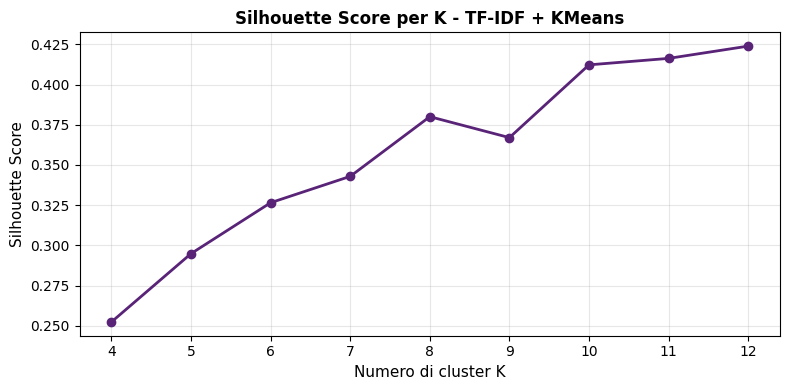

In [29]:
corpus = note_valide.str.lower().str.strip().tolist()
vectorizer = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2,max_df=0.95, strip_accents='unicode', sublinear_tf=True,)
X_tfidf = vectorizer.fit_transform(corpus)
print(f'Matrice TF-IDF: {X_tfidf.shape[0]} note x {X_tfidf.shape[1]} feature')

display(HTML('<b>Ricerca K ottimale</b> (Silhouette Score):'))
silhouette_scores = []
K_range = range(4, 13)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_tfidf)
    score = silhouette_score(X_tfidf, labels, sample_size=2000, random_state=42)
    silhouette_scores.append(score)
    print(f'  K={k}: Silhouette = {score:.4f}')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), silhouette_scores, marker='o', color='#592378', linewidth=2)
ax.set_xlabel('Numero di cluster K', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette Score per K - TF-IDF + KMeans', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
K_best = list(K_range)[silhouette_scores.index(max(silhouette_scores))]
display(HTML(f'<b>K ottimale suggerito: {K_best}</b> (Silhouette = {max(silhouette_scores):.4f})'))

In [30]:
K_DA_CONFRONTARE = [7, 10, 12]
risultati_km = {}

for K_SCELTO in K_DA_CONFRONTARE:
    km = KMeans(n_clusters=K_SCELTO, random_state=42, n_init=10)
    labels = km.fit_predict(X_tfidf)
    feature_names = vectorizer.get_feature_names_out()
    
    df_cluster = note_valide.reset_index()
    df_cluster.columns = ['idx_originale', COL_NOTE]
    df_cluster['cluster'] = labels
    risultati_km[K_SCELTO] = df_cluster.copy()
    
    display(HTML(f'<h3>K = {K_SCELTO}</h3>'))
    
    for c in range(K_SCELTO):
        note_cluster = df_cluster[df_cluster['cluster'] == c][COL_NOTE]
        n = len(note_cluster)
        perc = round(n / len(note_valide) * 100, 1)
        
        # Top keyword dal centroide
        centroid = km.cluster_centers_[c]
        top_idx = centroid.argsort()[::-1][:8]
        top_kw = ', '.join(feature_names[top_idx])
        
        # Top note più frequenti
        top_note = note_cluster.value_counts().head(5).reset_index()
        top_note.columns = ['Nota', 'Freq.']
        top_note.index = top_note.index + 1
        
        display(HTML(f'<hr style="border-top:1px solid #e0e0e0;">'
            f'<b>Cluster {c}</b> — {n} note ({perc}%)<br>'
            f'<i>Top keyword: {top_kw}</i>'))
        display(top_note)
    
    display(HTML('<hr style="border-top:3px solid #592378; margin:20px 0;">'))

,Nota,Freq.
1,imballo danneggiato,317
2,IMBALLO DANNEGGIATO,90
3,Imballo danneggiato,82
4,danneggiato,3
5,IMBALLO DANNEGGIATO,1


,Nota,Freq.
1,NUOVO,14
2,nuovo,13
3,ARTICOLO NUOVO,10
4,ARTIOCOLO NUOVO,7
5,Nuovo,6


,Nota,Freq.
1,imballo rovinato,136
2,Imballo Rovinato,52
3,Imballo rovinato,51
4,IMBALLO ROVINATO,19
5,Completo - imballo rovinato,1


,Nota,Freq.
1,Imballaggio rovinato,66
2,cambio idea,55
3,imballaggio rovinato,34
4,confezione danneggiata,33
5,CAMBIO IDEA,33


,Nota,Freq.
1,fuori assortimento,89
2,Fuori assortimento,67
3,prodotto fuori assortimento,32
4,FUORI ASSORTIMENTO,30
5,fuori assortimento nuovo,13


...

,Nota,Freq.
1,Ordinalo a soli €10 in più presso i Plan & Ord...,19
2,Imballo danneggiato articolo integro,16
3,Prodotto integro e pulito in imballo originale,15
4,Prodotto integro e pulito in imballo danneggiato,12
5,ARTICOLO NUOVO,10


,Nota,Freq.
1,ON LINE,49
2,eccedenze da ordini on line,20
3,on line,6
4,acquisto on line errato,1
5,eccedenze di ordini on line,1


,Nota,Freq.
1,imballo rovinato,136
2,Imballo Rovinato,52
3,Imballo rovinato,51
4,IMBALLO ROVINATO,19
5,Completo - imballo rovinato,1


,Nota,Freq.
1,NUOVO,14
2,nuovo,13
3,Prodotto imballato,9
4,ARTIOCOLO NUOVO,7
5,FINE SERIE - IMBALLATO NUOVO,7


,Nota,Freq.
1,imballo aperto,21
2,imballo mancante,21
3,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19
4,IMBALLO DEFORMATO,19
5,ULTERIORE RIBASSO!,18


In [31]:
# Clustering finale con K=10
K_SCELTO = 10

km_final = KMeans(n_clusters=K_SCELTO, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(X_tfidf)

df_cluster = note_valide.reset_index()
df_cluster.columns = ['idx_originale', COL_NOTE]
df_cluster['cluster_tfidf'] = cluster_labels

MAPPING_TFIDF = {
    0: 'Imballo danneggiato / mancante',
    1: 'Prodotto integro',                    
    2: 'Imballo danneggiato / mancante',
    3: 'Fine serie / Fuori catalogo',         
    4: 'Imballo danneggiato / mancante',
    5: 'Imballo danneggiato / mancante',
    6: 'Altro',                                
    7: 'Prodotto integro',
    8: 'Resi / Errori spedizione',            
    9: 'Promozioni / Offerte / Disponibilità', 
}

df_cluster['cat_tfidf'] = df_cluster['cluster_tfidf'].map(MAPPING_TFIDF).fillna('Altro')  
df['cat_tfidf'] = pd.NA
df['cat_tfidf'] = df['cat_tfidf'].astype("string")

for _, row in df_cluster.iterrows():
    df.at[row['idx_originale'], 'cat_tfidf'] = row['cat_tfidf']

# Distribuzione finale
vc2 = df['cat_tfidf'].value_counts().reset_index()
vc2.columns = ['Categoria', 'N.']
vc2['%'] = (vc2['N.'] / len(df) * 100).round(2)
vc2.index = vc2.index + 1
display(HTML('<h3>Approccio 2 — TF-IDF + KMeans (K=10): Distribuzione Finale</h3>'))
display(vc2)

# Verifica qualitativa
display(HTML('<b>Verifica qualitativa — campione per categoria:</b>'))
for cat in CATEGORIE:
    sub = df[df['cat_tfidf'] == cat][COL_NOTE].dropna().astype(str)
    sub = sub[sub.str.len() > 1]
    if sub.empty:
        continue
    display(HTML(f'<hr><b>{cat}</b> ({len(sub)} record)'))
    display(sub.value_counts().head(5).reset_index().rename(columns={COL_NOTE: 'Nota originale', 'count': 'Freq.'}))

,Categoria,N.,%
1,Altro,1443,15.34
2,Imballo danneggiato / mancante,1053,11.2
3,Prodotto integro,395,4.2
4,Fine serie / Fuori catalogo,259,2.75
5,Resi / Errori spedizione,147,1.56
6,Promozioni / Offerte / Disponibilità,77,0.82


,Nota originale,Freq.
0,imballo danneggiato,269
1,imballo rovinato,136
2,IMBALLO DANNEGGIATO,86
3,imballaggio danneggiato,84
4,Imballo danneggiato,52


,Nota originale,Freq.
0,SCATOLA ROVINATA - PRODOTTO INTEGRO,29
1,Prodotto integro e pulito in imballo originale,15
2,NUOVO,14
3,nuovo,13
4,Prodotto integro e pulito in imballo danneggiato,12


,Nota originale,Freq.
0,cambio idea,55
1,CAMBIO IDEA,33
2,cambio idea mai usato,15
3,Cambio idea,9
4,CAMBIO IDEA IMBALLO ORIGINALE,4


,Nota originale,Freq.
0,fuori assortimento,87
1,Fuori assortimento,41
2,prodotto fuori assortimento,32
3,FUORI ASSORTIMENTO,30
4,Fuori assortimento,26


,Nota originale,Freq.
0,ON LINE,49
1,eccedenze da ordini on line,20
2,on line,6
3,acquisto on line errato,1
4,eccedenze di ordini on line,1


,Nota originale,Freq.
0,confezione danneggiata,33
1,Scatola aperta,23
2,imballo mancante,21
3,imballo aperto,19
4,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19


-> **Approccio 3: Sentence Embeddings e HDBSCAN**

Il limite principale del TF-IDF emerso prima è che tratta ogni parola come una dimensione indipendente. I sentence embeddings risolvono questo problema rappresentando ogni nota come un vettore denso in uno spazio a 384 dimensioni, addestrato su miliardi di frasi in modo che testi con significato simile abbiano vettori vicini, indipendentemente dalle parole usate. La pipeline segue tre fasi: encoding con SentenceTransformer; riduzione dimensionale con UMAP; clustering con HDBSCAN.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/53 [00:00<?, ?it/s]

Embeddings shape: (3374, 384)
Embeddings ridotti: (3374, 10)


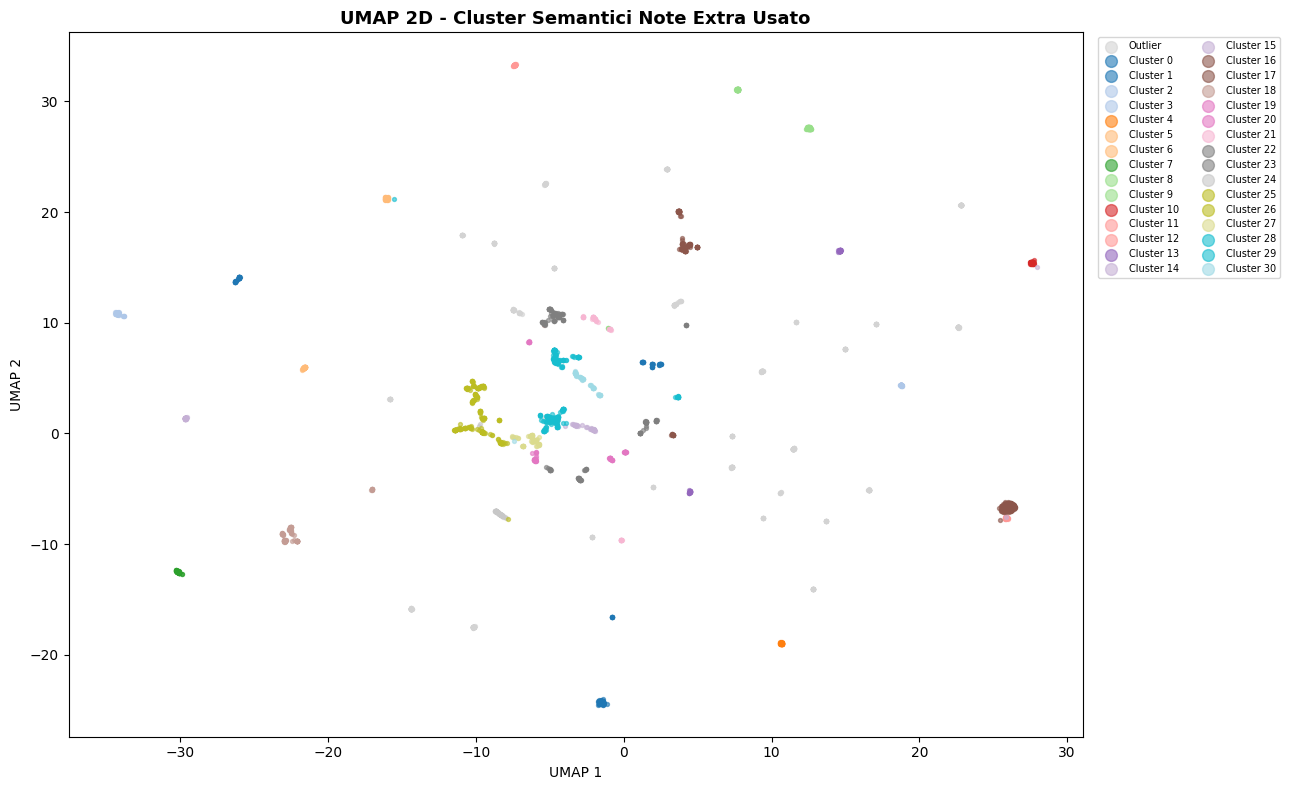

In [32]:
# Fase 1: Encoding 
MODEL_NAME = 'paraphrase-multilingual-MiniLM-L12-v2'
model = SentenceTransformer(MODEL_NAME)
corpus_list = note_valide.tolist()

embeddings = model.encode(corpus_list, batch_size=64, show_progress_bar=True, convert_to_numpy=True)
print(f'Embeddings shape: {embeddings.shape}')

# Fase 2: Riduzione dimensionale UMAP 
reducer = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, metric='cosine', random_state=42)
embeddings_reduced = reducer.fit_transform(embeddings)
print(f'Embeddings ridotti: {embeddings_reduced.shape}')

# Fase 3: Clustering HDBSCAN 
clusterer = hdbscan.HDBSCAN(min_cluster_size=50,min_samples=5,metric='euclidean',cluster_selection_method='eom')
cluster_emb = clusterer.fit_predict(embeddings_reduced)

n_clusters = len(set(cluster_emb)) - (1 if -1 in cluster_emb else 0)
n_noise = (cluster_emb == -1).sum()
display(HTML(f'Cluster trovati: <b>{n_clusters}</b> | Outlier (rumore): <b>{n_noise}</b> ({round(n_noise/len(corpus_list)*100,1)}%)'))

# Visualizzazione UMAP 2D 
reducer_2d = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,metric='cosine', random_state=42)
emb_2d = reducer_2d.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(13, 8))
palette = cm.get_cmap('tab20', n_clusters + 1)
for c in sorted(set(cluster_emb)):
    mask  = cluster_emb == c
    label = f'Cluster {c}' if c != -1 else 'Outlier'
    color = 'lightgray' if c == -1 else palette(c)
    ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1], s=8, alpha=0.6, color=color, label=label)
ax.legend(markerscale=3, fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left', ncol=2)
ax.set_title('UMAP 2D - Cluster Semantici Note Extra Usato', fontsize=13, fontweight='bold')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
plt.tight_layout()
plt.show()

In [33]:
df_emb = note_valide.reset_index()
df_emb.columns = ['idx_originale', COL_NOTE]
df_emb['cluster_emb'] = cluster_emb

riepilogo = []
for c in sorted(set(cluster_emb)):
    sub   = df_emb[df_emb['cluster_emb'] == c][COL_NOTE]
    label = f'Cluster {c}' if c != -1 else 'Outlier'
    top3  = ' | '.join(sub.value_counts().head(3).index.tolist())
    riepilogo.append({
        'Cluster'  : label,
        'N. note'  : len(sub),
        '%'        : round(len(sub)/len(corpus_list)*100, 1),
        'Top 3 note': top3[:80]})

df_riepilogo = pd.DataFrame(riepilogo)
df_riepilogo.index = df_riepilogo.index + 1
display(df_riepilogo)

,Cluster,N. note,%,Top 3 note
1,Outlier,528,15.6,imballaggio rovinato | prodotto fuori assortim...
2,Cluster 0,148,4.4,imballo rovinato | imballo rotto | imballo rov...
3,Cluster 1,79,2.3,Imballo danneggiato articolo integro | Articol...
4,Cluster 2,92,2.7,Imballo danneggiato | danneggiato | Leggerment...
5,Cluster 3,51,1.5,Imballo rovinato
6,Cluster 4,66,2.0,Imballaggio rovinato
7,Cluster 5,89,2.6,fuori assortimento
8,Cluster 6,53,1.6,CAMBIO IDEA | Cambio idea | CAMBIO IDEA IMBALL...
9,Cluster 7,83,2.5,cambio idea | cambio idea mai usato | cambio i...
10,Cluster 8,55,1.6,ON LINE | on line


In [34]:
MAPPING_EMB = {
    # ── Imballo danneggiato / mancante ──
    0:  'Imballo danneggiato / mancante',
    1:  'Imballo danneggiato / mancante',
    2:  'Imballo danneggiato / mancante',
    3:  'Imballo danneggiato / mancante',
    4:  'Imballo danneggiato / mancante',
    10: 'Imballo danneggiato / mancante',
    11: 'Imballo danneggiato / mancante',
    12: 'Imballo danneggiato / mancante',
    13: 'Imballo danneggiato / mancante',
    14: 'Imballo danneggiato / mancante',
    15: 'Imballo danneggiato / mancante',
    16: 'Imballo danneggiato / mancante',
    17: 'Imballo danneggiato / mancante',
    18: 'Imballo danneggiato / mancante',
    24: 'Imballo danneggiato / mancante',
    25: 'Imballo danneggiato / mancante',
    26: 'Imballo danneggiato / mancante',
    27: 'Imballo danneggiato / mancante',
    29: 'Imballo danneggiato / mancante',

    # ── Fine serie / Fuori catalogo ──       
    5:  'Fine serie / Fuori catalogo',        
    9:  'Fine serie / Fuori catalogo',        
    20: 'Fine serie / Fuori catalogo',        

    # ── Resi / Errori spedizione ──          
    6:  'Resi / Errori spedizione',           
    7:  'Resi / Errori spedizione',           
    23: 'Resi / Errori spedizione',         

    # ── Prodotto integro ──
    19: 'Prodotto integro',
    22: 'Prodotto integro',

    # ── Promozioni / Offerte / Disponibilità ── 
    8:  'Promozioni / Offerte / Disponibilità',   
    21: 'Promozioni / Offerte / Disponibilità',   

    # ── Altro ──                             
    -1: 'Altro',
    28: 'Altro',
    30: 'Altro',
}

# Applicazione del mapping
df_emb['cat_emb'] = df_emb['cluster_emb'].map(MAPPING_EMB).fillna('Altro')  
df['cat_emb'] = pd.NA
df['cat_emb'] = df['cat_emb'].astype("string")

for _, row in df_emb.iterrows():
    df.at[row['idx_originale'], 'cat_emb'] = row['cat_emb']

# Distribuzione finale 
vc3 = df['cat_emb'].value_counts().reset_index()
vc3.columns = ['Categoria', 'N.']
vc3['%'] = (vc3['N.'] / len(df) * 100).round(2)
vc3.index = vc3.index + 1
display(HTML('<h3>Approccio 3 — Embedding + HDBSCAN: Distribuzione Finale</h3>'))
display(vc3)

# Verifica qualitativa 
display(HTML('<b>Verifica qualitativa — campione per categoria:</b>'))
for cat in CATEGORIE:
    sub = df[df['cat_emb'] == cat][COL_NOTE].dropna().astype(str)
    sub = sub[sub.str.len() > 1]
    if sub.empty:
        continue
    display(HTML(f'<hr><b>{cat}</b> ({len(sub)} record)'))
    display(sub.value_counts().head(5).reset_index().rename(columns={COL_NOTE: 'Nota originale', 'count': 'Freq.'}))

# Confronto sintetico con Approccio 1
display(HTML('<br><b>Confronto sintetico Rule-Based vs Embedding+HDBSCAN:</b>'))
confronto = []
for cat in CATEGORIE:
    n_rule = (df['cat_rule'] == cat).sum()
    n_emb  = (df['cat_emb']  == cat).sum()
    confronto.append({
        'Categoria'   : cat,
        'Rule-Based'  : f"{n_rule:,} ({round(n_rule/len(df)*100,1)}%)",
        'Emb+HDBSCAN' : f"{n_emb:,} ({round(n_emb/len(df)*100,1)}%)",
        'Delta N.'    : n_emb - n_rule,})
df_conf = pd.DataFrame(confronto)
df_conf.index = df_conf.index + 1
display(df_conf)

,Categoria,N.,%
1,Imballo danneggiato / mancante,1907,20.28
2,Altro,734,7.8
3,Resi / Errori spedizione,239,2.54
4,Fine serie / Fuori catalogo,236,2.51
5,Prodotto integro,144,1.53
6,Promozioni / Offerte / Disponibilità,114,1.21


,Nota originale,Freq.
0,imballo danneggiato,269
1,imballo rovinato,136
2,imballaggio danneggiato,84
3,IMBALLO DANNEGGIATO,54
4,Imballo danneggiato,52


,Nota originale,Freq.
0,NUOVO,14
1,nuovo,13
2,ARTICOLO NUOVO,10
3,Nuovo,6
4,NUOVO NESSUN DIFETTO,4


,Nota originale,Freq.
0,cambio idea,55
1,CAMBIO IDEA,33
2,cambio idea mai usato,15
3,imballo non perfetto,10
4,Cambio idea,9


,Nota originale,Freq.
0,fuori assortimento,87
1,Fuori assortimento,41
2,FUORI ASSORTIMENTO,30
3,Fuori assortimento,26
4,merce eccedente,14


,Nota originale,Freq.
0,ON LINE,49
1,scatola aperta,8
2,articolo non disponibile in negozio,8
3,non piu in catalogo,7
4,scatola mai aperta,7


,Nota originale,Freq.
0,imballaggio rovinato,34
1,prodotto fuori assortimento,32
2,IMBALLO DANNEGGIATO,32
3,eccedenze da ordini on line,20
4,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19


,Categoria,Rule-Based,Emb+HDBSCAN,Delta N.
1,Imballo danneggiato / mancante,"1,902 (20.2%)","1,907 (20.3%)",5
2,Prodotto danneggiato,149 (1.6%),0 (0.0%),-149
3,Prodotto integro,223 (2.4%),144 (1.5%),-79
4,Resi / Errori spedizione,223 (2.4%),239 (2.5%),16
5,Fine serie / Fuori catalogo,326 (3.5%),236 (2.5%),-90
6,Promozioni / Offerte / Disponibilità,186 (2.0%),114 (1.2%),-72
7,Altro,365 (3.9%),734 (7.8%),369


-> **Approccio 4: Zero-Shot Classification con Gemini**

L'approccio finale per la classificazione semantica delle note libere prevede l'utilizzo di un Large Language Model (LLM). Questa soluzione mira a combinare la direzionalità dell'approccio Rule-Based (vincolando l'output a categorie predefinite) con l'elasticità semantica dei Transformer (capacità di comprendere refusi, negazioni e contesti sintattici anomali). Il primo passo consiste nell'inizializzazione dell'ambiente di lavoro tramite le API di Google Generative AI. L'esplorazione dei modelli disponibili è cruciale per selezionare un'architettura che bilanci elevate capacità di comprensione testuale con i vincoli operativi del Rate Limiting (per esempio, `gemini-3.1-flash-lite`, ottimizzato per task ripetitivi ad alta frequenza).

In [ ]:
# Configurazione Gemini
# Ottieni la chiave gratuita su: https://aistudio.google.com/app/apikey
API_KEY = '[secret]'
genai.configure(api_key=API_KEY)

print("Modelli disponibili per la generazione di testo:")
for m in genai.list_models():
    if 'generateContent' in m.supported_generation_methods:
        print(f"- {m.name}")

Modelli disponibili per la generazione di testo:
- models/gemini-2.5-flash
- models/gemini-2.5-pro
- models/gemini-2.0-flash
- models/gemini-2.0-flash-001
- models/gemini-2.0-flash-lite-001
- models/gemini-2.0-flash-lite
- models/gemini-2.5-flash-preview-tts
- models/gemini-2.5-pro-preview-tts
- models/gemma-4-26b-a4b-it
- models/gemma-4-31b-it
- models/gemini-flash-latest
- models/gemini-flash-lite-latest
- models/gemini-pro-latest
- models/gemini-2.5-flash-lite
- models/gemini-2.5-flash-image
- models/gemini-3-pro-preview
- models/gemini-3-flash-preview
- models/gemini-3.1-pro-preview
- models/gemini-3.1-pro-preview-customtools
- models/gemini-3.1-flash-lite-preview
- models/gemini-3.1-flash-lite
- models/gemini-3-pro-image-preview
- models/gemini-3-pro-image
- models/nano-banana-pro-preview
- models/gemini-3.1-flash-image-preview
- models/gemini-3.1-flash-image
- models/gemini-3.1-flash-lite-image
- models/gemini-3.5-flash
- models/gemini-omni-flash-preview
- models/lyria-3-clip-pre

In [ ]:
# Configurazione Gemini
API_KEY = 'AQ.Ab8RN6I4e4ZIezFPSR2mROtghWj22MQmEZZy2iXMGy1Zz-kO-w' 
genai.configure(api_key=API_KEY)
model_llm = genai.GenerativeModel('models/gemini-3.1-flash-lite')

# Le 7 categorie target (allineate al tuo primo approccio)
CATEGORIE = [
    'Imballo danneggiato / mancante',
    'Prodotto danneggiato',
    'Prodotto integro',
    'Resi / Errori spedizione',
    'Fine serie / Fuori catalogo',
    'Promozioni / Offerte / Disponibilità',
    'Altro'
]

CATEGORIE_STR = chr(10).join([f'- {c}' for c in CATEGORIE])

# System prompt arricchito con le parole chiave delle vecchie regex per guidare il modello
SYSTEM_PROMPT = f"""Sei un assistente specializzato che classifica note testuali relative ad articoli usati o in area sconti.
Le categorie disponibili sono:
{CATEGORIE_STR}

Linee guida per la classificazione:
- Imballo danneggiato / mancante: problemi relativi al packaging (es. imballaggio mancante, scatola rovinata, aperto, senza cartone, busta).
- Prodotto danneggiato: difetti fisici o usura dell'articolo (es. graffi, ammaccature, macchie, scheggiato, usurato, difettoso, sporco).
- Prodotto integro: articolo in stato positivo, nuovo o pari al nuovo (es. integro, perfetto, mai usato, ancora imballato, nessun difetto).
- Resi / Errori spedizione: logistica o cambi idea (es. cambio idea, reso cliente, consegna fallita, acquisto errato, eccedenza).
- Fine serie / Fuori catalogo: articoli fuori assortimento o fuori produzione (es. fine serie, discontinued, non più in catalogo).
- Promozioni / Offerte / Disponibilità: sconti, promozioni, esclusive online o articoli su ordinazione (es. solo online, 18alle18, ribasso, offerta, ultimo pezzo).
- Altro: usa questa SOLO se la nota è un testo valido ma non classificabile nelle categorie precedenti.

Regole di output:
- L'output deve essere in formato JSON.
- Formato richiesto: un oggetto contenente un array chiamato "risultati", oppure direttamente un array di oggetti.
- Ogni elemento deve avere la struttura: {{"id": ID_ORIGINALE, "categoria": "CATEGORIA_SCELTA"}}
- Devi usare esattamente le stringhe delle categorie fornite, rispettando maiuscole, minuscole, spazi e accenti.
"""

# Filtro le note valide
note_raw = df[COL_NOTE].copy()
mask_valide = (note_raw.notna() &
    (~note_raw.astype(str).str.strip().str.lower().isin(PLACEHOLDER_MISSING)) &
    (note_raw.astype(str).str.strip().str.len() > 1) &
    (~note_raw.astype(str).str.strip().str.fullmatch(r'[.\-_\s]+')) &
    (~note_raw.astype(str).str.strip().str.fullmatch(r'\d+')))

note_valide = note_raw[mask_valide].astype(str).str.strip()
note_list = note_valide.tolist()
idx_list = note_valide.index.tolist()

print(f'Note valide da classificare: {len(note_valide):,}')
print(f'Valori distinti: {note_valide.nunique():,}')

# Funzione di classificazione batch OTTIMIZZATA (Usa gli id reali!)
def classifica_batch_gemini(note_batch, id_batch):
    # Passiamo sia la nota che il suo VERO id sul dataframe
    note_json = json.dumps([{'id': idx, 'nota': n} for idx, n in zip(id_batch, note_batch)], ensure_ascii=False)
    prompt = SYSTEM_PROMPT + f'\nClassifica queste note prestando massima attenzione al testo:\n{note_json}'
    
    # Forziamo l'output JSON nativo
    response = model_llm.generate_content(prompt, generation_config=genai.GenerationConfig(response_mime_type="application/json"))
    
    try:
        data = json.loads(response.text)
        
        # GESTIONE ROBUSTA DEL JSON
        if isinstance(data, dict) and 'risultati' in data:
            return data['risultati']
        elif isinstance(data, list):
            return data
        else:
            raise ValueError(f"Struttura JSON non prevista. Tipo ricevuto: {type(data)}")
            
    except Exception as e:
        print(f"Errore parsing JSON: {e}\nTesto grezzo ricevuto:\n{response.text}")
        raise e

# Test sul primo batch
display(HTML('<b>Test su primo batch (20 note)...</b>'))
try:
    # Passiamo le prime 20 note e i primi 20 indici
    test = classifica_batch_gemini(note_list[:20], idx_list[:20]) 
    cat_restituite = set(r['categoria'] for r in test)
    cat_inattese   = cat_restituite - set(CATEGORIE)
    
    if cat_inattese:
        display(HTML(f'<span style="color:red"><b>ATTENZIONE</b></span>: categorie non previste dal modello: {cat_inattese}<br> Aggiusta il system prompt prima di procedere.'))
    else:
        display(HTML('<span style="color:green"><b>OK</b></span> - tutte le categorie restituite sono valide. Puoi procedere.'))
        
    df_test = pd.DataFrame(test)
    
    # Ricostruiamo la corrispondenza con la nota usando l'ID reale restituito dal modello.
    # Questo previene qualsiasi allucinazione da disallineamento dell'array.
    mappa_note = dict(zip(idx_list, note_list))
    df_test['nota_originale'] = df_test['id'].map(mappa_note)
    
    # Riordino delle colonne per comodità visiva
    display(df_test[['id', 'nota_originale', 'categoria']])
    
except Exception as e:
    print(f'Errore nel test: {e}')

Note valide da classificare: 3,374
Valori distinti: 779


,id,nota_originale,categoria
0,0,"ultimi pezzi, imballati!",Promozioni / Offerte / Disponibilità
1,1,"ultimi pezzi, imballati!",Promozioni / Offerte / Disponibilità
2,2,"ultimi pezzi, imballati!",Promozioni / Offerte / Disponibilità
3,3,"solo aperto, completo ok",Imballo danneggiato / mancante
4,4,"prodotto mai usato, intatto",Prodotto integro
5,5,"prodotto mai usato, intatto",Prodotto integro
6,6,"prodotto mai usato, intatto",Prodotto integro
7,7,solo aperto confezione,Imballo danneggiato / mancante
8,8,ultima chance!,Promozioni / Offerte / Disponibilità
9,9,"movimentazione, vedi foto",Altro


In [37]:
# Parametri ottimizzati per il Free Tier
BATCH_SIZE    = 40  # Più note per chiamata = meno chiamate totali
risultati_llm = {}
n_batches     = (len(note_list) + BATCH_SIZE - 1) // BATCH_SIZE

display(HTML(f'<h3><b>Classificazione {len(note_list):,} note in {n_batches} batch da {BATCH_SIZE}...</b></h3>'))

for i in range(0, len(note_list), BATCH_SIZE):
    batch_note = note_list[i:i+BATCH_SIZE]
    batch_idx  = idx_list[i:i+BATCH_SIZE]
    batch_num  = (i // BATCH_SIZE) + 1
    
    success = False
    tentativi = 0
    max_tentativi = 4 # Quante volte riprovare prima di arrendersi
    
    # Ciclo di Retry: Continua a provare finché non ha successo o finisce i tentativi
    while not success and tentativi < max_tentativi:
        try:
            # Passiamo sia le note che gli indici!
            risultati = classifica_batch_gemini(batch_note, batch_idx)
            
            # Leggiamo l'ID reale restituito dal modello, non usiamo zip!
            for r in risultati:
                idx_reale = r.get('id')
                
                # CORREZIONE 1: Il default per le note valide ma non classificate correttamente è 'Altro'
                cat = r.get('categoria', 'Altro')
                
                # Controllo di sicurezza se Gemini allucina una categoria non in lista
                if cat not in CATEGORIE:
                    cat = 'Altro'
                    
                # Salvataggio sicuro nel dizionario usando l'ID corretto
                if idx_reale is not None:
                    risultati_llm[idx_reale] = cat
                
            success = True
            print(f'[{batch_num}/{n_batches}] ✅ Completato.')
            
            # Pacing naturale: mini-pausa fissa di 4.5 secondi dopo OGNI chiamata
            time.sleep(4.5) 
            
        except Exception as e:
            tentativi += 1
            error_msg = str(e)
            
            # Se è un errore di Rate Limit, aspettiamo pazientemente e riproviamo
            if '429' in error_msg or 'Quota' in error_msg:
                wait_time = 30 * tentativi # 30s al primo errore, 60s al secondo...
                print(f'[{batch_num}/{n_batches}] ⏳ Rate limit toccato. Pausa di {wait_time}s... (Tentativo {tentativi}/{max_tentativi})')
                time.sleep(wait_time)
            else:
                # Se è un altro tipo di errore (es. JSON corrotto), stampiamolo
                print(f'[{batch_num}/{n_batches}] ❌ Errore imprevisto: {e}')
                time.sleep(5)
                
    # Se dopo tutti i tentativi fallisce, solo allora assegniamo il fallback
    if not success:
        print(f'[{batch_num}/{n_batches}] 🚨 FALLITO DEFINITIVAMENTE. Assegnazione fallback.')
        for idx in batch_idx:
            # Assegniamo 'Altro' se la chiamata fallisce del tutto
            risultati_llm[idx] = 'Altro'

print(f'\nClassificazione completata: {len(risultati_llm):,} note processate')

# Mappatura sul DataFrame originale
df['cat_llm'] = df.index.map(risultati_llm)

[1/85] ✅ Completato.
[2/85] ✅ Completato.
[3/85] ✅ Completato.
[4/85] ✅ Completato.
[5/85] ✅ Completato.
[6/85] ✅ Completato.
[7/85] ✅ Completato.
[8/85] ✅ Completato.
[9/85] ✅ Completato.
[10/85] ✅ Completato.
[11/85] ✅ Completato.
[12/85] ✅ Completato.
[13/85] ✅ Completato.
[14/85] ✅ Completato.
[15/85] ✅ Completato.
[16/85] ✅ Completato.
[17/85] ✅ Completato.
[18/85] ✅ Completato.
[19/85] ✅ Completato.
[20/85] ✅ Completato.
[21/85] ✅ Completato.
[22/85] ✅ Completato.
[23/85] ✅ Completato.
[24/85] ✅ Completato.
[25/85] ✅ Completato.
[26/85] ✅ Completato.
[27/85] ✅ Completato.
[28/85] ✅ Completato.
[29/85] ✅ Completato.
[30/85] ✅ Completato.
[31/85] ✅ Completato.
[32/85] ✅ Completato.
[33/85] ✅ Completato.
[34/85] ✅ Completato.
[35/85] ✅ Completato.
[36/85] ✅ Completato.
[37/85] ✅ Completato.
[38/85] ✅ Completato.
[39/85] ✅ Completato.
[40/85] ✅ Completato.
[41/85] ✅ Completato.
[42/85] ✅ Completato.
[43/85] ✅ Completato.
[44/85] ✅ Completato.
[45/85] ✅ Completato.
[46/85] ✅ Completat

In [38]:
# Distribuzione finale Gemini
display(HTML('<h3>Approccio 4 — Zero-Shot LLM (Gemini): Distribuzione Finale</h3>'))
vc4 = df['cat_llm'].value_counts().reset_index()
vc4.columns = ['Categoria', 'N.']

# Calcolo percentuale con arrotondamento rigorosamente per difetto (a due decimali)
vc4['%'] = np.floor((vc4['N.'] / len(df) * 100) * 100) / 100
vc4.index = vc4.index + 1
display(vc4)

display(HTML('<b>Verifica qualitativa — campione per categoria:</b>'))
for cat in CATEGORIE:
    sub = df[df['cat_llm'] == cat][COL_NOTE].dropna().astype(str)
    sub = sub[sub.str.len() > 1]
    if sub.empty:
        continue
    display(HTML(f'<hr><b>{cat}</b> ({len(sub)} record)'))
    
    # Rinomina corretta considerando l'output di value_counts() in Pandas >= 2.0
    display(sub.value_counts().head(5).reset_index().rename(columns={COL_NOTE: 'Nota originale', 'count': 'Freq.'}))

,Categoria,N.,%
1,Imballo danneggiato / mancante,1875,19.93
2,Fine serie / Fuori catalogo,324,3.44
3,Prodotto danneggiato,314,3.33
4,Prodotto integro,301,3.20
5,Resi / Errori spedizione,297,3.15
6,Promozioni / Offerte / Disponibilità,230,2.44
7,Altro,33,0.35


,Nota originale,Freq.
0,imballo danneggiato,269
1,imballo rovinato,136
2,IMBALLO DANNEGGIATO,86
3,imballaggio danneggiato,84
4,Imballo danneggiato,52


,Nota originale,Freq.
0,Leggermente sporco,6
1,Piccoli difetti verniciatura,6
2,Graffiato,5
3,leggermente danneggiato,5
4,piccoli segni sul rivestimento,5


,Nota originale,Freq.
0,Prodotto integro e pulito in imballo originale,15
1,NUOVO,14
2,nuovo,13
3,ARTICOLO NUOVO,10
4,imballato,9


,Nota originale,Freq.
0,cambio idea,55
1,CAMBIO IDEA,33
2,eccedenze da ordini on line,20
3,cambio idea mai usato,15
4,merce eccedente,14


,Nota originale,Freq.
0,fuori assortimento,87
1,Fuori assortimento,41
2,prodotto fuori assortimento,32
3,FUORI ASSORTIMENTO,30
4,Fuori assortimento,26


,Nota originale,Freq.
0,ON LINE,49
1,"DEPREZZATO PREZZO ORIGINALE 7,00EURO",19
2,Ordinalo a soli €10 in più presso i Plan & Ord...,19
3,ULTERIORE RIBASSO!,18
4,18ALLE18,17


,Nota originale,Freq.
0,manca codice,4
1,Seconda Scelta,3
2,paralume grigio,3
3,SOLO TELO,2
4,DA completare con le gambe,2


-> **Confronto finale tra i quattro approcci**

,Categoria,Rule-Based,TF-IDF + KMeans,Emb + HDBSCAN,Gemini Zero-Shot
1,Imballo danneggiato / mancante,"1,902 (20.2%)","1,053 (11.1%)","1,907 (20.2%)","1,875 (19.9%)"
2,Prodotto danneggiato,149 (1.5%),0 (0.0%),0 (0.0%),314 (3.3%)
3,Prodotto integro,223 (2.3%),395 (4.1%),144 (1.5%),301 (3.2%)
4,Resi / Errori spedizione,223 (2.3%),147 (1.5%),239 (2.5%),297 (3.1%)
5,Fine serie / Fuori catalogo,326 (3.4%),259 (2.7%),236 (2.5%),324 (3.4%)
6,Promozioni / Offerte / Disponibilità,186 (1.9%),77 (0.8%),114 (1.2%),230 (2.4%)
7,Altro,365 (3.8%),"1,443 (15.3%)",734 (7.8%),33 (0.3%)


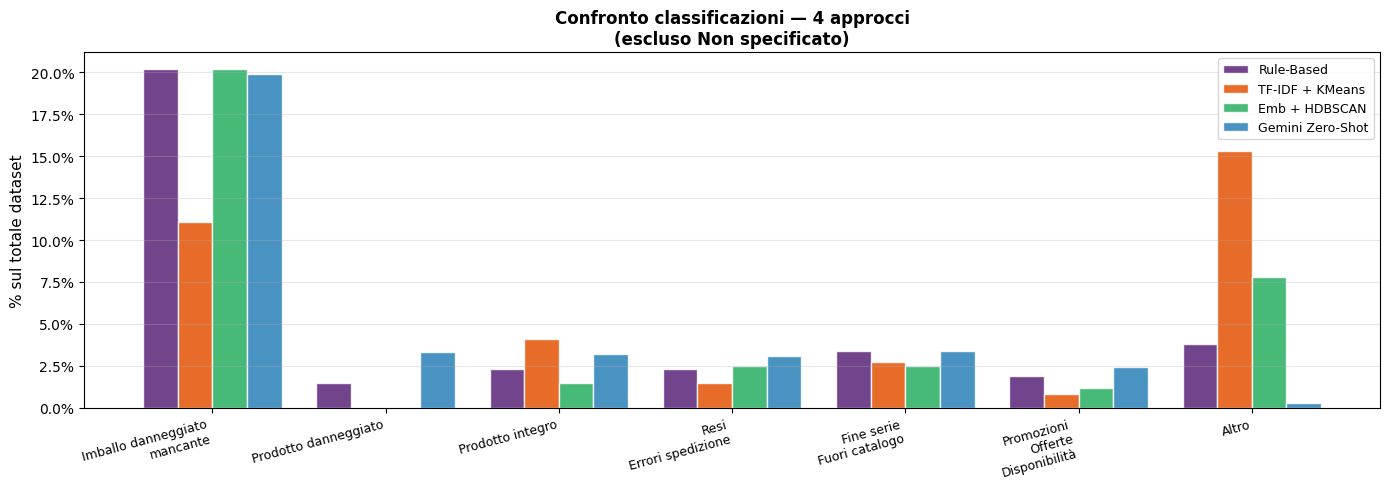

In [39]:
display(HTML('<h3>Confronto Finale tra i quattro Approcci</h3>'))

approcci = {'Rule-Based' : 'cat_rule', 'TF-IDF + KMeans' : 'cat_tfidf', 'Emb + HDBSCAN' : 'cat_emb', 'Gemini Zero-Shot' : 'cat_llm'}
approcci_ok = {k: v for k, v in approcci.items() if v in df.columns}

display(HTML('<b>Tabella comparativa</b> — distribuzione per categoria e approccio:'))
rows = []
for cat in CATEGORIE:
    row = {'Categoria': cat}
    for nome, col in approcci_ok.items():
        n = (df[col] == cat).sum()
        # Calcolo percentuale arrotondato rigorosamente per difetto (a 1 decimale)
        perc = np.floor((n / len(df)) * 1000) / 10
        row[nome] = f"{n:,} ({perc:.1f}%)"
    rows.append(row)
    
df_conf = pd.DataFrame(rows)
df_conf.index = df_conf.index + 1
display(df_conf)

# Grafico a barre grouped 
cat_plot   = [c for c in CATEGORIE if c != 'Non specificato']
fig, ax    = plt.subplots(figsize=(14, 5))
x          = np.arange(len(cat_plot))
width      = 0.8 / len(approcci_ok)
colori     = ['#592378', '#e35205', '#27ae60', '#2980b9']

for j, (nome, col) in enumerate(approcci_ok.items()):
    # Percentuali arrotondate per difetto anche nel grafico
    vals = [np.floor(((df[col] == cat).sum() / len(df)) * 1000) / 10 for cat in cat_plot]
    ax.bar(x + j * width, vals, width, label=nome, color=colori[j % len(colori)], edgecolor='white', alpha=0.85)

ax.set_xticks(x + width * (len(approcci_ok) - 1) / 2)
ax.set_xticklabels([c.replace(' / ', '\n') for c in cat_plot], rotation=15, ha='right', fontsize=9)
ax.set_ylabel('% sul totale dataset', fontsize=11)
ax.set_title('Confronto classificazioni — 4 approcci\n(escluso Non specificato)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Concordanza tra Rule-Based e Gemini
if 'cat_rule' in df.columns and 'cat_llm' in df.columns:
    mask_entrambi_val = ((df['cat_rule'] != 'Non specificato') & (df['cat_llm']  != 'Non specificato'))
    n_entrambi    = mask_entrambi_val.sum()
    n_concordano  = (df.loc[mask_entrambi_val, 'cat_rule'] == df.loc[mask_entrambi_val, 'cat_llm']).sum()
    perc_concordanza = np.floor((n_concordano / n_entrambi) * 1000) / 10
    display(HTML(f'<br><b>Concordanza Rule-Based vs Gemini</b> (sui record classificati da entrambi — {n_entrambi:,}): <b>{n_concordano:,} ({perc_concordanza:.1f}%)</b> in accordo.'))

In [40]:
# Analisi approfondita dei disaccordi Rule-Based vs Gemini 
mask_entrambi = ((df['cat_rule'] != 'Non specificato') & (df['cat_llm']  != 'Non specificato'))
df_confronto_rec = df[mask_entrambi][[COL_NOTE, 'cat_rule', 'cat_llm']].copy()
df_confronto_rec['concordano'] = df_confronto_rec['cat_rule'] == df_confronto_rec['cat_llm']

# Matrice di confusione tra i due approcci (solo sui casi discordanti)
df_discord = df_confronto_rec[~df_confronto_rec['concordano']]
matrice = pd.crosstab(df_discord['cat_rule'].rename('Rule-Based'), df_discord['cat_llm'].rename('Gemini'))
display(HTML('<b>Matrice di disaccordo (Rule-Based vs Gemini):</b>'))
display(matrice.style.background_gradient(cmap='Reds'))

# Top note su cui i due approcci divergono di più
# Visualizzazione stile dashboard con legenda e card
col_rule = "#89650C" 
col_llm  = "#164C92" 

display(HTML('<br><b>Esempi di note classificate diversamente:</b>'))

# Creazione della Legenda
legenda_html = f"""
<div style='margin-bottom: 15px; padding: 12px; background-color: #fdfdfd; border: 1px solid #eee; border-radius: 6px; font-size: 13.5px; max-width: 600px;'>
    <b style='color: #000;'>Legenda dei flussi di classificazione:</b><br>
    <div style='margin-top: 5px; color: #000;'>
        <span style='color:{col_rule}; font-size: 16px;'>■</span> <b>Rule-Based</b>: La categoria originariamente assegnata dalle espressioni regolari.<br>
        <span style='color:{col_llm}; font-size: 16px;'>■</span> <b>Gemini</b>: La nuova categoria assegnata dall'intelligenza artificiale.
    </div>
</div>
"""
display(HTML(legenda_html))

# Creazione delle Card per i Disaccordi
html_out = "<div style='display: flex; flex-wrap: wrap; gap: 15px; margin-top: 5px;'>"

# Ordiniamo i gruppi per dimensione (così vediamo prima i disaccordi più grandi)
gruppi = sorted(df_discord.groupby(['cat_rule', 'cat_llm']), key=lambda x: len(x[1]), reverse=True)

for (cat_rule, cat_llm), grp in gruppi:
    # Mostriamo solo i casi in cui ci sono almeno 3 disaccordi
    if len(grp) >= 3:
        # Prendiamo le 4 note più frequenti
        top_notes = grp[COL_NOTE].value_counts().head(4)
        
        # Generiamo la lista puntata con gli esempi testuali (tutto in nero)
        lis = "".join([
            f"<li style='margin-bottom: 5px; line-height: 1.3; color: #000;'>"
            f"<span style='color:#000;'>{nota}</span> "
            f"<b style='font-size:0.85em; color:#000;'>(x{freq})</b>"
            f"</li>" 
            for nota, freq in top_notes.items()])
        
        # Creiamo la singola Card HTML
        card = f"""
        <div style='border: 1px solid #eaeaea; border-left: 4px solid {col_rule}; border-radius: 8px; padding: 14px; min-width: 320px; flex: 1; background-color: #ffffff; box-shadow: 0 2px 6px rgba(0,0,0,0.03);'>
            <div style='font-size: 13.5px; margin-bottom: 12px; border-bottom: 1px solid #f0f0f0; padding-bottom: 8px; color: #000;'>
                <span style='color:{col_rule}; font-weight:bold;'>{cat_rule}</span> 
                <span style='color:#000; margin: 0 6px; font-size: 16px;'>➔</span> 
                <span style='color:{col_llm}; font-weight:bold;'>{cat_llm}</span>
                <span style='float:right; background:#f0f5fc; color:{col_llm}; padding:3px 10px; border-radius:12px; font-size:11px; font-weight:bold; border: 1px solid #dce8f6;'>{len(grp)} casi</span>
            </div>
            <ul style='font-size: 12.5px; margin: 0; padding-left: 20px; font-family: "Courier New", Courier, monospace;'>
                {lis}
            </ul>
        </div>
        """
        html_out += card

html_out += "</div>"

display(HTML(html_out))

Gemini,Altro,Fine serie / Fuori catalogo,Imballo danneggiato / mancante,Prodotto danneggiato,Prodotto integro,Promozioni / Offerte / Disponibilità,Resi / Errori spedizione
Rule-Based,,,,,,,
Altro,0,3,47,171,32,38,42
Fine serie / Fuori catalogo,1,0,0,0,0,9,0
Imballo danneggiato / mancante,0,4,0,2,88,0,14
Prodotto danneggiato,0,0,9,0,0,0,0
Prodotto integro,0,1,25,1,0,0,15
Promozioni / Offerte / Disponibilità,0,0,0,0,0,0,3


In [41]:
# Pulizia finale: rimozione solo delle colonne intermedie di lavoro 
cols_intermedie = [c for c in ['cat_rule', 'cat_tfidf', 'cat_emb'] if c in df.columns]
df.drop(columns=cols_intermedie, inplace=True)
df.rename(columns={'cat_llm': 'Nota Classificata'}, inplace=True)

display(HTML(f'<b>Dataset finale</b>: {df.shape[0]:,} righe × {df.shape[1]} colonne.<br>'
    f'Colonne mantenute: <code>Note Extra Usato</code> (testo grezzo) + <code>Nota Classificata</code> (classificazione Gemini).'))
display(df.columns.tolist())

['ID Prodotto',
 'Numero Articolo Catalogo',
 'Note Extra Usato',
 'Disponibilità',
 'Condizione Usato',
 'Imballaggio Presente',
 'Motivo Vendita',
 'Classe Energetica',
 'Prezzo Originale',
 'Prezzo Scontato',
 'Sconto',
 'Nome Negozio',
 'Tipologia Negozio',
 'Designer',
 'Materiali',
 'Cura',
 'Buono a sapersi + Sicurezza e conformità',
 'Informazioni Tecniche',
 'Misure',
 'Descrizione Completa',
 'Nota Classificata']

### **3.3.3. Consolidamento delle specifiche tecniche e dimensionali**

Meritano un degno approfondimento le **Informazioni Tecniche** e le **Misure** che condividono una caratteristica strutturale: entrambe contengono più informazioni all’interno di **stringhe semi-strutturate ad alta densità informativa**, in cui molteplici attributi sono concatenati mediante il separatore pipe (`Chiave: valore | Chiave: valore`). Data l'eterogeneità della struttura (fino a 24 campi tecnici e 16 attributi dimensionali per singolo record), necessaria è una pipeline di feature engineering per estrarre, normalizzare e validare i soli indicatori rilevanti per l'analisi.

-> **Informazioni tecniche**

In [ ]:
# Analisi preliminare della colonna
colonna_target = 'Informazioni Tecniche'
totale_righe = len(df)
righe_non_nulle = df[colonna_target].notna().sum()

print(f"Righe totali nel dataset: {totale_righe}")
print(f"Righe valorizzate in '{colonna_target}': {righe_non_nulle}")

# Prime 2 righe valorizzate
esempi = df[colonna_target].dropna().head(2)

print("\nEsempi di valori presenti nella colonna:")

for idx, valore in esempi.items():
    print(f"Indice: {idx}")
    print(valore)
    print("-" * 100)

### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
prima_riga_valida = df[colonna_target].first_valid_index()
riga_esempio = str(df.loc[prima_riga_valida, colonna_target])

print(f"Indice prima riga valida: {prima_riga_valida}")
print(f"Numero separatori '|': {riga_esempio.count('|')}")
print("-" * 50)

campi = riga_esempio.split('|')

print(f"Numero campi trovati: {len(campi)}")
print("-" * 50)

for i, campo in enumerate(campi):
    print(f"[{i:02d}] {campo.strip()}")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [44]:
conteggio_campi = (df[colonna_target].dropna().astype(str).apply(lambda x: len(x.split('|'))))
frequenze = (conteggio_campi.value_counts().sort_index().reset_index())
frequenze.columns = ['Numero campi', 'Numero righe']
tot = frequenze['Numero righe'].sum()
frequenze['Percentuale'] = (frequenze['Numero righe'] / tot * 100).round(2)

frequenze = frequenze.sort_values('Numero campi').reset_index(drop=True)

# Top 3 percentuali
top3 = frequenze.nlargest(3, 'Percentuale')['Percentuale'].tolist()

def highlight_top3(v):
    return 'background-color: #ad7895' if v in top3 else ''

frequenze.style.map(highlight_top3, subset=['Percentuale']).format({'Numero righe': '{:,.0f}', 'Percentuale': '{:.2f}%'}).hide(axis='index')

Numero campi,Numero righe,Percentuale
2,1,0.12%
6,5,0.62%
7,7,0.86%
8,60,7.39%
9,131,16.13%
10,101,12.44%
11,194,23.89%
12,3,0.37%
13,35,4.31%
14,110,13.55%


In [ ]:
key_counts = Counter()

for val in df[colonna_target].dropna():
    for parte in str(val).split('|'):
        parte = parte.strip()
        if ':' in parte:
            chiave = parte.split(':')[0].strip()
            key_counts[chiave] += 1

df_campi = pd.DataFrame(key_counts.most_common(), columns=['Campo', 'Frequenza'])
print(f"Campi unici trovati: {len(df_campi)}")
df_campi['% su righe valorizzate'] = (df_campi['Frequenza'] / righe_non_nulle * 100).round(2)
VALORI_NULLI = {'(nessun valore)', 'n.a', 'n.a.', 'N/A', ''}

def estrai_valori_campo(nome_campo):
    def _parse(testo):
        if pd.isna(testo):
            return None
        for parte in str(testo).split('|'):
            parte = parte.strip()
            if parte.startswith(nome_campo + ':'):
                valore = parte[len(nome_campo) + 1:].strip()
                return None if valore in VALORI_NULLI else valore
        return None

    return df[colonna_target].apply(_parse)

top_valori_list = []

for campo in df_campi['Campo']:
    valori = estrai_valori_campo(campo)
    top3 = (valori.dropna().value_counts().head(3).index.tolist())
    top_valori_list.append(top3)

df_campi['Top valori'] = top_valori_list
df_campi.style.background_gradient(subset=['Frequenza'], cmap='RdPu').format({'Frequenza': '{:,.0f}', '% su righe valorizzate': '{:.2f}%'}).hide(axis='index')


### [Output rimosso per tutela della privacy e riservatezza commerciale]

Si procede con il clustering semantico dei campi tecnici. Infatti, la semplice estrazione delle chiavi non fornisce alcuna informazione sulle relazioni logiche che intercorrono tra di esse. Per superare questo limite strutturale, si adotta un approccio basato sull'Elaborazione del Linguaggio Naturale (NLP). L'obiettivo è mappare le stringhe di testo (i nomi dei campi) in uno spazio vettoriale continuo, affinché campi con significato affine risultino vicini nello spazio matematico. L'approccio combina due sorgenti di informazione: sentence embeddings multilingua sui nomi dei campi, per catturare la similarità semantica; matrice di co-occurrence tra campi, per catturare la similarità strutturale (stessi prodotti).

In [46]:
campi_significativi = [campo for campo, freq in key_counts.items()]
print(f"Campi considerati per il clustering: {len(campi_significativi)}.")

# Modello multilingua leggero, ottimo per italiano
model = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
embeddings = model.encode(campi_significativi, show_progress_bar=True)
embeddings_norm = normalize(embeddings)
print(f"Shape embeddings: {embeddings_norm.shape}")

Campi considerati per il clustering: 104.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Shape embeddings: (104, 384)


In [47]:
# Quante volte due campi compaiono insieme nella stessa riga
n = len(campi_significativi)
cooc = np.zeros((n, n), dtype=int)

for val in df[colonna_target].dropna():
    presenti = set()
    for parte in str(val).split('|'):
        parte = parte.strip()
        if ':' in parte:
            chiave = parte.split(':')[0].strip()
            if chiave in campi_significativi:
                presenti.add(campi_significativi.index(chiave))
    for i in presenti:
        for j in presenti:
            cooc[i, j] += 1

# Normalizza in matrice di similarità (Jaccard)
jaccard = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        union = cooc[i, i] + cooc[j, j] - cooc[i, j]
        jaccard[i, j] = cooc[i, j] / union if union > 0 else 0

print("Co-occurrence matrix calcolata.")
print(f"Shape: {jaccard.shape}")

Co-occurrence matrix calcolata.
Shape: (104, 104)


In [48]:
# Peso combinato: 60% semantica, 40% co-occurrence
alpha = 0.6

# Conversione jaccard in distanza
cooc_sim_norm = jaccard / (jaccard.max() + 1e-9)

# Similarità coseno dagli embeddings
from sklearn.metrics.pairwise import cosine_similarity
sem_sim = cosine_similarity(embeddings_norm)

# Matrice combinata
combined_sim = alpha * sem_sim + (1 - alpha) * cooc_sim_norm
combined_dist = 1 - combined_sim
np.fill_diagonal(combined_dist, 0)

print("Matrice combinata pronta.")
print(f"Range distanze: [{combined_dist.min():.3f}, {combined_dist.max():.3f}].")

Matrice combinata pronta.
Range distanze: [0.000, 1.100].


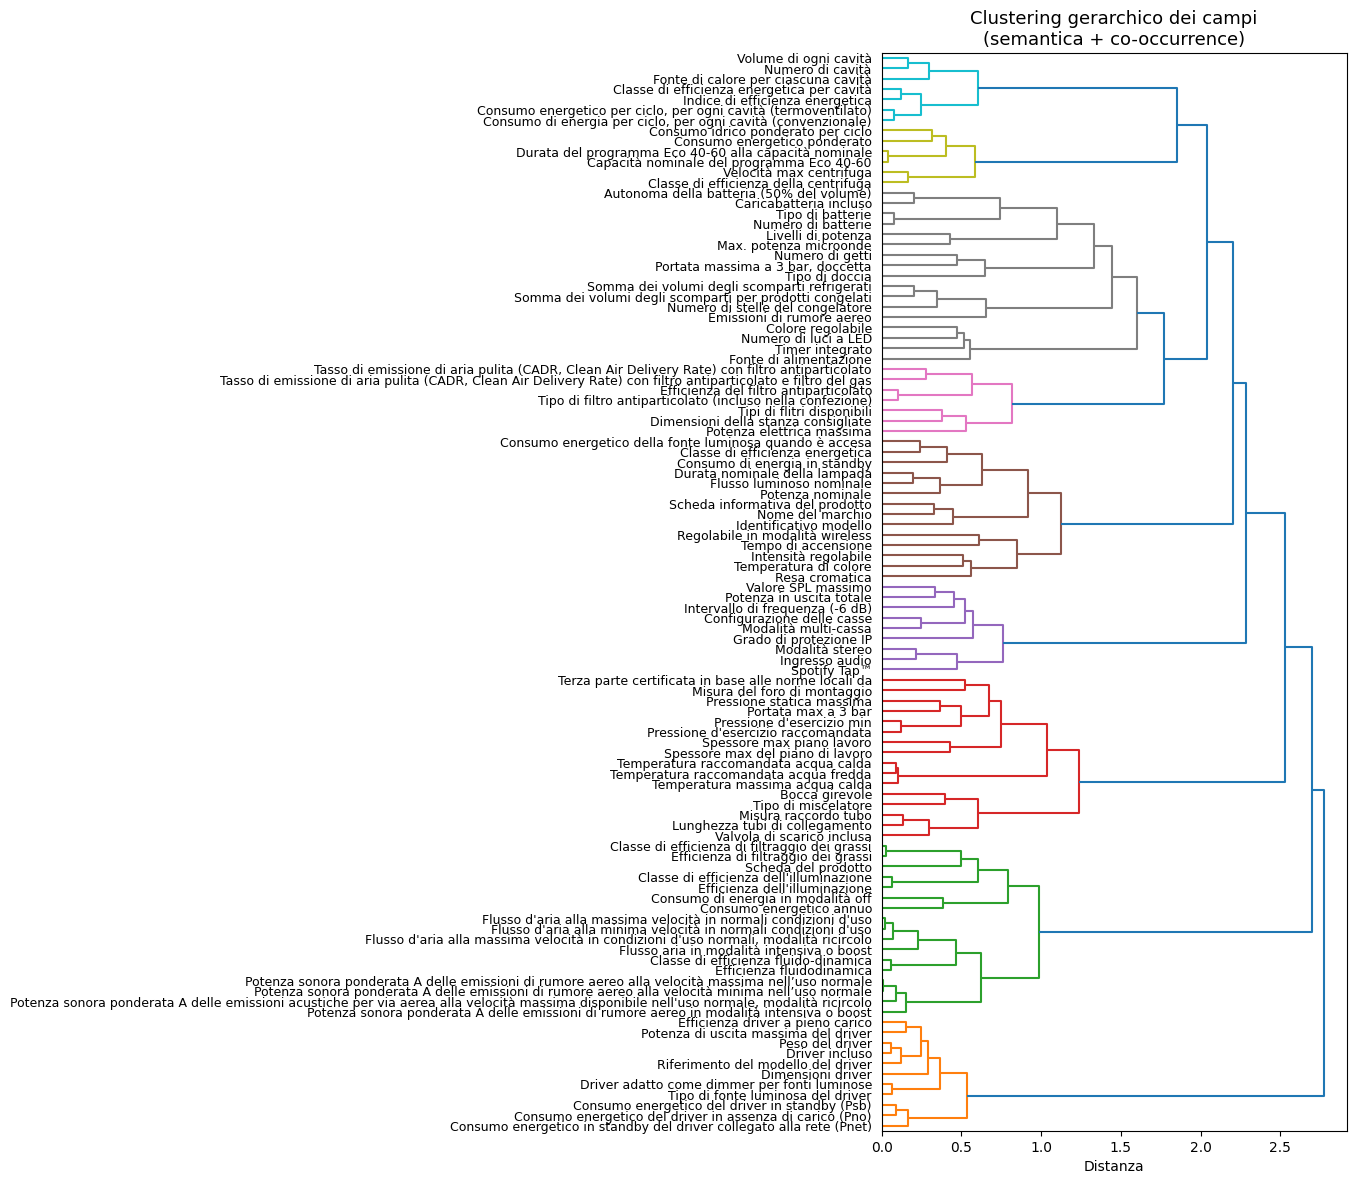

In [49]:
condensed = squareform(combined_dist)
Z = linkage(condensed, method='ward')

fig, ax = plt.subplots(figsize=(6, 14))
dendrogram(Z, labels=campi_significativi, orientation='right', leaf_font_size=9, color_threshold=0.6 * max(Z[:, 2]), ax=ax)
ax.set_title('Clustering gerarchico dei campi\n(semantica + co-occurrence)', fontsize=13)
ax.set_xlabel('Distanza')
plt.tight_layout()
plt.show()

Il dendrogramma offre una visione gerarchica completa, ma per ottenere cluster discreti e gestire automaticamente i campi anomali (non assegnabili a nessun gruppo), si applica un'altra strategia. Per l'estrazione definitiva dei gruppi semantici, infatti. l'approccio gerarchico viene superato in favore di una pipeline avanzata basata su densità, ideale per trattare spazi ad alta dimensionalità con rumore di fondo. La procedura si articola in due step: riduzione della Dimensionalità con UMAP; clustering basato su densità con HDBSCAN.

Cluster trovati: 12
Campi non assegnati (rumore): 0


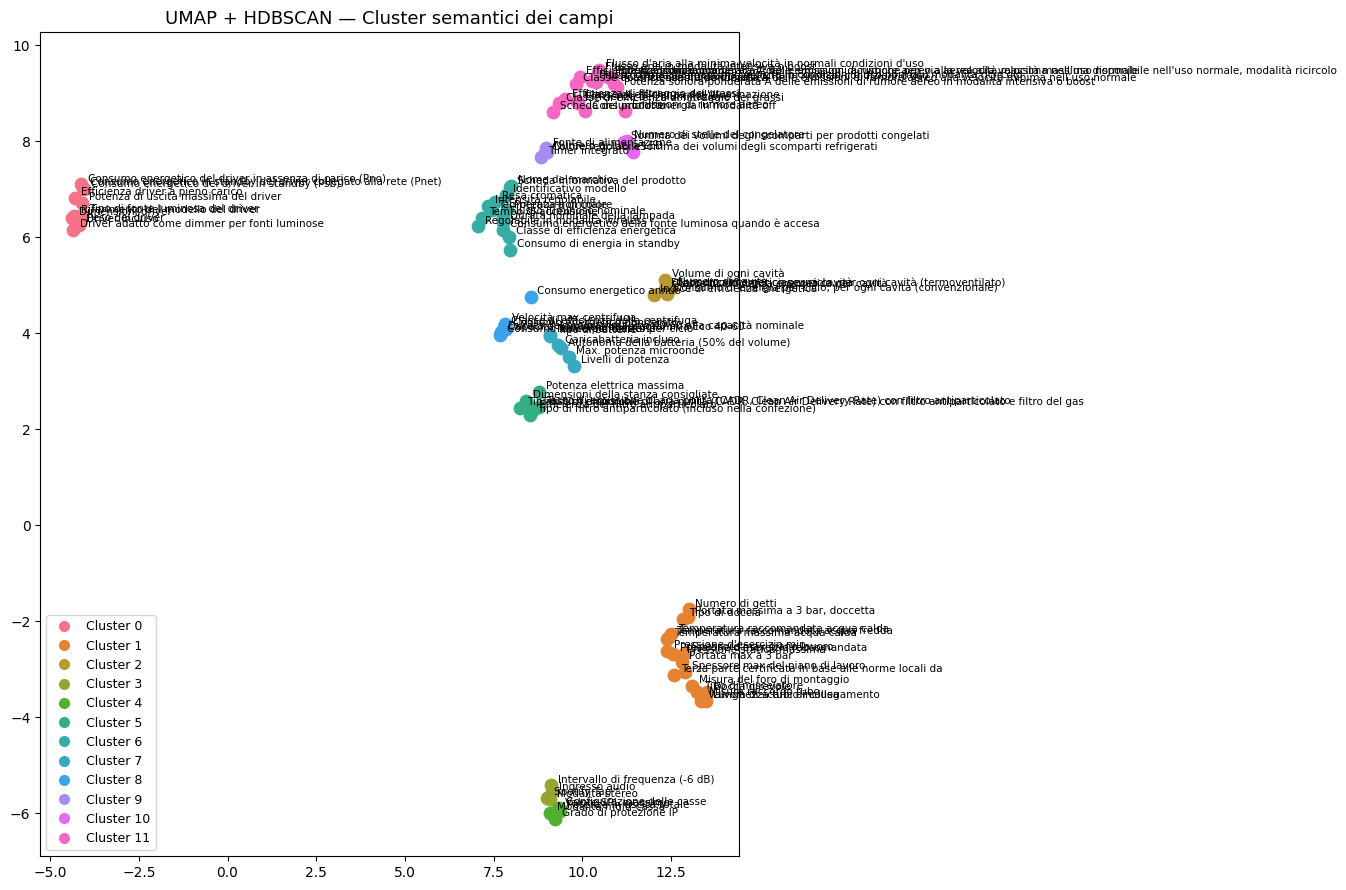

In [50]:
# UMAP (riduzione dimensionale)
reducer = umap.UMAP(n_neighbors=8, min_dist=0.1, metric='precomputed', random_state=42)
embedding_2d = reducer.fit_transform(combined_dist)

# HDBSCAN clustering
clusterer = hdbscan.HDBSCAN(min_cluster_size=3, min_samples=2, metric='euclidean')
labels = clusterer.fit_predict(embedding_2d)

# Statistiche cluster
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()

print(f"Cluster trovati: {n_clusters}")
print(f"Campi non assegnati (rumore): {n_noise}")

# Color map
unique_labels = sorted([l for l in set(labels) if l != -1])
palette = sns.color_palette('husl', n_colors=len(unique_labels))
color_map = {label: palette[i] for i, label in enumerate(unique_labels)}

# Visualizzazione
fig, ax = plt.subplots(figsize=(13, 9))

for i, (campo, label) in enumerate(zip(campi_significativi, labels)):
    color = color_map.get(label, (0.7, 0.7, 0.7))  
    ax.scatter(embedding_2d[i, 0], embedding_2d[i, 1], color=color, s=80, zorder=2)
    ax.annotate(campo, (embedding_2d[i, 0], embedding_2d[i, 1]), fontsize=7.5, ha='left', xytext=(5, 2), textcoords='offset points')

# Legenda
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[l], markersize=9, label=f'Cluster {l}') for l in unique_labels]

if n_noise > 0:
    handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=(0.7, 0.7, 0.7), markersize=9, label='Rumore'))

ax.legend(handles=handles, loc='best', fontsize=9)
ax.set_title('UMAP + HDBSCAN — Cluster semantici dei campi', fontsize=13)
plt.tight_layout()
plt.show()

In [51]:
df_cluster = pd.DataFrame({'Campo': campi_significativi, 'Cluster': labels, 'Frequenza': [key_counts[c] for c in campi_significativi]})

for cluster_id in sorted(df_cluster['Cluster'].unique()):
    label = f'Cluster {cluster_id}' if cluster_id != -1 else 'Non assegnati'
    subset = df_cluster[df_cluster['Cluster'] == cluster_id].sort_values('Frequenza', ascending=False)
    print(f"\n{'='*60}")
    print(f"  {label}  ({len(subset)} campi)")
    print(f"{'='*60}")
    for _, row in subset.iterrows():
        print(f"  [{row['Frequenza']:4d}]  {row['Campo']}")


  Cluster 0  (11 campi)
  [ 165]  Riferimento del modello del driver
  [ 165]  Potenza di uscita massima del driver
  [ 165]  Dimensioni driver
  [ 165]  Consumo energetico del driver in assenza di carico (Pno)
  [ 165]  Peso del driver
  [ 165]  Tipo di fonte luminosa del driver
  [ 165]  Efficienza driver a pieno carico
  [ 165]  Consumo energetico del driver in standby (Psb)
  [ 165]  Consumo energetico in standby del driver collegato alla rete (Pnet)
  [ 165]  Driver adatto come dimmer per fonti luminose
  [ 163]  Driver incluso

  Cluster 1  (19 campi)
  [ 112]  Temperatura raccomandata acqua fredda
  [ 112]  Pressione statica massima
  [ 112]  Pressione d'esercizio min
  [ 112]  Temperatura massima acqua calda
  [ 109]  Portata max a 3 bar
  [ 109]  Pressione d'esercizio raccomandata
  [ 103]  Terza parte certificata in base alle norme locali da
  [  98]  Temperatura raccomandata acqua calda
  [  93]  Misura del foro di montaggio
  [  82]  Misura raccordo tubo
  [  81]  Tipo di 

Tra i 104 campi identificati, la selezione delle feature è stata ristretta in modo mirato ai seguenti 6 campi: classe di efficienza energetica; classe di efficienza energetica per cavità; consumo energetico annuo; flusso luminoso nominale; portata max a 3 bar; efficienza fluidodinamica. La logica sottostante a questa selezione è duplice: da un lato, estrarre un parametro prestazionale rappresentativo per ogni singola categoria merceologica (illuminazione → flusso luminoso, idraulica → portata, cappe → efficienza fluidodinamica); dall'altro, isolare indicatori energetici trasversali che consentano la verifica di ridondanza con le colonne originali.

In [52]:
VALORI_NULLI = {'(nessun valore)', 'n.a', 'n.a.', 'n/a', 'N/A', 'NA', ''}
VALORI_NULLI_LOWER = {v.lower() for v in VALORI_NULLI}

campi_target = ['Classe di efficienza energetica', 'Classe di efficienza energetica per cavità', 'Consumo energetico annuo', 
                'Flusso luminoso nominale', 'Portata max a 3 bar', 'Efficienza fluidodinamica']

def estrai_valori_campo(nome_campo):
    def parse(testo):
        if pd.isna(testo):
            return None
        for parte in str(testo).split('|'):
            parte = parte.strip()
            if parte.startswith(nome_campo + ':'):
                valore = parte[len(nome_campo)+1:].strip()
                if valore.lower() in VALORI_NULLI_LOWER:
                    return None
                return valore
        return None
    return df[colonna_target].apply(parse)

# Tabella riassuntiva
summary = []

for campo in campi_target:
    serie = estrai_valori_campo(campo)
    n_valori = serie.notna().sum()
    n_unici = serie.nunique(dropna=True)
    copertura = round(key_counts.get(campo, 0) / righe_non_nulle * 100, 2)  # da key_counts come in cella 8
    summary.append({"Campo": campo, "Copertura %": copertura,
        "Valori": n_valori, "Valori unici": n_unici, "Rapporto unicità": round(n_unici / n_valori, 3) if n_valori else 0})

summary_df = pd.DataFrame(summary).sort_values("Copertura %", ascending=False)

display(summary_df.style.background_gradient(subset=["Copertura %"], cmap="Greens").background_gradient(subset=["Valori unici"], cmap="Blues").format({"Copertura %": "{:.2f}%", "Rapporto unicità": "{:.3f}"}).hide(axis="index"))

for campo in campi_target:
    serie = estrai_valori_campo(campo)
    totale = serie.notna().sum()
    copertura = round(key_counts.get(campo, 0) / righe_non_nulle * 100, 2)
    vc = serie.value_counts().head(15).reset_index()
    vc.columns = ["Valore", "Conteggio"]
    vc["% sul campo"] = (vc["Conteggio"] / totale * 100).round(2)
    print(f"\n{'='*80}")
    print(f"{campo}  —  Valori: {totale:,} | Unici: {serie.nunique(dropna=True):,} | Copertura: {copertura}%")
    print(f"{'='*80}")
    display(vc.style.bar(subset=["Conteggio"], color="#ad7895").format({"Conteggio": "{:,.0f}", "% sul campo": "{:.2f}%"}).hide(axis="index"))

Campo,Copertura %,Valori,Valori unici,Rapporto unicità
Classe di efficienza energetica,69.58%,565,8,0.014
Flusso luminoso nominale,60.96%,495,39,0.079
Consumo energetico annuo,20.07%,163,35,0.215
Portata max a 3 bar,13.42%,109,5,0.046
Efficienza fluidodinamica,4.80%,39,15,0.385
Classe di efficienza energetica per cavità,0.86%,7,2,0.286



Classe di efficienza energetica  —  Valori: 565 | Unici: 8 | Copertura: 69.58%


Valore,Conteggio,% sul campo
G,202,35.75%
F,130,23.01%
E,87,15.40%
D,66,11.68%
C,44,7.79%
A+,23,4.07%
A,9,1.59%
A++,4,0.71%



Classe di efficienza energetica per cavità  —  Valori: 7 | Unici: 2 | Copertura: 0.86%


Valore,Conteggio,% sul campo
A,5,71.43%
A+,2,28.57%


...

Valore,Conteggio,% sul campo
220 lumen.,47,9.49%
806 lumen.,44,8.89%
470 lumen.,39,7.88%
345 lumen.,38,7.68%
140 lumen.,35,7.07%
115 lumen.,32,6.46%
313 lumen.,28,5.66%
290 lumen.,26,5.25%
150 lumen.,22,4.44%
720 lumen.,17,3.43%



Portata max a 3 bar  —  Valori: 109 | Unici: 5 | Copertura: 13.42%


Valore,Conteggio,% sul campo
"8,0 l/min",58,53.21%
"5,7 l/min",36,33.03%
"9,5 l/min",12,11.01%
"7,0 l/min",2,1.83%
"7,5 l/min",1,0.92%



Efficienza fluidodinamica  —  Valori: 39 | Unici: 15 | Copertura: 4.8%


Valore,Conteggio,% sul campo
31.6 %,6,15.38%
34.8 %,5,12.82%
"37,6 %",4,10.26%
35.4 %,4,10.26%
35.2 %,3,7.69%
35.1 %,3,7.69%
37.6 %,2,5.13%
"15,5 %",2,5.13%
"33,1 %",2,5.13%
"29,9 %",2,5.13%


In [53]:
campi_numerici = {'Consumo energetico annuo':  'Consumo energetico annuo (kWh/anno)',
    'Flusso luminoso nominale':  'Flusso luminoso nominale (lm)',
    'Portata max a 3 bar':       'Portata max 3 bar (l/min)',
    'Efficienza fluidodinamica': 'Efficienza fluidodinamica (%)'}

campi_categoriali = {'Classe di efficienza energetica': 'Classe efficienza energetica',
                     'Classe di efficienza energetica per cavità': 'Classe efficienza energetica cavita'}

# Funzione per estrarre il primo numero dal testo
# Per esempio: '698 kWh/p.a.' -> 698.0; '8,0 l/min' -> 8.0; '37,6 %' -> 37.6.

def parse_numero(valore):

    if pd.isna(valore):
        return None

    match = re.search(r'(\d+(?:[.,]\d+)?)', str(valore))
    if match:
        return float(match.group(1).replace(',', '.'))
    
    return None

# Analizza le unità di misura presenti e verifica se sono coerenti.
def analizza_unita(nome_campo, serie):
    unita = (serie.dropna().astype(str).str.strip().str.extract(r'^[\d.,]+\s*(.*)$')[0].str.strip().replace('', '(nessuna unità)').value_counts().rename_axis('Unità').reset_index(name='Occorrenze'))
    print("\n" + "=" * 90)
    print(f"{nome_campo}")
    print("=" * 90)

    display(unita)

    if len(unita) == 1:
        print(f"Unità coerente: {unita.iloc[0]['Unità']}.")

    else:
        print(f"Attenzione: trovate {len(unita)} unità differenti.")
        # Caso noto: kWh/p.a. e kWh/anno
        unita_norm = (unita['Unità'].str.lower().str.replace('kwh/p.a.', 'kwh/anno', regex=False))
        if unita_norm.nunique() == 1:
            print("Le unità sembrano equivalenti (solo differenze di scrittura).")

# Analisi delle unità di misura
print("\nANALISI DELLE UNITA' DI MISURA")

for campo in campi_numerici:
    serie = estrai_valori_campo(campo)
    analizza_unita(nome_campo=campo, serie=serie)

# Creazione delle feature numeriche
print("\nCREAZIONE DELLE FEATURE NUMERICHE")

for campo_origine, colonna_destinazione in campi_numerici.items():
    df[colonna_destinazione] = (estrai_valori_campo(campo_origine).apply(parse_numero))
    print(f"-> Creata colonna: {colonna_destinazione}.")

# Creazione delle feature categoriali
print("\nCREAZIONE DELLE FEATURE CATEGORIALI")

for campo_origine, colonna_destinazione in campi_categoriali.items():
    df[colonna_destinazione] = (estrai_valori_campo(campo_origine))
    print(f"-> Creata colonna: {colonna_destinazione}.")

# Riepilogo finale
colonne_generate = (list(campi_numerici.values()) + list(campi_categoriali.values()))

riepilogo = pd.DataFrame({'Colonna': colonne_generate, 'Valori non nulli': [df[c].notna().sum() for c in colonne_generate],
    'Valori unici': [df[c].nunique(dropna=True) for c in colonne_generate]})

print("\nRIEPILOGO FEATURE CREATE")
display(riepilogo)


ANALISI DELLE UNITA' DI MISURA

Consumo energetico annuo


,Unità,Occorrenze
0,kWh/p.a.,112
1,kWh/anno,51


Attenzione: trovate 2 unità differenti.
Le unità sembrano equivalenti (solo differenze di scrittura).

Flusso luminoso nominale


,Unità,Occorrenze
0,lumen.,495


Unità coerente: lumen..

Portata max a 3 bar


,Unità,Occorrenze
0,l/min,109


Unità coerente: l/min.

Efficienza fluidodinamica


,Unità,Occorrenze
0,%,39


Unità coerente: %.

CREAZIONE DELLE FEATURE NUMERICHE
-> Creata colonna: Consumo energetico annuo (kWh/anno).
-> Creata colonna: Flusso luminoso nominale (lm).
-> Creata colonna: Portata max 3 bar (l/min).
-> Creata colonna: Efficienza fluidodinamica (%).

CREAZIONE DELLE FEATURE CATEGORIALI
-> Creata colonna: Classe efficienza energetica.
-> Creata colonna: Classe efficienza energetica cavita.

RIEPILOGO FEATURE CREATE


,Colonna,Valori non nulli,Valori unici
0,Consumo energetico annuo (kWh/anno),163,35
1,Flusso luminoso nominale (lm),495,39
2,Portata max 3 bar (l/min),109,5
3,Efficienza fluidodinamica (%),39,13
4,Classe efficienza energetica,565,8
5,Classe efficienza energetica cavita,7,2


-> **Classe Energetica: Riconciliazione dei Dati e Validazione**

Istituite le sei nuove colonne estratte dai campi tecnici, l'analisi si sposta verso l'obiettivo centrale di data quality: la verifica delle ridondanze e delle incoerenze informative. 

In [54]:
# Funzione di Parsing e Visualizzazione
def parse_classe_energetica_originale(valore):
    risultato = {'e_cavita': False, 'classe_estratta': None}
    if pd.isna(valore) or str(valore).strip().lower() in {'no info', '', 'nan'}:
        return risultato
    testo = str(valore).strip()
    risultato['e_cavita'] = 'cavit' in testo.lower()
    match = re.search(r'\s(A\+\+\+|A\+\+|A\+|A|B|C|D|E|F|G)\s*$', testo)
    if match:
        risultato['classe_estratta'] = match.group(1)
    return risultato

parsed = df['Classe Energetica'].apply(parse_classe_energetica_originale)
df['Classe Originale'] = parsed.apply(lambda x: x['classe_estratta'])
df['Classe Originale Cavita'] = parsed.apply(lambda x: x['e_cavita'])

def stile_base(df_styler):
    return (df_styler.set_properties(**{'color': 'black', 'background-color': 'white'}).hide(axis='index'))

# Colonna originale grezza
print("COLONNA ORIGINALE (valori grezzi)\n")
display(stile_base(df['Classe Energetica'].value_counts(dropna=False).rename_axis('Valore').reset_index(name='Conteggio').style.bar(subset=['Conteggio'], color='#ad7895').format({'Conteggio': '{:,.0f}'})))

# Dopo il parsing
print("\nDOPO IL PARSING\n")

# Tabella 1: classe standard estratta
standard_orig = df.loc[~df['Classe Originale Cavita'] & df['Classe Originale'].notna(), 'Classe Originale']
n_standard_orig = len(standard_orig)
print(f"Classe Energetica standard — {n_standard_orig} righe valorizzate\n")
display(stile_base(standard_orig.value_counts().rename_axis('Classe').reset_index(name='Conteggio').assign(**{'%': lambda x: (x['Conteggio'] / n_standard_orig * 100).round(2)}).style.bar(subset=['Conteggio'], color='#ad7895').format({'Conteggio': '{:,.0f}', '%': '{:.2f}%'})))

# Tabella 2: classe cavità estratta
cavita_orig = df.loc[df['Classe Originale Cavita'] & df['Classe Originale'].notna(), 'Classe Originale']
n_cavita_orig = len(cavita_orig)
print(f"\nClasse Energetica per cavità — {n_cavita_orig} righe valorizzate\n")
display(stile_base(cavita_orig.value_counts().rename_axis('Classe').reset_index(name='Conteggio').assign(**{'%': lambda x: (x['Conteggio'] / n_cavita_orig * 100).round(2)}).style.bar(subset=['Conteggio'], color='#ad7895').format({'Conteggio': '{:,.0f}', '%': '{:.2f}%'})))

COLONNA ORIGINALE (valori grezzi)



Valore,Conteggio
No info,"8,832"
Classe di efficienza energetica G,204
Classe di efficienza energetica F,129
Classe di efficienza energetica E,87
Classe di efficienza energetica D,66
Classe di efficienza energetica C,44
Classe di efficienza energetica A+,23
Classe di efficienza energetica A,9
Classe di efficienza energetica per cavità A,5
Classe di efficienza energetica A++,4



DOPO IL PARSING

Classe Energetica standard — 566 righe valorizzate



Classe,Conteggio,%
G,204,36.04%
F,129,22.79%
E,87,15.37%
D,66,11.66%
C,44,7.77%
A+,23,4.06%
A,9,1.59%
A++,4,0.71%



Classe Energetica per cavità — 7 righe valorizzate



Classe,Conteggio,%
A,5,71.43%
A+,2,28.57%


In [55]:
# Confronto: percorso standard e percorso cavità

def classifica_confronto(row):
    classe_orig = row['Classe Originale']
    e_cavita = row['Classe Originale Cavita']
    classe_nuova = (row['Classe efficienza energetica cavita'] if e_cavita else row['Classe efficienza energetica'])
    fonte = 'cavità' if e_cavita else 'standard'

    orig_presente  = pd.notna(classe_orig)  and str(classe_orig).strip()  != ''
    nuova_presente = pd.notna(classe_nuova) and str(classe_nuova).strip() != ''

    if not orig_presente and not nuova_presente: return 'Entrambe assenti'
    elif orig_presente and not nuova_presente: return 'Solo in originale'
    elif not orig_presente and  nuova_presente: return 'Solo in estratta'
    elif classe_orig.strip().upper() == classe_nuova.strip().upper(): return f'Match ({fonte})'
    else: return f'Incoerenza ({fonte})'

df['Esito Confronto'] = df.apply(classifica_confronto, axis=1)

def tabella_percorso(label, n_orig, n_nuova, n_entrambe, n_match, n_incoerenza, n_solo_orig=None, n_solo_nuova=None):

    righe = [{'Metrica': 'Originale valorizzata', 'Conteggio': n_orig, '%': None, 'Nota': 'totale righe disponibili nella colonna originale'},
        {'Metrica': 'Estratta valorizzata',  'Conteggio': n_nuova, '%': None, 'Nota': 'totale righe disponibili nella colonna estratta'},
        {'Metrica': 'Entrambe valorizzate',  'Conteggio': n_entrambe, '%': None, 'Nota': '← base del confronto'},
        {'Metrica': 'Match',      'Conteggio': n_match, '%': round(n_match / n_entrambe * 100, 1) if n_entrambe else None, 'Nota': '% su entrambe valorizzate'},
        {'Metrica': 'Incoerenze', 'Conteggio': n_incoerenza, '%': round(n_incoerenza / n_entrambe * 100, 1) if n_entrambe else None, 'Nota': '% su entrambe valorizzate'},]

    if n_solo_orig is not None:
        righe.append({'Metrica': 'Solo in originale', 'Conteggio': n_solo_orig, '%': round(n_solo_orig / n_orig * 100, 1) if n_orig else None, 'Nota': '% su originale valorizzata'})

    if n_solo_nuova is not None:
        righe.append({'Metrica': 'Solo in estratta', 'Conteggio': n_solo_nuova, '%': round(n_solo_nuova / n_nuova * 100, 1) if n_nuova else None, 'Nota': '% su estratta valorizzata'})

    tbl = pd.DataFrame(righe)

    def colore_riga(metrica):
        if metrica == 'Entrambe valorizzate':
            return 'background-color: #e8f4e8; color: black'
        if metrica in ('Match', 'Incoerenze'):
            return 'background-color: #f7e6f0; color: black'
        if metrica in ('Solo in originale', 'Solo in estratta'):
            return 'background-color: #ffe0b2; color: black'
        return 'background-color: white; color: black'

    display(tbl.style.set_caption(label).apply(lambda col: [colore_riga(v) for v in col], subset=['Metrica']).set_properties(subset=['Conteggio', '%', 'Nota'], **{'color': 'black', 'background-color': '#eae4e4'})
        .format({'Conteggio': lambda x: f'{x:,.0f}' if pd.notna(x) else '', '%': lambda x: f'{x:.1f}%' if pd.notna(x) else ''})
        .set_table_styles([{'selector': 'caption', 'props': [('caption-side', 'top'),('text-align', 'left'),('font-size', '14px'),('font-weight', 'bold'),('background-color', '#ad7895'),('color', 'white'),('padding', '8px')]}]).hide(axis='index'))

# Percorso Standard
std = df[~df['Classe Originale Cavita']].copy()
tabella_percorso(label = 'PERCORSO STANDARD (senza cavità)', n_orig = std['Classe Originale'].notna().sum(), n_nuova = std['Classe efficienza energetica'].notna().sum(),
    n_entrambe = (std['Classe Originale'].notna() & std['Classe efficienza energetica'].notna()).sum(), n_match = (std['Esito Confronto'] == 'Match (standard)').sum(),
    n_incoerenza = (std['Esito Confronto'] == 'Incoerenza (standard)').sum(), n_solo_orig = (std['Esito Confronto'] == 'Solo in originale').sum(), n_solo_nuova = (std['Esito Confronto'] == 'Solo in estratta').sum(),)

# Percorso Cavità
cav = df[df['Classe Originale Cavita']].copy()
tabella_percorso(label = 'PERCORSO CAVITÀ', n_orig = cav['Classe Originale'].notna().sum(), n_nuova = cav['Classe efficienza energetica cavita'].notna().sum(),
    n_entrambe = (cav['Classe Originale'].notna() & cav['Classe efficienza energetica cavita'].notna()).sum(), n_match = (cav['Esito Confronto'] == 'Match (cavità)').sum(),
    n_incoerenza = (cav['Esito Confronto'] == 'Incoerenza (cavità)').sum(),)

# Focus sui casi critici
for esito, label in [('Solo in originale', 'SOLO IN ORIGINALE'), ('Solo in estratta', 'SOLO IN ESTRATTA'), ('Incoerenza (standard)', 'INCOERENZE STANDARD'), ('Incoerenza (cavità)', 'INCOERENZE CAVITÀ')]:
    subset = df[df['Esito Confronto'] == esito]
    print(f"\n{label}: {len(subset)} record")
    if len(subset) > 0:
        display(subset[['ID Prodotto', 'Classe Energetica', 'Classe Originale', 'Classe efficienza energetica', 'Classe efficienza energetica cavita', 'Esito Confronto']]
            .style.set_properties(**{'color': 'black', 'background-color': '#eae4e4'}).highlight_null(color='#f5c6cb').hide(axis='index'))

Metrica,Conteggio,%,Nota
Originale valorizzata,566,,totale righe disponibili nella colonna originale
Estratta valorizzata,565,,totale righe disponibili nella colonna estratta
Entrambe valorizzate,563,,← base del confronto
Match,563,100.0%,% su entrambe valorizzate
Incoerenze,0,0.0%,% su entrambe valorizzate
Solo in originale,3,0.5%,% su originale valorizzata
Solo in estratta,2,0.4%,% su estratta valorizzata


Metrica,Conteggio,%,Nota
Originale valorizzata,7,,totale righe disponibili nella colonna originale
Estratta valorizzata,7,,totale righe disponibili nella colonna estratta
Entrambe valorizzate,7,,← base del confronto
Match,7,100.0%,% su entrambe valorizzate
Incoerenze,0,0.0%,% su entrambe valorizzate



SOLO IN ORIGINALE: 3 record


ID Prodotto,Classe Energetica,Classe Originale,Classe efficienza energetica,Classe efficienza energetica cavita,Esito Confronto
3337486,Classe di efficienza energetica G,G,nan,nan,Solo in originale
3086840,Classe di efficienza energetica G,G,nan,nan,Solo in originale
3068697,Classe di efficienza energetica G,G,nan,nan,Solo in originale



SOLO IN ESTRATTA: 2 record


ID Prodotto,Classe Energetica,Classe Originale,Classe efficienza energetica,Classe efficienza energetica cavita,Esito Confronto
2989995,No info,nan,G,nan,Solo in estratta
2985409,No info,nan,F,nan,Solo in estratta



INCOERENZE STANDARD: 0 record

INCOERENZE CAVITÀ: 0 record


In [56]:
# Rinconciliazione "Solo in originale" + Pulizia
solo_originale = df[df['Esito Confronto'] == 'Solo in originale'].copy()

print("Record da copiare dall'originale all'estratta:")
display(solo_originale[['ID Prodotto', 'Numero Articolo Catalogo', 'Classe Energetica', 'Classe Originale', 'Classe efficienza energetica']].style
    .set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb').hide(axis='index'))

# Copia originale → estratta dove mancante
mask_solo_orig = df['Esito Confronto'] == 'Solo in originale'
df.loc[mask_solo_orig, 'Classe efficienza energetica'] = df.loc[mask_solo_orig, 'Classe Originale']
print(f"\nCopiati {mask_solo_orig.sum()} valori: 'Classe Originale' → 'Classe efficienza energetica'.")

Record da copiare dall'originale all'estratta:


ID Prodotto,Numero Articolo Catalogo,Classe Energetica,Classe Originale,Classe efficienza energetica
3337486,70529366,Classe di efficienza energetica G,G,nan
3086840,70529366,Classe di efficienza energetica G,G,nan
3068697,70529366,Classe di efficienza energetica G,G,nan



Copiati 3 valori: 'Classe Originale' → 'Classe efficienza energetica'.


In [57]:
# Controllo per i record presenti solo nella colonna estratta
solo_estratta = df[df['Esito Confronto'] == 'Solo in estratta'].copy()

print(f"Record 'Solo in estratta': {len(solo_estratta)}.")
print(f"ID Prodotto: {solo_estratta['ID Prodotto'].tolist()}.")
print(f"Numero Articolo Catalogo: {solo_estratta['Numero Articolo Catalogo'].tolist()}.\n")

for _, row in solo_estratta.iterrows():
    nac = row['Numero Articolo Catalogo']
    stessa_famiglia = df[df['Numero Articolo Catalogo'] == nac][['ID Prodotto', 'Numero Articolo Catalogo', 'Classe Energetica', 'Classe efficienza energetica', 'Esito Confronto']].copy()

    print(f"Numero Articolo Catalogo: {nac}  ({len(stessa_famiglia)} record con lo stesso Numero Articolo Catalogo)")
    display(stessa_famiglia.style.set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb')
        .map(lambda v: 'background-color: #e8f4e8; color: black' if v == 'Solo in estratta' else '', subset=['Esito Confronto']).hide(axis='index'))
    print()

Record 'Solo in estratta': 2.
ID Prodotto: ['2989995', '2985409'].
Numero Articolo Catalogo: ['10529227', '00529794'].

Numero Articolo Catalogo: 10529227  (7 record con lo stesso Numero Articolo Catalogo)


ID Prodotto,Numero Articolo Catalogo,Classe Energetica,Classe efficienza energetica,Esito Confronto
3184737,10529227,Classe di efficienza energetica G,G,Match (standard)
2925794,10529227,Classe di efficienza energetica G,G,Match (standard)
2989995,10529227,No info,G,Solo in estratta
3356259,10529227,Classe di efficienza energetica G,G,Match (standard)
3086407,10529227,Classe di efficienza energetica G,G,Match (standard)
3420048,10529227,Classe di efficienza energetica G,G,Match (standard)
2610964,10529227,Classe di efficienza energetica G,G,Match (standard)



Numero Articolo Catalogo: 00529794  (17 record con lo stesso Numero Articolo Catalogo)


ID Prodotto,Numero Articolo Catalogo,Classe Energetica,Classe efficienza energetica,Esito Confronto
3071135,00529794,Classe di efficienza energetica F,F,Match (standard)
2930639,00529794,Classe di efficienza energetica F,F,Match (standard)
2792654,00529794,Classe di efficienza energetica F,F,Match (standard)
3133316,00529794,Classe di efficienza energetica F,F,Match (standard)
3387030,00529794,Classe di efficienza energetica F,F,Match (standard)
3333711,00529794,Classe di efficienza energetica F,F,Match (standard)
3389026,00529794,Classe di efficienza energetica F,F,Match (standard)
3417331,00529794,Classe di efficienza energetica F,F,Match (standard)
2630662,00529794,Classe di efficienza energetica F,F,Match (standard)
3097859,00529794,Classe di efficienza energetica F,F,Match (standard)


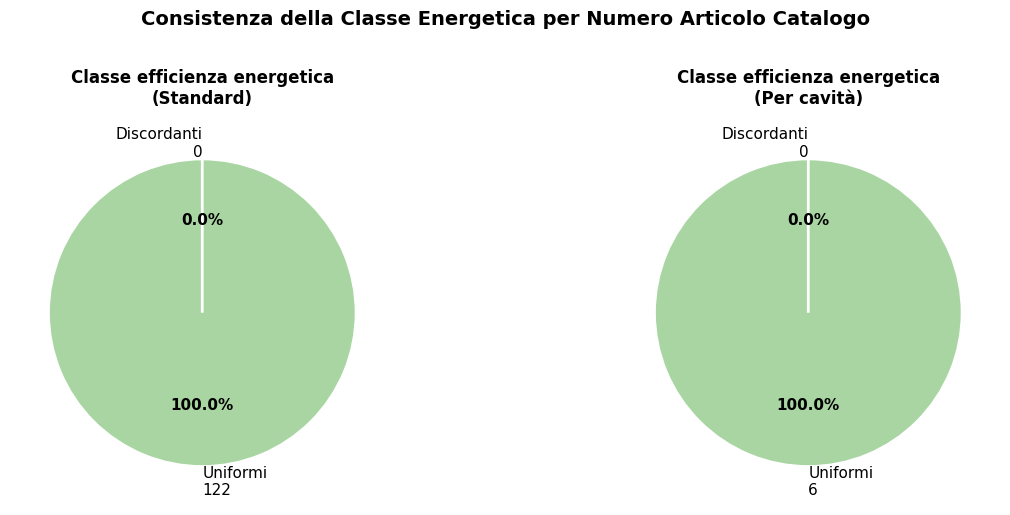


───────────────────────────────────────────────────────
  Classe efficienza energetica — Standard
───────────────────────────────────────────────────────
  Numero Articolo Catalogo valorizzati:         122
  Numero Articolo Catalogo uniformi:            122  ✓
  Numero Articolo Catalogo discordanti:           0  ✓

───────────────────────────────────────────────────────
  Classe efficienza energetica — Per cavità
───────────────────────────────────────────────────────
  Numero Articolo Catalogo valorizzati:           6
  Numero Articolo Catalogo uniformi:              6  ✓
  Numero Articolo Catalogo discordanti:           0  ✓


In [58]:
# Verifica consistenza per Numero Articolo Catalogo
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Consistenza della Classe Energetica per Numero Articolo Catalogo', fontsize=14, fontweight='bold', y=1.02)

for ax, (col_check, label_check) in zip(axes, [('Classe efficienza energetica',        'Standard'), ('Classe efficienza energetica cavita', 'Per cavità'),]):
    sotto = df[df[col_check].notna()].copy()
    varianza = (sotto.groupby('Numero Articolo Catalogo')[col_check].nunique().reset_index(name='Valori distinti'))
    n_uniformi     = (varianza['Valori distinti'] == 1).sum()
    n_discordanti  = (varianza['Valori distinti'] > 1).sum()

    # Pie chart
    valori = [n_uniformi, n_discordanti]
    colori = ['#a8d5a2', '#f4a7b9']
    etichette = [f'Uniformi\n{n_uniformi}', f'Discordanti\n{n_discordanti}']
    wedges, texts, autotexts = ax.pie(valori, labels=etichette, colors=colori, autopct='%1.1f%%', startangle=90, textprops={'color': 'black', 'fontsize': 11}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
    
    for at in autotexts:
        at.set_color('black')
        at.set_fontweight('bold')

    ax.set_title(f'Classe efficienza energetica\n({label_check})', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

# Tabella di dettaglio per ciascuna colonna
for col_check, label_check in [('Classe efficienza energetica',        'Standard'), ('Classe efficienza energetica cavita', 'Per cavità'),]:
    sotto = df[df[col_check].notna()].copy()
    varianza = (sotto.groupby('Numero Articolo Catalogo')[col_check].nunique().reset_index(name='Valori distinti'))
    inconsistenti = varianza[varianza['Valori distinti'] > 1]
    print(f"\n{'─'*55}")
    print(f"  Classe efficienza energetica — {label_check}")
    print(f"{'─'*55}")
    print(f"  Numero Articolo Catalogo valorizzati:       {len(varianza):>5}")
    print(f"  Numero Articolo Catalogo uniformi:          {(varianza['Valori distinti'] == 1).sum():>5}  ✓")
    print(f"  Numero Articolo Catalogo discordanti:       {len(inconsistenti):>5}  {'⚠' if len(inconsistenti) > 0 else '✓'}")

    if len(inconsistenti) > 0:
        nac_disc = inconsistenti['Numero Articolo Catalogo'].tolist()
        dettaglio = df[df['Numero Articolo Catalogo'].isin(nac_disc)][['ID Prodotto', 'Numero Articolo Catalogo', col_check]].sort_values('Numero Articolo Catalogo')
        print()
        display(dettaglio.style.set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb').hide(axis='index'))

Colonna 'Classe Energetica' originale rimossa (ridondante).
Colonne temporanee rimosse.

Shape dataset: (9405, 26)


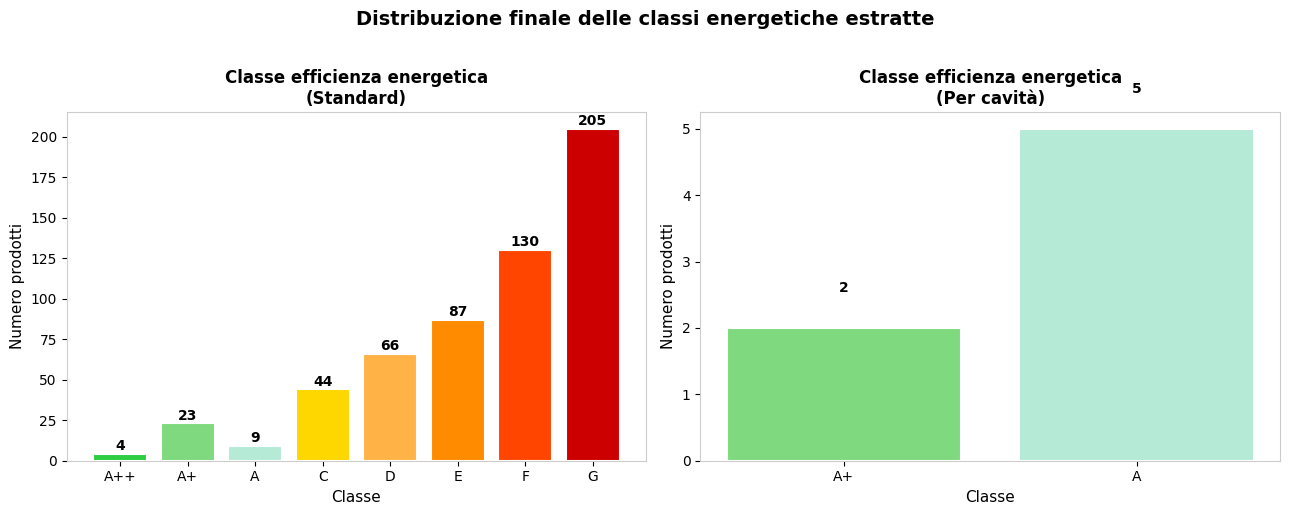


REPILOGO FINALE

Classe efficienza energetica  —  568 valorizzate



Classe,Conteggio,%
A++,4,0.70%
A+,23,4.05%
A,9,1.58%
C,44,7.75%
D,66,11.62%
E,87,15.32%
F,130,22.89%
G,205,36.09%



Classe efficienza energetica cavita  —  7 valorizzate



Classe,Conteggio,%
A+,2,28.57%
A,5,71.43%


In [59]:
# Rimozione colonna originale e temporanee
df.drop(columns=['Classe Energetica', 'Classe Originale', 'Classe Originale Cavita', 'Esito Confronto'], inplace=True)
print(f"Colonna 'Classe Energetica' originale rimossa (ridondante).")
print(f"Colonne temporanee rimosse.")
print(f"\nShape dataset: {df.shape}")

# Riepilogo finale: distribuzione colonne estratte

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribuzione finale delle classi energetiche estratte', fontsize=14, fontweight='bold', y=1.02)

# Ordine scala energetica
ordine = ['A+++', 'A++', 'A+', 'A', 'B', 'C', 'D', 'E', 'F', 'G']

for ax, (col, titolo) in zip(axes, [('Classe efficienza energetica',        'Standard'), ('Classe efficienza energetica cavita', 'Per cavità'),]):
    vc = df[col].value_counts(dropna=True)
    vc = vc.reindex([c for c in ordine if c in vc.index])

    colori_classe = {'A+++': '#1a7a1a', 'A++': '#2ecc40', 'A+': '#7fda7f', 'A': '#b5ead7', 'B': '#fffacd', 'C': '#ffd700', 'D': '#ffb347', 'E': '#ff8c00', 'F': '#ff4500', 'G': '#cc0000'}
    bar_colors = [colori_classe.get(c, '#ad7895') for c in vc.index]
    bars = ax.bar(vc.index, vc.values, color=bar_colors, edgecolor='white', linewidth=1.5)

    for bar, val in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, str(val), ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')

    ax.set_title(f'Classe efficienza energetica\n({titolo})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Classe', fontsize=11)
    ax.set_ylabel('Numero prodotti', fontsize=11)
    ax.tick_params(colors='black')
    ax.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#cccccc')

plt.tight_layout()
plt.show()

# Tabelle riepilogative finali
print("\nREPILOGO FINALE\n")
for col in ['Classe efficienza energetica', 'Classe efficienza energetica cavita']:
    n = df[col].notna().sum()
    print(f"{col}  —  {n} valorizzate\n")
    vc = df[col].value_counts(dropna=True)
    vc = vc.reindex([c for c in ordine if c in vc.index])
    display(vc.rename_axis('Classe').reset_index(name='Conteggio').assign(**{'%': lambda x: (x['Conteggio'] / n * 100).round(2)}).style
        .bar(subset=['Conteggio'], color='#ad7895').set_properties(**{'color': 'black', 'background-color': 'white'}).format({'Conteggio': '{:,.0f}', '%': '{:.2f}%'}).hide(axis='index'))
    print()

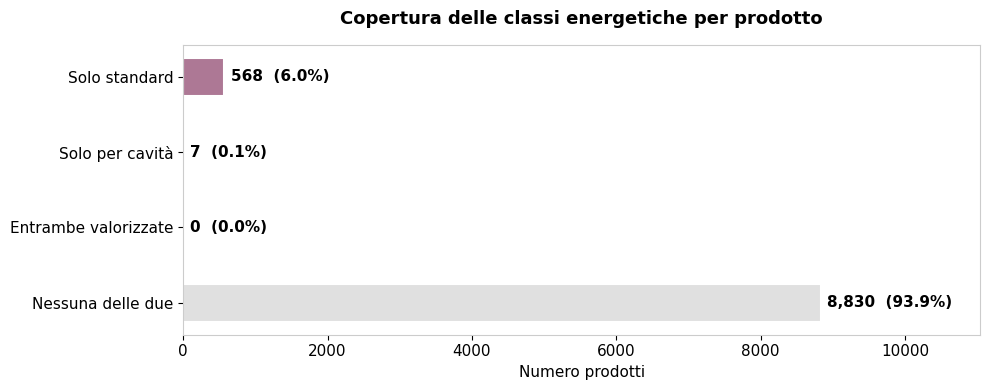

───────────────────────────────────────────────────────
  Solo classe standard:         568 prodotti
  Solo classe per cavità:         7 prodotti
  Entrambe valorizzate:           0 prodotti  ✓
  Nessuna delle due:          8,830 prodotti
───────────────────────────────────────────────────────
  Totale:                     9,405 prodotti

Nessun prodotto presenta entrambe le classi valorizzate.


In [60]:
# Verifica: esistono prodotti con entrambe le classi energetiche?

entrambe = df[df['Classe efficienza energetica'].notna() & df['Classe efficienza energetica cavita'].notna()].copy()
solo_standard = df[df['Classe efficienza energetica'].notna() & df['Classe efficienza energetica cavita'].isna()].copy()
solo_cavita = df[df['Classe efficienza energetica'].isna()  & df['Classe efficienza energetica cavita'].notna()].copy()
nessuna = df[df['Classe efficienza energetica'].isna()  & df['Classe efficienza energetica cavita'].isna()].copy()

categorie = ['Nessuna delle due', 'Entrambe valorizzate', 'Solo per cavità', 'Solo standard']
conteggi = [len(nessuna), len(entrambe), len(solo_cavita), len(solo_standard)]
colori = ['#e0e0e0', '#f4a7b9', '#7faacc', '#ad7895']

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(categorie, conteggi, color=colori, edgecolor='white', linewidth=1.5, height=0.5)
for bar, val in zip(bars, conteggi):
    ax.text(bar.get_width() + max(conteggi) * 0.01, bar.get_y() + bar.get_height() / 2, f'{val:,}  ({val / len(df) * 100:.1f}%)', va='center', ha='left', fontsize=11, fontweight='bold', color='black')
ax.set_xlim(0, max(conteggi) * 1.25)
ax.set_xlabel('Numero prodotti', fontsize=11, color='black')
ax.set_title('Copertura delle classi energetiche per prodotto', fontsize=13, fontweight='bold', pad=15)
ax.tick_params(colors='black', labelsize=11)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
for spine in ax.spines.values():
    spine.set_edgecolor('#cccccc')

# Annotazione anomalia su "Entrambe"
if len(entrambe) > 0:
    idx = categorie.index('Entrambe valorizzate')
    ax.annotate('Attenzione: da verificare', xy=(conteggi[idx], idx), xytext=(conteggi[idx] + max(conteggi) * 0.15, idx - 0.3), fontsize=10, color='#cc0000', fontweight='bold')

plt.tight_layout()
plt.show()

# Riepilogo testuale 
print(f"{'─'*55}")
print(f"  Solo classe standard:      {len(solo_standard):>6,} prodotti")
print(f"  Solo classe per cavità:    {len(solo_cavita):>6,} prodotti")
print(f"  Entrambe valorizzate:      {len(entrambe):>6,} prodotti  {'⚠ da verificare' if len(entrambe) > 0 else '✓'}")
print(f"  Nessuna delle due:         {len(nessuna):>6,} prodotti")
print(f"{'─'*55}")
print(f"  Totale:                    {len(df):>6,} prodotti")

# Dettaglio anomalie se presenti
if len(entrambe) > 0:
    print(f"\nProdotti con entrambe le classi valorizzate:\n")
    display(
        entrambe[['ID Prodotto', 'Numero Articolo Catalogo', 'Classe efficienza energetica', 'Classe efficienza energetica cavita']].style.set_properties(**{'color': 'black', 'background-color': 'white'})
        .apply(lambda col: ['background-color: #ffe0b2; color: black'] * len(col), subset=['Classe efficienza energetica', 'Classe efficienza energetica cavita']).hide(axis='index'))
else:
    print(f"\nNessun prodotto presenta entrambe le classi valorizzate.")

-> **Informazioni dimensionali**

La Misure rappresentano uno dei campi più ricchi e complessi dell'intero catalogo. 

In [61]:
# Analisi preliminare della colonna Misure
colonna_misure = 'Misure'
n_tot_misure = len(df)
righe_non_nulle_misure = df[colonna_misure].notna().sum()

print(f"Righe totali nel dataset: {n_tot_misure:,}.")
print(f"Righe valorizzate in '{colonna_misure}': {righe_non_nulle_misure:,}  ({righe_non_nulle_misure/n_tot_misure*100:.2f}%).")
print(f"Righe mancanti: {n_tot_misure - righe_non_nulle_misure:,}  ({(n_tot_misure - righe_non_nulle_misure)/n_tot_misure*100:.2f}%).")

# Esempi di valori grezzi
print("\nEsempi di valori grezzi:\n")
esempi = df[colonna_misure].dropna().head(5)
for idx, val in esempi.items():
    print(f"  [{idx}]  {val}")
    print()

Righe totali nel dataset: 9,405.
Righe valorizzate in 'Misure': 7,923  (84.24%).
Righe mancanti: 1,482  (15.76%).

Esempi di valori grezzi:

  [3]  Larghezza: 60.0 cm

  [4]  Larghezza: 120 cm | Profondità: 90 cm | Altezza: 4 cm

  [5]  Larghezza: 120 cm | Profondità: 90 cm | Altezza: 4 cm

  [6]  Larghezza: 120 cm | Profondità: 90 cm | Altezza: 4 cm

  [8]  Lunghezza: 240 cm | Larghezza: 170 cm



In [62]:
# Analisi della struttura: separatori e numero campi per riga
# Nota: alcune righe hanno virgolette esterne da strippare

# Esempio: prima riga valida
prima_riga_valida = df[colonna_misure].first_valid_index()
riga_esempio = str(df.loc[prima_riga_valida, colonna_misure]).strip('"')
print(f"Indice prima riga valida: {prima_riga_valida}")
print(f"Numero separatori '|':    {riga_esempio.count('|')}")
print("-" * 50)

campi = riga_esempio.split('|')
print(f"Numero campi trovati: {len(campi)}")
print("-" * 50)
for i, campo in enumerate(campi):
    print(f"[{i:02d}] {campo.strip()}")

# Distribuzione numero campi per riga
print("\n")
conteggio_campi = (df[colonna_misure].dropna().astype(str).str.strip('"').apply(lambda x: len(x.split('|'))))
frequenze = (conteggio_campi.value_counts().sort_index().reset_index())
frequenze.columns = ['Numero campi', 'Numero righe']
tot = frequenze['Numero righe'].sum()
frequenze['Percentuale'] = (frequenze['Numero righe'] / tot * 100).round(2)
frequenze = frequenze.sort_values('Numero campi').reset_index(drop=True)
top3_pct = frequenze.nlargest(3, 'Percentuale')['Percentuale'].tolist()

def highlight_top3(v):
    return 'background-color: #ad7895; color: black' if v in top3_pct else 'color: black'

display(frequenze.style.map(highlight_top3, subset=['Percentuale']).set_properties(**{'color': 'black', 'background-color': 'white'}).format({'Numero righe': '{:,.0f}', 'Percentuale': '{:.2f}%'}).hide(axis='index'))

Indice prima riga valida: 3
Numero separatori '|':    0
--------------------------------------------------
Numero campi trovati: 1
--------------------------------------------------
[00] Larghezza: 60.0 cm




Numero campi,Numero righe,Percentuale
1,518,6.54%
2,"1,077",13.59%
3,"2,339",29.52%
4,"1,605",20.26%
5,"1,008",12.72%
6,816,10.30%
7,302,3.81%
8,132,1.67%
9,53,0.67%
10,17,0.21%


In [63]:
# Campi unici con frequenza e top valori
key_counts_misure = Counter()

for val in df[colonna_misure].dropna():
    # Strip virgolette esterne prima di splittare
    val_clean = str(val).strip('"')
    for parte in val_clean.split('|'):
        parte = parte.strip()
        if ':' in parte:
            chiave = parte.split(':')[0].strip()
            key_counts_misure[chiave] += 1

df_campi_misure = pd.DataFrame(key_counts_misure.most_common(), columns=['Campo', 'Frequenza'])
df_campi_misure['% su righe valorizzate'] = (df_campi_misure['Frequenza'] / righe_non_nulle_misure * 100).round(2)
print(f"Campi unici trovati: {len(df_campi_misure)}")

VALORI_NULLI_MISURE = {'(nessun valore)', 'n.a', 'n.a.', 'N/A', ''}

def estrai_valori_misura(nome_campo):
    def _parse(testo):
        if pd.isna(testo):
            return None
        for parte in str(testo).strip('"').split('|'):
            parte = parte.strip()
            if parte.startswith(nome_campo + ':'):
                valore = parte[len(nome_campo) + 1:].strip()
                return None if valore in VALORI_NULLI_MISURE else valore
        return None
    return df[colonna_misure].apply(_parse)

top_valori_list = []
for campo in df_campi_misure['Campo']:
    valori = estrai_valori_misura(campo)
    top3 = valori.dropna().value_counts().head(3).index.tolist()
    top_valori_list.append(top3)

df_campi_misure['Top valori'] = top_valori_list
display(df_campi_misure.style.background_gradient(subset=['Frequenza'], cmap='RdPu').format({'Frequenza': '{:,.0f}', '% su righe valorizzate': '{:.2f}%'}).hide(axis='index'))

Campi unici trovati: 246


Campo,Frequenza,% su righe valorizzate,Top valori
Larghezza,"4,757",60.04%,"['60 cm', '80 cm', '39.7 cm']"
Altezza,"4,349",54.89%,"['80.0 cm', '79.7 cm', '10 cm']"
Lunghezza,"2,530",31.93%,"['195 cm', '300 cm', '200 cm']"
Profondità,"2,344",29.58%,"['40 cm', '49.0 cm', '30.0 cm']"
Spessore,"1,549",19.55%,"['6 mm', '1.8 cm', '1.9 cm']"
Quantità/confezione,"1,283",16.19%,"['2 pz.', '1 pz.', '4 pz.']"
Diametro,"1,127",14.22%,"['6 cm', '38 cm', '60 mm']"
Superficie,905,11.42%,"['4.35 m²', '1.17 m²', '1.56 m²']"
Lunghezza filo elettrico,869,10.97%,"['3.5 m', '2.0 m', '1.8 m']"
Potenza,807,10.19%,"['3.7 W', '3.5 W', '1.3 W']"


-> **Validazione incrociata: Flusso Luminoso**

L'estrazione parametrica dal campo `Misure` ha isolato il campo `Flusso luminoso` per 619 record. Poiché nel dataset è già presente la feature `Flusso luminoso nominale (lm)` derivata dalle Informazioni Tecniche (precedentemente validata per l'etichetta energetica), si esegue una validazione incrociata.

In [64]:
# Confronto tra Flusso luminoso (campo in Misure) vs Flusso luminoso nominale (lm) (già estratto dalle Informazioni Tecniche)

# Estrazione del Flusso luminoso dalla colonna Misure
df['_flusso_misure_raw'] = estrai_valori_misura('Flusso luminoso')

def parse_flusso_misure(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)', str(valore))
    return float(match.group(1).replace(',', '.')) if match else None

df['_flusso_misure_num'] = df['_flusso_misure_raw'].apply(parse_flusso_misure)

# Statistiche di copertura
n_misure = df['_flusso_misure_num'].notna().sum()
n_it = df['Flusso luminoso nominale (lm)'].notna().sum()
n_entrambe = (df['_flusso_misure_num'].notna() & df['Flusso luminoso nominale (lm)'].notna()).sum()
n_solo_misure = (df['_flusso_misure_num'].notna() & df['Flusso luminoso nominale (lm)'].isna()).sum()
n_solo_it = (df['_flusso_misure_num'].isna() & df['Flusso luminoso nominale (lm)'].notna()).sum()

print("COPERTURA\n")
print(f"  Flusso luminoso (da Misure):              {n_misure:,}")
print(f"  Flusso luminoso nominale (da Info Tec.):  {n_it:,}")
print(f"  Entrambe valorizzate:                     {n_entrambe:,}  ← base confronto")
print(f"  Solo in Misure:                           {n_solo_misure:,}")
print(f"  Solo in Info Tecniche:                    {n_solo_it:,}\n")

# Confronto record per record dove entrambe sono valorizzate
def classifica_flusso(row):
    val_mis = row['_flusso_misure_num']
    val_it  = row['Flusso luminoso nominale (lm)']
    mis_ok = pd.notna(val_mis)
    it_ok  = pd.notna(val_it)

    if not mis_ok and not it_ok: return 'Entrambe assenti'
    if mis_ok and not it_ok:     return 'Solo in Misure'
    if not mis_ok and it_ok:     return 'Solo in Info Tecniche'
    if abs(val_mis - val_it) < 0.01: return 'Match'
    return f'Incoerenza ({val_mis} vs {val_it})'

df['_esito_flusso'] = df.apply(classifica_flusso, axis=1)

# Tabella esiti 
vc_flusso = (df['_esito_flusso'].value_counts(dropna=False).rename_axis('Esito').reset_index(name='Conteggio'))
vc_flusso['% su totale'] = (vc_flusso['Conteggio'] / len(df) * 100).round(2)

def colore_esito_flusso(esito):
    if esito == 'Match':                  return 'background-color: #e8f4e8; color: black'
    if esito.startswith('Incoerenza'):    return 'background-color: #ffe0b2; color: black'
    if esito in ('Solo in Misure', 'Solo in Info Tecniche'): return 'background-color: #f7e6f0; color: black'
    return 'background-color: white; color: black'

display(vc_flusso.style.apply(lambda col: [colore_esito_flusso(v) for v in col], subset=['Esito']).set_properties(subset=['Conteggio', '% su totale'],**{'color': 'black', 'background-color': '#eae4e4'}).format({'Conteggio': '{:,.0f}', '% su totale': '{:.2f}%'})
    .set_caption('Flusso luminoso — Misure vs Informazioni Tecniche').set_table_styles([{'selector': 'caption', 'props': [('caption-side', 'top'), ('text-align', 'left'),('font-size', '14px'), ('font-weight', 'bold'),('background-color', '#ad7895'), ('color', 'white'), ('padding', '8px')]}]).hide(axis='index'))

# Zoom incoerenze
incoerenze_flusso = df[df['_esito_flusso'].str.startswith('Incoerenza', na=False)]
print(f"\nIncoerenze: {len(incoerenze_flusso)} record")
if len(incoerenze_flusso) > 0:
    display(
        incoerenze_flusso[['ID Prodotto', '_flusso_misure_raw', '_flusso_misure_num', 'Flusso luminoso nominale (lm)', '_esito_flusso']]
        .style.set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb').hide(axis='index'))

# Pulizia colonne temporanee
df.drop(columns=['_flusso_misure_raw', '_flusso_misure_num', '_esito_flusso'], inplace=True)

COPERTURA

  Flusso luminoso (da Misure):              619
  Flusso luminoso nominale (da Info Tec.):  495
  Entrambe valorizzate:                     381  ← base confronto
  Solo in Misure:                           238
  Solo in Info Tecniche:                    114



Esito,Conteggio,% su totale
Entrambe assenti,"8,672",92.21%
Match,312,3.32%
Solo in Misure,238,2.53%
Solo in Info Tecniche,114,1.21%
Incoerenza (270.0 vs 313.0),28,0.30%
Incoerenza (360.0 vs 320.0),16,0.17%
Incoerenza (65.0 vs 74.0),11,0.12%
Incoerenza (220.0 vs 200.0),10,0.11%
Incoerenza (240.0 vs 220.0),2,0.02%
Incoerenza (800.0 vs 900.0),1,0.01%



Incoerenze: 69 record


ID Prodotto,_flusso_misure_raw,_flusso_misure_num,Flusso luminoso nominale (lm),_esito_flusso
3184737,360 lm,360.000000,320.000000,Incoerenza (360.0 vs 320.0)
3196714,220 lm,220.000000,200.000000,Incoerenza (220.0 vs 200.0)
3309455,360 lm,360.000000,320.000000,Incoerenza (360.0 vs 320.0)
3309457,360 lm,360.000000,320.000000,Incoerenza (360.0 vs 320.0)
3309459,360 lm,360.000000,320.000000,Incoerenza (360.0 vs 320.0)
2916308,220 lm,220.000000,200.000000,Incoerenza (220.0 vs 200.0)
3035101,270 lm,270.000000,313.000000,Incoerenza (270.0 vs 313.0)
3083923,65 lm,65.000000,74.000000,Incoerenza (65.0 vs 74.0)
3172634,65 lm,65.000000,74.000000,Incoerenza (65.0 vs 74.0)
3224101,65 lm,65.000000,74.000000,Incoerenza (65.0 vs 74.0)


In [65]:
# Analisi Incoerenze Flusso Luminoso per Numero Articolo Catalogo

# Ricalcoliamo temporaneamente le colonne di confronto
df['_flusso_misure_num'] = estrai_valori_misura('Flusso luminoso').apply(lambda v: float(re.search(r'(\d+(?:[.,]\d+)?)', str(v)).group(1).replace(',', '.')) if pd.notna(v) and re.search(r'(\d+(?:[.,]\d+)?)', str(v)) else None)

def classifica_flusso(row):
    val_mis = row['_flusso_misure_num']
    val_it  = row['Flusso luminoso nominale (lm)']
    mis_ok = pd.notna(val_mis)
    it_ok  = pd.notna(val_it)
    if not mis_ok and not it_ok:
        return 'Entrambe assenti'
    if mis_ok and not it_ok:
        return 'Solo in Misure'
    if not mis_ok and it_ok:
        return 'Solo in Info Tecniche'
    if abs(val_mis - val_it) < 0.01:
        return 'Match'
    return 'Incoerenza'

df['_esito_flusso'] = df.apply(classifica_flusso, axis=1)

# Identificazione dei Numero Articolo Catalogo coinvolti
id_incoerenti = df[df['_esito_flusso'] == 'Incoerenza']['ID Prodotto'].tolist()
nac_incoerenti = (df[df['_esito_flusso'] == 'Incoerenza']['Numero Articolo Catalogo'].unique())
print(f"Prodotti con incoerenza: {len(id_incoerenti):,}.")
print(f"NAC coinvolti: {len(nac_incoerenti):,}.\n")

# Merge con dati anagrafici originali (Nome e Descrizione Prodotto) che precedentemente erano stati eliminati
df_meta = pd.read_csv(file_prodotti, usecols=['ID Prodotto', 'Nome Prodotto', 'Descrizione Prodotto'])
df_meta['ID Prodotto'] = df_meta['ID Prodotto'].astype(str)
df_enriched = df.merge(df_meta, on='ID Prodotto', how='left')

# Analisi per Famiglia Numero Articolo Catalogo
risultati = []

for nac in nac_incoerenti:
    # Usiamo df_enriched per avere Nome e Descrizione
    famiglia = df_enriched[df_enriched['Numero Articolo Catalogo'] == nac][['ID Prodotto','Numero Articolo Catalogo','Nome Prodotto','Descrizione Prodotto','_flusso_misure_num','Flusso luminoso nominale (lm)','_esito_flusso']].copy()

    # Valori distinti
    val_misure_arr = sorted(famiglia['_flusso_misure_num'].dropna().unique())
    val_it_arr = sorted(famiglia['Flusso luminoso nominale (lm)'].dropna().unique())

    # Coerenza interna
    misure_coerente = len(val_misure_arr) <= 1
    it_coerente     = len(val_it_arr) <= 1

    # Funzione di formattazione leggibile
    def formatta_valori(arr):
        if len(arr) == 0:
            return None
        valori = []
        for x in arr:
            x = float(x)
            if x.is_integer():
                valori.append(str(int(x)))
            else:
                valori.append(str(x))
        return ', '.join(valori)
    
    # Calcolo delta tra le due fonti
    def calcola_delta(arr_mis, arr_it):
        if len(arr_mis) == 0 or len(arr_it) == 0:
            return None
        # Se entrambe coerenti internamente, delta è chiaro
        if len(arr_mis) == 1 and len(arr_it) == 1:
            return round(arr_mis[0] - arr_it[0], 2)
        # Se una delle due ha valori multipli, mostra il range dei delta
        deltas = [round(float(m) - float(i), 2) for m in arr_mis for i in arr_it]
        if len(set(deltas)) == 1:
            return deltas[0]
        return f"{min(deltas)} / {max(deltas)}"  # range se multipli

    risultati.append({
        'NAC': nac,
        'Nome Prodotto': famiglia['Nome Prodotto'].iloc[0] if 'Nome Prodotto' in famiglia.columns else None,
        'Descrizione Prodotto': famiglia['Descrizione Prodotto'].iloc[0] if 'Descrizione Prodotto' in famiglia.columns else None,
        'N. prodotti famiglia': len(famiglia),
        'N. incoerenti': (famiglia['_esito_flusso'] == 'Incoerenza').sum(),
        'Valori in Misure': formatta_valori(val_misure_arr),
        'Valori in Info Tecniche': formatta_valori(val_it_arr),
        'Delta (Misure − Info Tec.)': calcola_delta(val_misure_arr, val_it_arr),  # ← nuovo
        'Misure interna coerente': '✓' if misure_coerente else '⚠',
        'Info Tec. interna coerente': '✓' if it_coerente else '⚠'})

df_nac = pd.DataFrame(risultati).sort_values('N. incoerenti', ascending=False)

# Output
print("ANALISI PER NUMERO ARTICOLO CATALOGO")

display(df_nac.style.set_properties(**{'color': 'black', 'background-color': 'white'})
    .apply(lambda col: ['background-color: #e8f4e8; color: black' if v == '✓' else 'background-color: #ffe0b2; color: black' if v == '⚠' else ''
            for v in col],subset=['Misure interna coerente', 'Info Tec. interna coerente'])
    .apply(lambda col: ['background-color: #ffcccc; color: black' if isinstance(v, (int, float)) and abs(v) > 20 else ''
            for v in col], subset=['Delta (Misure − Info Tec.)'])
    .format({'N. prodotti famiglia'      : '{:,.0f}', 'N. incoerenti'             : '{:,.0f}', 'Delta (Misure − Info Tec.)': lambda x: f"{x:+.1f}" if isinstance(x, (int, float)) else str(x) if x else '—',}).hide(axis='index'))

# Si prende ora una decisione
# Per ogni coppia di valori in conflitto, contiamo quante famiglie sono internamente coerenti per Misure vs Info Tecniche
n_misure_coerenti = (df_nac['Misure interna coerente'] == '✓').sum()
n_it_coerenti = (df_nac['Info Tec. interna coerente'] == '✓').sum()

print(f"N.A.C. dove 'Misure' è internamente coerente:          {n_misure_coerenti}/{len(df_nac)}")
print(f"N.A.C. dove 'Info Tecniche' è internamente coerente:   {n_it_coerenti}/{len(df_nac)}")
print()

# Mostriamo i casi dove le due fonti discordano internamente
doppia_anomalia = df_nac[(df_nac['Misure interna coerente'] == '⚠') | (df_nac['Info Tec. interna coerente'] == '⚠')]
if len(doppia_anomalia) > 0:
    print(f"⚠ NAC con incoerenza anche interna ({len(doppia_anomalia)}):\n")
    display(doppia_anomalia.style.set_properties(**{'color': 'black', 'background-color': 'white'})
        .apply(lambda col: ['background-color: #e8f4e8; color: black' if v == '✓' else 'background-color: #ffe0b2; color: black' if v == '⚠' else '' for v in col],
            subset=['Misure interna coerente', 'Info Tec. interna coerente']).hide(axis='index'))
else:
    print("Tutte le famiglie sono internamente coerenti in almeno una delle due fonti.")

Prodotti con incoerenza: 69.
NAC coinvolti: 9.

ANALISI PER NUMERO ARTICOLO CATALOGO


NAC,Nome Prodotto,Descrizione Prodotto,N. prodotti famiglia,N. incoerenti,Valori in Misure,Valori in Info Tecniche,Delta (Misure − Info Tec.),Misure interna coerente,Info Tec. interna coerente
90519917,ROLFSTORP ONLINE,"illuminazione a LED, intensità luminosa regolabile/bianco",28,28,270,313,-43.0,✓,✓
20543157,KAPPLAKE ON LINE,"faretto a LED, bianco",11,11,65,74,-9.0,✓,✓
20529217,SILVERGLANS,"barra luminosa a LED per bagno, 60 cm, intensità luminosa regolabile antracite",9,9,360,320,+40.0,✓,✓
10529227,SILVERGLANS,"barra luminosa a LED per bagno, 60 cm, intensità luminosa regolabile bianco",7,7,360,320,+40.0,✓,✓
70528668,SILVERGLANS,"barra luminosa a LED per bagno, 40 cm, intensità luminosa regolabile bianco",6,6,220,200,+20.0,✓,✓
30528670,SILVERGLANS online,"barra luminosa a LED per bagno, 40 cm, intensità luminosa regolabile antracite",4,4,220,200,+20.0,✓,✓
90528498,MITTLED,"barra a LED sottopensile, 30 cm, intensità luminosa regolabile bianco",2,2,240,220,+20.0,✓,✓
00527238,BÄVE,"binario soffitto 3 faretti LED, bianco",1,1,800,900,-100.0,✓,✓
20509993,SOLHETTA online,"lampadina a LED E27 1521 lumen, intensità luminosa regolabile/globo bianco opalino",1,1,1520,1521,-1.0,✓,✓


N.A.C. dove 'Misure' è internamente coerente:          9/9
N.A.C. dove 'Info Tecniche' è internamente coerente:   9/9

Tutte le famiglie sono internamente coerenti in almeno una delle due fonti.


In [66]:
# Integrazione: aggiungiamo a 'Flusso luminoso nominale (lm)' (fonte primaria) i valori presenti solo in Misure (238 record)

col_target = 'Flusso luminoso nominale (lm)'  
mask_solo_misure = (df[col_target].isna() & df['_flusso_misure_num'].notna())
n_prima = df[col_target].notna().sum()
n_da_aggiungere = mask_solo_misure.sum()

# Integrazione
df.loc[mask_solo_misure, col_target] = df.loc[mask_solo_misure, '_flusso_misure_num']
n_dopo = df[col_target].notna().sum()

# Riepilogo 
display(HTML("<h3><b>Integrazione Flusso luminoso: Misure → Info Tecniche</b></h3>"))
display(HTML(f"<ul> <li>Valori in <code>{col_target}</code> prima dell'integrazione: <b>{n_prima:,}</b>.</li>"
    f"<li>Record con solo Misure valorizzata (candidati): <b>{n_da_aggiungere:,}</b>.</li>"
    f"<li>Valori dopo l'integrazione: <b>{n_dopo:,}</b> (+{n_dopo - n_prima:,}).</li> </ul>"))

# Esempi prima/dopo 
display(HTML("<b>Campione di record integrati (valore proveniente da Misure):</b>"))
idx_integrati = df[mask_solo_misure].index[:8]

df_esempi = df.loc[idx_integrati, ['ID Prodotto','Numero Articolo Catalogo','_flusso_misure_num',col_target,]].copy()
df_esempi.columns = ['ID Prodotto','NAC','Valore grezzo (Misure)',f'{col_target} — dopo integrazione',]
df_esempi.index = range(1, len(df_esempi) + 1)
display(df_esempi)

# Pulizia colonne temporanee
df.drop(columns=['_flusso_misure_num', '_esito_flusso'], inplace=True, errors='ignore')

,ID Prodotto,NAC,Valore grezzo (Misure),Flusso luminoso nominale (lm) — dopo integrazione
1,3413216,10531131,780.0,780.0
2,3273255,10531131,780.0,780.0
3,3273256,10531131,780.0,780.0
4,3273257,10531131,780.0,780.0
5,3273258,10531131,780.0,780.0
6,3273259,10531131,780.0,780.0
7,3314107,10531131,780.0,780.0
8,3358659,30625223,800.0,800.0


-> **Analisi delle unità di misura**

La scomposizione del campo Misure ha generato 246 attributi descrittivi. Affinché questi parametri possano essere trasformati in vere feature numeriche (vettori a virgola mobile) idonee all'analisi quantitativa, è imperativo che all'interno dello stesso attributo vi sia assoluta omogeneità metrica. 

In [67]:
# Verifica dell'unità di misura per tutti i 246 campi trovati

# Estrazione dell'unità di misura da un valore grezzo (es. '60 cm' → 'cm')
def estrai_unita_da_valore(valore):
    if pd.isna(valore):
        return None
    match = re.search(r'[\d.,]+\s*([a-zA-Z°²³"/\'%]+[\w²³]*\.?)\s*$', str(valore).strip())
    return match.group(1).strip() if match else None

# Per ogni campo estraiamo tutti i valori e analizziamo le unità
risultati_unita = []

for campo in df_campi_misure['Campo']:
    valori = estrai_valori_misura(campo).dropna()
    if len(valori) == 0:
        continue
    unita = valori.apply(estrai_unita_da_valore).dropna()
    unita_distinte = unita.value_counts()
    n_unita = unita_distinte.nunique()
    risultati_unita.append({'Campo': campo, 'Frequenza': df_campi_misure.loc[df_campi_misure['Campo'] == campo, 'Frequenza'].values[0],'N. unità distinte': n_unita, 'Unità trovate': dict(unita_distinte.head(5)), 'Anomalia': n_unita > 1})

df_unita = pd.DataFrame(risultati_unita)

# Riepilogo
n_anomali = df_unita['Anomalia'].sum()
print(f"Campi analizzati: {len(df_unita)}.")
print(f"Campi con unità coerente: {(~df_unita['Anomalia']).sum()}.")
print(f"Campi con unità miste: {n_anomali}  {'⚠' if n_anomali > 0 else '✓'}.\n \n")

# Dettaglio campi con unità di misura miste
anomali = df_unita[df_unita['Anomalia']].sort_values('Frequenza', ascending=False)

print(f"OSSERVAZIONE DEI CAMPI CON UNITÀ DI MISURA MISTE ({len(anomali)})\n")

for _, row in anomali.iterrows():
    campo = row['Campo']
    valori = estrai_valori_misura(campo).dropna()
    unita_vc = valori.apply(estrai_unita_da_valore).value_counts(dropna=True)
    print(f"{'─'*60}")
    print(f"  {campo}  —  {int(row['Frequenza'])} righe")
    print(f"{'─'*60}")
    display(unita_vc.rename_axis('Unità').reset_index(name='Occorrenze').assign(**{'Esempio valore': [valori[valori.apply(estrai_unita_da_valore) == u].iloc[0] if len(valori[valori.apply(estrai_unita_da_valore) == u]) > 0 else '' for u in unita_vc.index]})
        .style.set_properties(**{'color': 'black', 'background-color': 'white'}).format({'Occorrenze': '{:,.0f}'}).hide(axis='index'))
    print()

Campi analizzati: 246.
Campi con unità coerente: 227.
Campi con unità miste: 19  ⚠.
 

OSSERVAZIONE DEI CAMPI CON UNITÀ DI MISURA MISTE (19)

────────────────────────────────────────────────────────────
  Larghezza  —  4757 righe
────────────────────────────────────────────────────────────


Unità,Occorrenze,Esempio valore
cm,"4,437",60.0 cm
mm,315,306 mm
m,5,15 m



────────────────────────────────────────────────────────────
  Altezza  —  4349 righe
────────────────────────────────────────────────────────────


Unità,Occorrenze,Esempio valore
cm,"4,094",4 cm
mm,255,220 mm



────────────────────────────────────────────────────────────
  Lunghezza  —  2530 righe
────────────────────────────────────────────────────────────


...

Unità,Occorrenze,Esempio valore
mm,12,3 mm
cm,1,0.6 cm



────────────────────────────────────────────────────────────
  Spessore anta  —  13 righe
────────────────────────────────────────────────────────────


Unità,Occorrenze,Esempio valore
mm,7,16 mm
cm,6,4 cm



────────────────────────────────────────────────────────────
  Capacità della batteria  —  8 righe
────────────────────────────────────────────────────────────


Unità,Occorrenze,Esempio valore
V,7,10.8 V
mAh,1,1500 mAh


In [68]:
# Normalizzazione dei campi dimensionali in cm

def normalizza_in_cm(valore):
    if pd.isna(valore): return None
    testo = str(valore).strip()
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*(cm|mm|m)\b', testo, re.IGNORECASE)
    if not match: return None
    numero = float(match.group(1).replace(',', '.'))
    unita  = match.group(2).lower()
    if unita == 'mm': return round(numero / 10, 4)
    if unita == 'm':  return round(numero * 100, 4)
    return round(numero, 4)

campi_dimensionali_cm = ['Larghezza', 'Altezza', 'Lunghezza', 'Profondità', 'Spessore', 'Diametro', 'Altezza massima', 'Altezza minima', 'Lunghezza minima', 'Lunghezza massima', 'Spessore impiallacciatura', 'Spessore anta']

display(HTML("<h3><b>Normalizzazione campi dimensionali → cm</b></h3>"))

for campo in campi_dimensionali_cm:
    serie_raw  = estrai_valori_misura(campo)
    serie_norm = serie_raw.apply(normalizza_in_cm)
    col_name   = f"{campo} (cm)"
    df[col_name] = serie_norm

    n_tot    = serie_raw.notna().sum()
    n_norm   = serie_norm.notna().sum()
    n_persi  = n_tot - n_norm

    # Conta per ogni unità
    conteggi_unita = {}
    for unita_regex, label in [(r'\d+\s*cm\b', 'cm'), (r'\d+\s*mm\b', 'mm'), (r'\d+\s*m\b', 'm')]:
        n = serie_raw.dropna().str.contains(unita_regex, case=False, na=False).sum()
        if n > 0:
            conteggi_unita[label] = n

    # Testo riepilogo trasformazioni
    trasf = []
    for label, n in conteggi_unita.items():
        if label != 'cm':
            trasf.append(f"{n:,} {label}→cm")
    testo_trasf = ' | '.join(trasf) if trasf else 'nessuna conversione necessaria'

    display(HTML(f"<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
        f"<b>{campo}</b> &nbsp;—&nbsp; {n_tot:,} valori grezzi"
        + (f" &nbsp;|&nbsp; <span style='color:#e35205'>{n_persi} non parsati</span>" if n_persi > 0 else "")
        + f"<br><style='color:#666;'>Trasformazioni: {testo_trasf}</small>"))

    # Esempi per ogni unità presente
    esempi_rows = []
    for unita_regex, label in [(r'\d+\s*cm\b', 'cm'), (r'\d+\s*mm\b', 'mm'), (r'\d+\s*m\b', 'm')]:
        mask = serie_raw.dropna().str.contains(unita_regex, case=False, na=False)
        campione = serie_raw.dropna()[mask].head(1)
        if not campione.empty:
            idx = campione.index[0]
            val_raw = campione.iloc[0]
            val_norm = serie_norm.loc[idx]
            esempi_rows.append({'Unità originale': label,'Esempio grezzo' : val_raw,'→ cm'           : f"{val_norm} cm" if val_norm is not None else '—',})

    if esempi_rows:
        display(pd.DataFrame(esempi_rows).reset_index(drop=True))

,Unità originale,Esempio grezzo,→ cm
0,cm,60.0 cm,60.0 cm
1,mm,306 mm,30.6 cm
2,m,15 m,1500.0 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,4 cm,4.0 cm
1,mm,220 mm,22.0 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,240 cm,240.0 cm
1,mm,97 mm,9.7 cm
2,m,3 m,300.0 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,90 cm,90.0 cm
1,mm,133 mm,13.3 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,4.5 cm,4.5 cm
1,mm,6 mm,0.6 cm


...

,Unità originale,Esempio grezzo,→ cm
0,cm,73.0 cm,73.0 cm
1,mm,19 mm,1.9 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,139 cm,139.0 cm
1,mm,860 mm,86.0 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,203 cm,203.0 cm
1,m,3 m,300.0 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,0.6 cm,0.6 cm
1,mm,3 mm,0.3 cm


,Unità originale,Esempio grezzo,→ cm
0,cm,4 cm,4.0 cm
1,mm,16 mm,1.6 cm


In [69]:
# Normalizzazione grandezze non dimensionali: Superficie, Filo, Capacità, Etichette
display(HTML("<h3><b>Normalizzazione grandezze non dimensionali</b></h3>"))

# Superficie → m² 
def normalizza_superficie(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*(m2|m²|cm2|cm²)', str(valore))
    if not match: return None
    numero = float(match.group(1).replace(',', '.'))
    return round(numero / 10000 if 'cm' in match.group(2) else numero, 6)

serie_raw_sup  = estrai_valori_misura('Superficie')
serie_norm_sup = serie_raw_sup.apply(normalizza_superficie)
df['Superficie (m²)'] = serie_norm_sup
n_m2  = serie_raw_sup.dropna().str.contains(r'\d+\s*(m2|m²)', na=False).sum()
n_cm2 = serie_raw_sup.dropna().str.contains(r'\d+\s*(cm2|cm²)', na=False).sum()

display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
    f"<b>Superficie → m²</b> &nbsp;—&nbsp; {serie_raw_sup.notna().sum():,} valori grezzi"
    f"<br><style='color:#666;'>Trasformazioni: {n_m2:,} già in m² | {n_cm2} cm²→m²</small>"))

# Esempi per ogni unità
for unita_regex, label in [(r'\d+\s*(m2|m²)', 'm²'), (r'\d+\s*(cm2|cm²)', 'cm²')]:
    mask = serie_raw_sup.dropna().str.contains(unita_regex, na=False)
    camp = serie_raw_sup.dropna()[mask].head(1)
    if not camp.empty:
        idx = camp.index[0]
        display(pd.DataFrame([{'Unità originale': label,'Esempio grezzo' : camp.iloc[0],'→ m²'           : serie_norm_sup.loc[idx],}]).reset_index(drop=True))

# Lunghezza filo elettrico → m
def normalizza_filo(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*(m|cm)\b', str(valore), re.IGNORECASE)
    if not match: return None
    numero = float(match.group(1).replace(',', '.'))
    return round(numero / 100 if match.group(2).lower() == 'cm' else numero, 4)

serie_raw_filo  = estrai_valori_misura('Lunghezza filo elettrico')
serie_norm_filo = serie_raw_filo.apply(normalizza_filo)
df['Lunghezza filo elettrico (m)'] = serie_norm_filo
n_m_filo  = serie_raw_filo.dropna().str.contains(r'\d+\s*m\b', case=False, na=False).sum()
n_cm_filo = serie_raw_filo.dropna().str.contains(r'\d+\s*cm\b', case=False, na=False).sum()

display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
    f"<b>Lunghezza filo elettrico → m</b> &nbsp;—&nbsp; {serie_raw_filo.notna().sum():,} valori grezzi"
    f"<br><style='color:#666;'>Trasformazioni: {n_m_filo:,} già in m | {n_cm_filo} cm→m</small>"))

for unita_regex, label in [(r'\d+\s*m\b', 'm'), (r'\d+\s*cm\b', 'cm')]:
    mask = serie_raw_filo.dropna().str.contains(unita_regex, case=False, na=False)
    camp = serie_raw_filo.dropna()[mask].head(1)
    if not camp.empty:
        idx = camp.index[0]
        display(pd.DataFrame([{'Unità originale': label,'Esempio grezzo' : camp.iloc[0],'→ m'            : serie_norm_filo.loc[idx],}]).reset_index(drop=True))

# Capacità → litri 
def normalizza_capacita(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*(l|cl|dl|ml)\b', str(valore), re.IGNORECASE)
    if not match: return None
    numero = float(match.group(1).replace(',', '.'))
    unita  = match.group(2).lower()
    if unita == 'cl': return round(numero / 100,  6)
    if unita == 'dl': return round(numero / 10,   6)
    if unita == 'ml': return round(numero / 1000, 6)
    return round(numero, 4)

serie_raw_cap  = estrai_valori_misura('Capacità')
serie_norm_cap = serie_raw_cap.apply(normalizza_capacita)
df['Capacità (l)'] = serie_norm_cap
conteggi_cap = {'l' : serie_raw_cap.dropna().str.contains(r'\d+\s*l\b',  case=False, na=False).sum(),
    'cl': serie_raw_cap.dropna().str.contains(r'\d+\s*cl\b', case=False, na=False).sum(),
    'dl': serie_raw_cap.dropna().str.contains(r'\d+\s*dl\b', case=False, na=False).sum(),
    'ml': serie_raw_cap.dropna().str.contains(r'\d+\s*ml\b', case=False, na=False).sum(),}

trasf_cap = ' | '.join([ f"{n:,} {'già in l' if u == 'l' else u + '→l'}" for u, n in conteggi_cap.items() if n > 0])

display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
    f"<b>Capacità → litri</b> &nbsp;—&nbsp; {serie_raw_cap.notna().sum():,} valori grezzi"
    f"<br><style='color:#666;'>Trasformazioni: {trasf_cap}</small>"))

for unita_regex, label in [(r'\d+\s*l\b','l'),(r'\d+\s*cl\b','cl'),(r'\d+\s*dl\b','dl'),(r'\d+\s*ml\b','ml')]:
    mask = serie_raw_cap.dropna().str.contains(unita_regex, case=False, na=False)
    camp = serie_raw_cap.dropna()[mask].head(1)
    if not camp.empty:
        idx = camp.index[0]
        display(pd.DataFrame([{'Unità originale': label,'Esempio grezzo' : camp.iloc[0],'→ litri'        : serie_norm_cap.loc[idx],}]).reset_index(drop=True))

# Etichette: pezzi → pz.
for campo, col_name in [('Quantità/confezione', 'Quantità/confezione (pz)'), ('Posti a sedere',      'Posti a sedere (pz)')]:
    serie_raw_et  = estrai_valori_misura(campo)
    serie_norm_et = serie_raw_et.str.replace(r'(\d+)\s*pezzi?\.?', r'\1 pz.', regex=True).str.strip()
    df[col_name] = serie_norm_et
    n_pz    = serie_raw_et.dropna().str.contains(r'\d+\s*pz\.?', case=False, na=False).sum()
    n_pezzi = serie_raw_et.dropna().str.contains(r'\d+\s*pezzi?', case=False, na=False).sum()

    display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
        f"<b>{col_name}</b> &nbsp;—&nbsp; {serie_raw_et.notna().sum():,} valori grezzi"
        f"<br><style='color:#666;'>Trasformazioni: {n_pz:,} già in pz. | {n_pezzi} 'pezzi'→'pz.'</small>"))

    for forma, regex in [('pz.', r'\d+\s*pz\.?'), ('pezzi', r'\d+\s*pezzi?')]:
        mask = serie_raw_et.dropna().str.contains(regex, case=False, na=False)
        camp = serie_raw_et.dropna()[mask].head(1)
        if not camp.empty:
            idx = camp.index[0]
            display(pd.DataFrame([{'Forma originale': forma,'Esempio grezzo' : camp.iloc[0],'→ normalizzato' : serie_norm_et.loc[idx],}]).reset_index(drop=True))

,Unità originale,Esempio grezzo,→ m²
0,m²,4.08 m²,4.08


,Unità originale,Esempio grezzo,→ m²
0,cm²,7200 cm²,0.72


,Unità originale,Esempio grezzo,→ m
0,m,2.0 m,2.0


,Unità originale,Esempio grezzo,→ m
0,cm,110.0 cm,1.1


,Unità originale,Esempio grezzo,→ litri
0,l,48 l,48.0


...

,Unità originale,Esempio grezzo,→ litri
0,ml,500 ml,0.5


,Forma originale,Esempio grezzo,→ normalizzato
0,pz.,2 pz.,2 pz.


,Forma originale,Esempio grezzo,→ normalizzato
0,pezzi,2 pezzi,2 pz.


,Forma originale,Esempio grezzo,→ normalizzato
0,pz.,1 pz.,1 pz.


,Forma originale,Esempio grezzo,→ normalizzato
0,pezzi,2 pezzi,2 pz.


In [70]:
# Separazione grandezze eterogenee

display(HTML("<h3><b>Separazione grandezze eterogenee</b></h3>"))

# Peso: separa kg da g/m² 
serie_peso = estrai_valori_misura('Peso')

def estrai_peso_kg(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*kg\b', str(valore), re.IGNORECASE)
    return round(float(match.group(1).replace(',', '.')), 4) if match else None

def estrai_densita_tessile(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*g/m[2²]', str(valore))
    return round(float(match.group(1).replace(',', '.')), 4) if match else None

df['Peso (kg)'] = serie_peso.apply(estrai_peso_kg)
df['Densità tessile (g/m²)'] = serie_peso.apply(estrai_densita_tessile)
n_kg  = df['Peso (kg)'].notna().sum()
n_gm2 = df['Densità tessile (g/m²)'].notna().sum()

display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
    f"<b>Peso</b> &nbsp;—&nbsp; {serie_peso.notna().sum():,} valori grezzi"
    "<br><style='color:#666;'>kg e g/m² misurano grandezze diverse (peso assoluto vs densità per unità di superficie). Tenuti in colonne separate.</small>"))

display(HTML(f"Peso (kg): <b>{n_kg:,}</b> valori &nbsp;|&nbsp; "
    f"Densità tessile (g/m²): <b>{n_gm2:,}</b> valori <i>(prodotti tessili)</i>"))

for label, regex, fn in [('kg', r'\d+\s*kg\b', estrai_peso_kg), ('g/m²', r'\d+\s*g/m[2²]', estrai_densita_tessile)]:
    mask = serie_peso.dropna().str.contains(regex, case=False, na=False)
    camp = serie_peso.dropna()[mask].head(1)
    if not camp.empty:
        idx = camp.index[0]
        display(pd.DataFrame([{'Unità originale': label,'Esempio grezzo' : camp.iloc[0],'→ valore'       : fn(camp.iloc[0]),}]).reset_index(drop=True))

# Capacità batteria: separa V da mAh 
serie_batt = estrai_valori_misura('Capacità della batteria')

def estrai_voltaggio(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*V\b', str(valore))
    return round(float(match.group(1).replace(',', '.')), 4) if match else None

def estrai_mah(valore):
    if pd.isna(valore): return None
    match = re.search(r'(\d+(?:[.,]\d+)?)\s*mAh\b', str(valore), re.IGNORECASE)
    return round(float(match.group(1).replace(',', '.')), 4) if match else None

df['Batteria voltaggio (V)']  = serie_batt.apply(estrai_voltaggio)
df['Batteria capacità (mAh)'] = serie_batt.apply(estrai_mah)
n_v   = df['Batteria voltaggio (V)'].notna().sum()
n_mah = df['Batteria capacità (mAh)'].notna().sum()

display(HTML("<hr style='border-top:1px solid #e0e0e0; margin:10px 0;'>"
    f"<b>Capacità batteria</b> &nbsp;—&nbsp; {serie_batt.notna().sum():,} valori grezzi"
    "<br><style='color:#666;'>Volt e mAh misurano grandezze fisiche diverse (tensione vs energia), non convertibili tra loro. Tenuti in colonne separate.</small>"))

display(HTML(f"Batteria voltaggio (V): <b>{n_v:,}</b> valori &nbsp;|&nbsp; "
    f"Batteria capacità (mAh): <b>{n_mah:,}</b> valori <i>(totale: {n_v + n_mah} su {len(df):,} — trascurabile, separato per correttezza)</i>"))

for label, regex, fn in [('V', r'\d+\s*V\b', estrai_voltaggio), ('mAh', r'\d+\s*mAh\b', estrai_mah)]:
    mask = serie_batt.dropna().str.contains(regex, case=False, na=False)
    camp = serie_batt.dropna()[mask].head(1)
    if not camp.empty:
        idx = camp.index[0]
        display(pd.DataFrame([{'Unità originale': label,'Esempio grezzo' : camp.iloc[0],'→ valore'       : fn(camp.iloc[0]),}]).reset_index(drop=True))

,Unità originale,Esempio grezzo,→ valore
0,kg,15.00 kg,15.0


,Unità originale,Esempio grezzo,→ valore
0,g/m²,275 g/m²,275.0


,Unità originale,Esempio grezzo,→ valore
0,V,10.8 V,10.8


,Unità originale,Esempio grezzo,→ valore
0,mAh,1500 mAh,1500.0


In [71]:
# Costruzione della colonna 'Misure Standardizzata' che sostituirà l'originale

# Mappa campo → (colonna normalizzata, unità da mostrare)
MAPPA_NORMALIZZAZIONE = {
    'Larghezza'               : ('Larghezza (cm)',                'cm'),
    'Altezza'                 : ('Altezza (cm)',                  'cm'),
    'Lunghezza'               : ('Lunghezza (cm)',                'cm'),
    'Profondità'              : ('Profondità (cm)',               'cm'),
    'Spessore'                : ('Spessore (cm)',                 'cm'),
    'Diametro'                : ('Diametro (cm)',                 'cm'),
    'Altezza massima'         : ('Altezza massima (cm)',          'cm'),
    'Altezza minima'          : ('Altezza minima (cm)',           'cm'),
    'Lunghezza minima'        : ('Lunghezza minima (cm)',         'cm'),
    'Lunghezza massima'       : ('Lunghezza massima (cm)',        'cm'),
    'Spessore impiallacciatura': ('Spessore impiallacciatura (cm)', 'cm'),
    'Spessore anta'           : ('Spessore anta (cm)',            'cm'),
    'Superficie'              : ('Superficie (m²)',               'm²'),
    'Lunghezza filo elettrico': ('Lunghezza filo elettrico (m)',  'm'),
    'Capacità'                : ('Capacità (l)',                  'l'),
    'Quantità/confezione'     : ('Quantità/confezione (pz)',      'pz'), 
    'Posti a sedere'          : ('Posti a sedere (pz)',           'pz')}

# Formattiamo il numero in modo pulito: interi senza decimali, float con max 2 cifre
def formatta_valore(numero, unita):
    if numero is None:
        return None
    # Se è già una stringa formattata (es. '2 pz.'), usala direttamente
    if isinstance(numero, str):
        return numero
    try:
        n = float(numero)
    except (ValueError, TypeError):
        return str(numero)
    if n == int(n):
        return f"{int(n)} {unita}"
    return f"{round(n, 2)} {unita}"

# Ricostruiamo la stringa Misure sostituendo i valori normalizzati
def ricostruisci_riga(row):
    testo = row['Misure']
    if pd.isna(testo):
        return None
    testo_clean = str(testo).strip('"')
    parti_originali = [p.strip() for p in testo_clean.split('|')]
    parti_nuove = []
    for parte in parti_originali:
        if ':' not in parte:
            parti_nuove.append(parte)
            continue
        campo = parte.split(':')[0].strip()
        if campo in MAPPA_NORMALIZZAZIONE:
            col_norm, unita = MAPPA_NORMALIZZAZIONE[campo]
            valore_norm = row.get(col_norm)
            if pd.notna(valore_norm):
                testo_formattato = formatta_valore(valore_norm, unita)
                parti_nuove.append(f"{campo}: {testo_formattato}")
            else:
                # Valore non parsato: tieni originale
                parti_nuove.append(parte)
        else:
            # Campo non in mappa (inclusi Peso e Batteria): tieni originale
            parti_nuove.append(parte)
    return ' | '.join(parti_nuove)

display(HTML("<h3><b>Costruzione della colonna 'Misure Standardizzata'</b></h3>"))

df['Misure Standardizzata'] = df.apply(ricostruisci_riga, axis=1)
n_originali   = df['Misure'].notna().sum()
n_standardiz  = df['Misure Standardizzata'].notna().sum()

display(HTML(f"<ul> <li>Righe con 'Misure' valorizzata: <b>{n_originali:,}</b>.</li>"
    f"<li>Righe con 'Misure Standardizzata' valorizzata: <b>{n_standardiz:,}</b>.</li></ul>"))

# Verifica qualitativa mirata che cerca conversioni effettive
display(HTML("<b>Verifica qualitativa — esempi con conversione effettiva:</b>"))

esempi = []

# Casi mm → cm effettivi: campo in mappa E valore in mm
for campo in MAPPA_NORMALIZZAZIONE:
    col_norm, unita = MAPPA_NORMALIZZAZIONE[campo]
    if unita != 'cm':
        continue
    # Cerca righe dove il campo originale aveva mm
    mask = df['Misure'].str.contains(rf'{re.escape(campo)}\s*:\s*\d+\s*mm', case=False, na=False)
    candidati = df[mask & df['Misure Standardizzata'].notna()].index
    if len(candidati) > 0:
        idx = candidati[0]
        esempi.append({'Caso'                    : f'{campo}: mm→cm', 'ID Prodotto'             : df.loc[idx, 'ID Prodotto'], 'Misure originale'        : df.loc[idx, 'Misure'], 'Misure Standardizzata'   : df.loc[idx, 'Misure Standardizzata'],})
        break  

# Casi m → cm effettivi: campo in mappa E valore in m (non mm)
for campo in ['Larghezza', 'Lunghezza', 'Altezza', 'Profondità']:
    mask = df['Misure'].str.contains(rf'{re.escape(campo)}\s*:\s*\d+(?:[.,]\d+)?\s*m\b', case=False, na=False)
    candidati = df[mask & df['Misure Standardizzata'].notna()].index
    if len(candidati) > 0:
        idx = candidati[0]
        esempi.append({'Caso'                    : f'{campo}: m→cm', 'ID Prodotto'             : df.loc[idx, 'ID Prodotto'], 'Misure originale'        : df.loc[idx, 'Misure'], 'Misure Standardizzata'   : df.loc[idx, 'Misure Standardizzata'],})
        break

# Caso cm → m per filo elettrico
mask_filo = df['Misure'].str.contains(r'Lunghezza filo elettrico\s*:\s*\d+\s*cm', case=False, na=False)
candidati_filo = df[mask_filo & df['Misure Standardizzata'].notna()].index
if len(candidati_filo) > 0:
    idx = candidati_filo[0]
    esempi.append({'Caso'                  : 'Lunghezza filo elettrico: cm→m', 'ID Prodotto'           : df.loc[idx, 'ID Prodotto'], 'Misure originale'      : df.loc[idx, 'Misure'], 'Misure Standardizzata' : df.loc[idx, 'Misure Standardizzata'],})

# Caso cm² → m² per superficie
mask_sup = df['Misure'].str.contains(r'Superficie\s*:\s*\d+\s*cm[2²]', case=False, na=False)
candidati_sup = df[mask_sup & df['Misure Standardizzata'].notna()].index
if len(candidati_sup) > 0:
    idx = candidati_sup[0]
    esempi.append({'Caso'                  : 'Superficie: cm²→m²', 'ID Prodotto'           : df.loc[idx, 'ID Prodotto'], 'Misure originale'      : df.loc[idx, 'Misure'], 'Misure Standardizzata' : df.loc[idx, 'Misure Standardizzata'],})

if esempi:
    df_es = pd.DataFrame(esempi)
    display(df_es.style.set_properties(**{'color': 'black','background-color': 'white','white-space': 'pre-wrap'}).hide(axis='index'))
else:
    display(HTML("<i>Nessuna conversione effettiva trovata nel dataset.</i>"))

# Rimozione colonne intermedie
display(HTML("Le 21 colonne numeriche intermedie possono ora essere rimosse."))
colonne_intermedie = ['Larghezza (cm)', 'Altezza (cm)', 'Lunghezza (cm)', 'Profondità (cm)', 'Spessore (cm)', 'Diametro (cm)', 'Altezza massima (cm)', 'Altezza minima (cm)', 'Lunghezza minima (cm)', 'Lunghezza massima (cm)',
    'Spessore impiallacciatura (cm)', 'Spessore anta (cm)', 'Superficie (m²)', 'Lunghezza filo elettrico (m)', 'Capacità (l)', 'Quantità/confezione (pz)', 'Posti a sedere (pz)',
    'Peso (kg)', 'Densità tessile (g/m²)', 'Batteria voltaggio (V)', 'Batteria capacità (mAh)']
df.drop(columns=[c for c in colonne_intermedie if c in df.columns], inplace=True)

Caso,ID Prodotto,Misure originale,Misure Standardizzata
Larghezza: mm→cm,3086512,Max.: 18 W | Larghezza: 306 mm | Profondità: 133 mm | Altezza: 220 mm,Max.: 18 W | Larghezza: 30.6 cm | Profondità: 13.3 cm | Altezza: 22 cm
Larghezza: m→cm,3271994,Lunghezza: 2 m | Larghezza: 15 m | Quantità/confezione: 1 pz.,Lunghezza: 200 cm | Larghezza: 1500 cm | Quantità/confezione: 1 pz.
Lunghezza filo elettrico: cm→m,3270870,Larghezza: 54.6 cm | Profondità: 54.9 cm | Altezza: 188.4 cm | Volume frigorifero: 216 l | Volume congelatore: 62 l | Peso: 74.00 kg | Lunghezza filo elettrico: 225 cm,Larghezza: 54.6 cm | Profondità: 54.9 cm | Altezza: 188.4 cm | Volume frigorifero: 216 l | Volume congelatore: 62 l | Peso: 74.00 kg | Lunghezza filo elettrico: 2.25 m
Superficie: cm²→m²,3183083,Larghezza: 180 cm | Profondità: 40 cm | Superficie: 7200 cm²,Larghezza: 180 cm | Profondità: 40 cm | Superficie: 0.72 m²


In [72]:
df.drop(columns=['Misure'], inplace=True)

### **Extra. Designer**

Si discute di tale variabile nella stesura, senza dedicargliene una sezione mirata.

In [ ]:
# Analisi della struttura della colonna Designer

colonna_designer = 'Designer'
n_tot_designer = len(df)
n_valorizzate_des = df[colonna_designer].notna().sum()
n_nulle_des = df[colonna_designer].isna().sum()
n_distinti_des = df[colonna_designer].nunique(dropna=True)

print(f"Righe totali:        {n_tot_designer:,}")
print(f"Righe valorizzate:   {n_valorizzate_des:,}  ({n_valorizzate_des/n_tot_designer*100:.2f}%)")
print(f"Righe mancanti:      {n_nulle_des:,}  ({n_nulle_des/n_tot_designer*100:.2f}%)")
print(f"Valori distinti:     {n_distinti_des:,}")

# Esempi di valori grezzi
print("\nEsempi di valori grezzi:\n")
esempi = df[colonna_designer].dropna().head(5)
for idx, val in esempi.items():
    print(f"  [{idx}]  {val}")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [74]:
# Verifica struttura: ID : Nome

# Verifica quante righe seguono il pattern "ID XXXXX: Nome"
pattern_id = re.compile(r'^ID\s+\d+:\s+.+')
n_con_pattern  = df[colonna_designer].dropna().apply(lambda v: bool(pattern_id.match(str(v)))).sum()
n_senza_pattern = n_valorizzate_des - n_con_pattern

print(f"Righe con pattern 'ID XXXXX: Nome':  {n_con_pattern:,}  ({n_con_pattern/n_valorizzate_des*100:.2f}%)")
print(f"Righe con formato diverso: {n_senza_pattern:,}  ({n_senza_pattern/n_valorizzate_des*100:.2f}%)")

# Mostra eventuali valori fuori pattern
if n_senza_pattern > 0:
    fuori_pattern = df[df[colonna_designer].notna() & ~df[colonna_designer].apply(lambda v: bool(pattern_id.match(str(v))))][colonna_designer]
    print(f"\nValori fuori pattern ({len(fuori_pattern)}):\n")
    display(fuori_pattern.value_counts().rename_axis('Valore').reset_index(name='Conteggio').style
        .set_properties(**{'color': 'black', 'background-color': 'white'}).bar(subset=['Conteggio'], color='#ad7895').format({'Conteggio': '{:,.0f}'}).hide(axis='index'))

Righe con pattern 'ID XXXXX: Nome':  8,437  (100.00%)
Righe con formato diverso: 0  (0.00%)



INDICE DI COERENZA STRUTTURALE
Coerenza ID → Nome:   100.00%
Coerenza Nome → ID:   100.00%


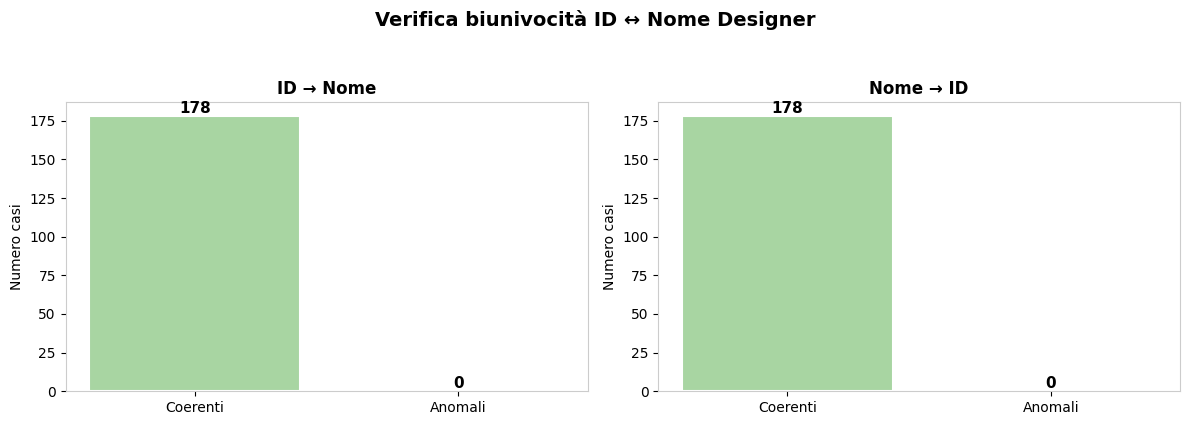

In [75]:
# Verifica Biunivocità: ID ↔ Designer

# Parsing robusto
def estrai_id(valore):
    if pd.isna(valore):
        return None
    match = re.match(r'^ID\s+(\d+):\s+.+$', str(valore).strip())
    return match.group(1) if match else None

def estrai_nome(valore):
    if pd.isna(valore):
        return None
    match = re.match(r'^ID\s+\d+:\s+(.+)$', str(valore).strip())
    return match.group(1).strip() if match else None

df['_designer_id'] = df[colonna_designer].apply(estrai_id)
df['_designer_nome'] = df[colonna_designer].apply(estrai_nome)

# Controllo 1: ID → Nome
id_to_nome = (df[df['_designer_id'].notna()].groupby('_designer_id')['_designer_nome'].nunique().reset_index(name='Nomi distinti'))
n_id_ok = (id_to_nome['Nomi distinti'] == 1).sum()
n_id_anomali = (id_to_nome['Nomi distinti'] > 1).sum()

# Dettaglio eventuali anomalie: ID → Nome
if n_id_anomali > 0:
    id_problematici = id_to_nome[id_to_nome['Nomi distinti'] > 1]['_designer_id']
    display(df[df['_designer_id'].isin(id_problematici)][['_designer_id', '_designer_nome', 'ID Prodotto']]
        .drop_duplicates().sort_values('_designer_id').style.set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb'))

# Controllo 2: Nome → ID
nome_to_id = (df[df['_designer_nome'].notna()].groupby('_designer_nome')['_designer_id'].nunique().reset_index(name='ID distinti'))
n_nome_ok = (nome_to_id['ID distinti'] == 1).sum()
n_nome_anomali = (nome_to_id['ID distinti'] > 1).sum()

# Dettaglio eventuali anomalie: Nome → ID
if n_nome_anomali > 0:
    nomi_problematici = nome_to_id[nome_to_id['ID distinti'] > 1]['_designer_nome']
    display(df[df['_designer_nome'].isin(nomi_problematici)][['_designer_id', '_designer_nome']]
        .drop_duplicates().sort_values('_designer_nome').style.set_properties(**{'color': 'black', 'background-color': 'white'}).highlight_null(color='#f5c6cb'))

# Indice di coerenza strutturale
mappa = (df[['_designer_id', '_designer_nome']].dropna().drop_duplicates())
relazioni_per_id = mappa.groupby('_designer_id')['_designer_nome'].nunique()
relazioni_per_nome = mappa.groupby('_designer_nome')['_designer_id'].nunique()
biunivoco_id = (relazioni_per_id == 1).mean()
biunivoco_nome = (relazioni_per_nome == 1).mean()
print("\nINDICE DI COERENZA STRUTTURALE")
print(f"Coerenza ID → Nome:   {biunivoco_id:.2%}")
print(f"Coerenza Nome → ID:   {biunivoco_nome:.2%}")


# Riepilogo con grafico
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Verifica biunivocità ID ↔ Nome Designer', fontsize=14, fontweight='bold', y=1.05)

metriche = [('ID → Nome', n_id_ok, n_id_anomali), ('Nome → ID', n_nome_ok, n_nome_anomali),]

for ax, (titolo, ok, anomali) in zip(axes, metriche):
    labels = ['Coerenti', 'Anomali']
    valori = [ok, anomali]
    colori = ["#3a7e2a", "#d10534"] if anomali > 0 else ['#a8d5a2']
    bars = ax.bar(labels, valori, color=colori, edgecolor='white', linewidth=1.5)
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2,height,f'{int(height):,}',ha='center',va='bottom',fontsize=11,fontweight='bold')
    ax.set_title(titolo, fontsize=12, fontweight='bold')
    ax.set_ylabel('Numero casi')
    ax.set_facecolor('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#cccccc')

plt.tight_layout()
plt.show()

# Rimozione delle colonne temporanee create per la verifica
df.drop(columns=['_designer_id', '_designer_nome'], inplace=True)

In [ ]:
# Analisi delle occorrenze del nome dell'azienda nel campo Designer

pattern_[redacted] = r'[redacted]'
mask_[redacted] = df[colonna_designer].str.contains(pattern_[redacted], case=False, na=False)
df_[redacted] = df[mask_[redacted]].copy()

# Statistiche base
n_[redacted] = mask_[redacted].sum()
n_tot_valued = df[colonna_designer].notna().sum()
print(f"Righe che contengono il nome dell'azienda: {n_[redacted]:,} ({n_[redacted]/n_tot_valued*100:.2f}%).")

# Valori distinti che contengono il nome dell'azienda
valori_distinti_[redacted] = df_[redacted][colonna_designer].dropna().unique()
print(f"\nValori distinti che contengono il nome dell'azienda: {len(valori_distinti_[redacted]):,}.\n")

# Tabella con i casi e le relative frequenze
[redacted]_tab = (df_[redacted][colonna_designer].value_counts().reset_index())
[redacted]_tab.columns = ['Valore originale', 'Conteggio']
display([redacted]_tab.style.set_properties(**{'color': 'black', 'background-color': 'white'}).format({'Conteggio': '{:,.0f}'}).hide(axis='index'))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# Estrazione del nome, normalizzazione e creazione della nuova colonna

LABEL_AZIENDA = "Azienda"

def estrai_nome_designer(valore):
    if pd.isna(valore):
        return None
    testo = str(valore).strip()

    # Estrai la parte dopo "ID XXXXX: "
    match = re.match(r'^ID\s+\d+:\s+(.+)$', testo)
    nome = match.group(1).strip() if match else testo

    # Se contiene il nome dell'azienda: sostituisci solo la parte aziendale
    if re.search(r'[redacted]', nome, re.IGNORECASE):
        # Caso "[redacted] of Sweden/NomeDesigner" → "Azienda (non citabile)/NomeDesigner"
        nome = re.sub(r'[redacted]\s+of\s+Sweden', LABEL_AZIENDA, nome, flags=re.IGNORECASE)
        # Caso residuale: qualsiasi altra forma con [redacted] senza /
        nome = re.sub(r'[redacted][^/]*', LABEL_AZIENDA, nome, flags=re.IGNORECASE)
        nome = nome.strip('/ ').strip()
    return nome

df['Designer Nome'] = df[colonna_designer].apply(estrai_nome_designer)

# Verifica risultato sui 4 valori con il nome dell'azienda
print("Verifica trasformazione valori contenenti il nome dell'azienda:\n")
check = (df[[colonna_designer, 'Designer Nome']].drop_duplicates().dropna().loc[df[colonna_designer].str.contains('[redacted]', case=False, na=False)].sort_values(colonna_designer))
display(check.style.set_properties(**{'color': 'black', 'background-color': 'white'}).hide(axis='index'))

n_estratti = df['Designer Nome'].notna().sum()
n_azienda  = (df['Designer Nome'] == LABEL_AZIENDA).sum()
n_misti    = df['Designer Nome'].str.startswith(LABEL_AZIENDA, na=False) & (df['Designer Nome'] != LABEL_AZIENDA)
n_misti    = n_misti.sum()
n_designer = df['Designer Nome'].notna().sum() - n_azienda - n_misti

print(f"\nColonna 'Designer Nome' creata.")
print(f"\nTotale valorizzati: {n_estratti:,}.")
print(f"  → {LABEL_AZIENDA}:  {n_azienda:,}  ({n_azienda/n_estratti*100:.1f}%).")
print(f"  → Azienda + Designer nominativo: {n_misti:,}  ({n_misti/n_estratti*100:.1f}%).")
print(f"  → Designer nominativi: {n_designer:,}  ({n_designer/n_estratti*100:.1f}%).")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

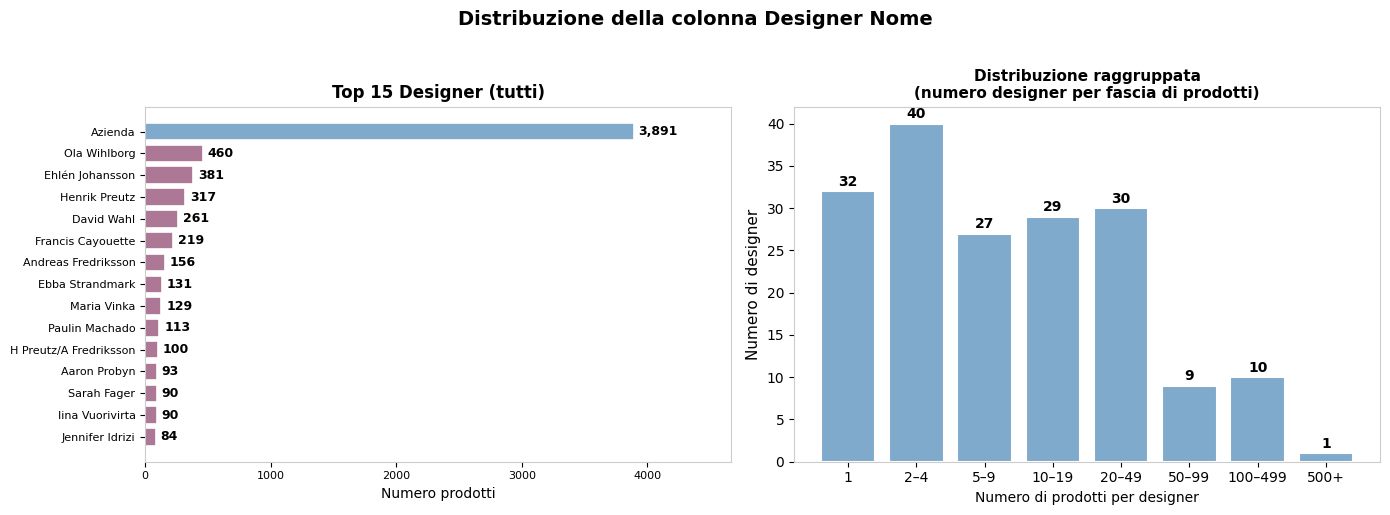

,Designer,Conteggio,%,% cumulata
0,Azienda,"3,891",46.12%,46.12%
1,Ola Wihlborg,460,5.45%,51.57%
2,Ehlén Johansson,381,4.52%,56.09%
3,Henrik Preutz,317,3.76%,59.84%
4,David Wahl,261,3.09%,62.94%
5,Francis Cayouette,219,2.60%,65.53%
6,Andreas Fredriksson,156,1.85%,67.38%
7,Ebba Strandmark,131,1.55%,68.93%
8,Maria Vinka,129,1.53%,70.46%
9,Paulin Machado,113,1.34%,71.80%


In [78]:
# Distribuzione e visualizzazione della colonna Designer Nome
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribuzione della colonna Designer Nome', fontsize=14, fontweight='bold', y=1.02)

# Grafico 1: top 15 designer (inclusa azienda)
vc_tutti = df['Designer Nome'].value_counts(dropna=True).head(15)
colori_bar = ['#7faacc' if v == LABEL_AZIENDA else '#ad7895' for v in vc_tutti.index]
axes[0].barh(vc_tutti.index[::-1], vc_tutti.values[::-1], color=colori_bar[::-1], edgecolor='white', linewidth=1.2)
for i, (val, cnt) in enumerate(zip(vc_tutti.index[::-1], vc_tutti.values[::-1])):
    axes[0].text(cnt + max(vc_tutti.values) * 0.01, i, f'{cnt:,}', va='center', fontsize=9, fontweight='bold', color='black')
axes[0].set_title('Top 15 Designer (tutti)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Numero prodotti', fontsize=10)
axes[0].tick_params(colors='black', labelsize=8)
axes[0].set_facecolor('white')
axes[0].set_xlim(0, max(vc_tutti.values) * 1.2)
for spine in axes[0].spines.values():
    spine.set_edgecolor('#cccccc')

# Grafico 2: istogramma con bin raggruppati
freq = df['Designer Nome'].value_counts(dropna=True)
bins = [1, 2, 5, 10, 20, 50, 100, 500, freq.max() + 1]
labels_bins = ['1', '2–4', '5–9', '10–19', '20–49', '50–99', '100–499', '500+']
gruppi = pd.cut(freq, bins=bins, right=False, labels=labels_bins)
conteggi_gruppi = gruppi.value_counts().reindex(labels_bins)
axes[1].bar(labels_bins,conteggi_gruppi.values,color='#7faacc',edgecolor='white',linewidth=1.5)
for i, val in enumerate(conteggi_gruppi.values):
    if val > 0:
        axes[1].text(i,val + 0.3,str(val),ha='center',va='bottom',fontsize=10,fontweight='bold',color='black')
axes[1].set_title('Distribuzione raggruppata\n(numero designer per fascia di prodotti)',fontsize=11,fontweight='bold')
axes[1].set_xlabel('Numero di prodotti per designer', fontsize=10)
axes[1].set_ylabel('Numero di designer', fontsize=11)
axes[1].tick_params(colors='black')
axes[1].set_facecolor('white')
for spine in axes[1].spines.values():
    spine.set_edgecolor('#cccccc')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

# Tabella 
vc = df['Designer Nome'].value_counts(dropna=True)
cum = vc.reset_index()
cum.columns = ['Designer', 'Conteggio']
cum['%'] = cum['Conteggio'] / cum['Conteggio'].sum() * 100
cum['% cumulata'] = cum['%'].cumsum()
display(cum.style.bar(subset=['Conteggio'], color='#ad7895').background_gradient(subset=['%'], cmap='Blues').background_gradient(subset=['% cumulata'], cmap='Greens')
    .set_properties(**{'color': 'black','background-color': 'white'}).format({'Conteggio': '{:,.0f}', '%': '{:.2f}%', '% cumulata': '{:.2f}%'}))

In [79]:
# Verifica: i designer collaboratori dell'azienda appaiono anche da soli?

# Estraiamo prima i designer in forma collaborativa (Azienda/Nome)
misti = df[df['Designer Nome'].str.contains('/', na=False) & df['Designer Nome'].str.startswith(LABEL_AZIENDA, na=False)].copy()

# Estraiamo poi solo il nome dopo "/"
nomi_collaboratori = (misti['Designer Nome'].str.split('/').str[-1].str.strip().unique())
print(f"Designer collaboratori trovati (Azienda/Nome): {len(nomi_collaboratori)}\n")
for n in nomi_collaboratori:
    print(f"  - {n}")
print()

# Analisi presenza autonoma
risultati = []

for nome in nomi_collaboratori:
    n_misto   = (df['Designer Nome'] == f'{LABEL_AZIENDA}/{nome}').sum()
    n_da_solo = (df['Designer Nome'] == nome).sum()
    risultati.append({'Designer': nome, 'Come collaboratore': n_misto, 'Da solo': n_da_solo})

df_collab = pd.DataFrame(risultati).sort_values('Come collaboratore', ascending=False)
display(df_collab.style.set_properties(**{'color': 'black', 'background-color': 'white'}).format({'Come collaboratore': '{:,.0f}', 'Da solo': '{:,.0f}'}).hide(axis='index'))

# Dettaglio per designer eventualmente presenti in entrambi i casi (con azienda e da soli)
anche_da_solo = df_collab[df_collab['Da solo'] > 0]['Designer'].tolist()

if anche_da_solo:
    print(f"\nDettaglio prodotti per designer presenti in entrambi i casi (con azienda e da soli):\n")
    for nome in anche_da_solo:
        print(f"  {nome}")
        subset = df[df['Designer Nome'].isin([nome, f'{LABEL_AZIENDA}/{nome}'])][['ID Prodotto', 'Designer Nome']].sort_values('Designer Nome')
        display(subset.style.set_properties(**{'color': 'black', 'background-color': 'white'}).hide(axis='index'))
        print()
else:
    print("\nNessun collaboratore compare anche da solo nel catalogo.")

Designer collaboratori trovati (Azienda/Nome): 3

  - F Cayouette
  - M Warnhammar
  - E Lilja Löwenhielm



Designer,Come collaboratore,Da solo
F Cayouette,8,0
M Warnhammar,5,0
E Lilja Löwenhielm,2,0



Nessun collaboratore compare anche da solo nel catalogo.


In [80]:
df.drop(columns=['Designer'], inplace=True)

### **3.3.4. Analisi dei materiali riciclati**

Resta ora da concentrarsi sulla composizione fisica dei prodotti. Il campo `Materiali` rappresenta un contenitore informativo di grande potenziale descrittivo, fondamentale per classificare le referenze in base alla loro natura (legno, metallo, tessili, polimeri). 

In [81]:
# Analisi preliminare della colonna Materiali
colonna_materiali = 'Materiali'
n_tot_mat = len(df)
righe_mat = df[colonna_materiali].notna().sum()
righe_null_mat = n_tot_mat - righe_mat
pct_mat = math.floor((righe_mat / n_tot_mat) * 10000) / 100 if n_tot_mat > 0 else 0
pct_null = math.floor((righe_null_mat / n_tot_mat) * 10000) / 100 if n_tot_mat > 0 else 0

print(f"Righe totali: {n_tot_mat:,}.")
print(f"Righe valorizzate: {righe_mat:,}  ({pct_mat:.2f}%).")
print(f"Righe mancanti: {righe_null_mat:,}  ({pct_null:.2f}%).")

# Tre esempi di valori grezzi
print("\nEsempi di valori grezzi:\n")
for idx, val in df[colonna_materiali].dropna().head(3).items():
    print(f"  [{idx}]  {val}")
    print()

# Cerchiamo le righe con la virgola ed estraiamo un campione casuale
print("\nEsempi casuali di valori grezzi contenenti la virgola:\n")
mask_virgola = df[colonna_materiali].str.contains(',', na=False)
esempi_virgola = df[mask_virgola][colonna_materiali].dropna().sample(8, random_state=42)
for idx, val in esempi_virgola.items():
    print(f"  [{idx}]  {val}")
    print()

Righe totali: 9,405.
Righe valorizzate: 9,215  (97.97%).
Righe mancanti: 190  (2.02%).

Esempi di valori grezzi:

  [0]  100% poliestere (100% riciclato) | 100 % poliestere | 100% polipropilene

  [1]  100% poliestere (100% riciclato) | 100 % poliestere | 100% polipropilene

  [2]  100% poliestere (100% riciclato) | 100 % poliestere | 100% polipropilene


Esempi casuali di valori grezzi contenenti la virgola:

  [5314]  Acciaio, Nichelato spazzolato, Rivestimento acrilico | 100% poliestere | Polipropilene (min. 50% riciclato)

  [428]  Impiallacciatura di betulla spessa, Olio acrilico | Laminato | Truciolare

  [5104]  Truciolare, Lamina di melammina, Bordo in plastica | Fibra di legno, Lacca acrilica

  [348]  Vetro temprato | Alluminio, Alluminio, Rivestimento epossidico/poliestere a polvere | Acciaio, Galvanizzato

  [1576]  Truciolare, Lamina di carta, Bordo in plastica, Bordo in plastica, Lamina di carta | Truciolare, Lamina di carta, Bordo in plastica, Bordo in plastica, Lamina d

Preso atto dell'impossibilità di standardizzare l'intera distinta base a causa dell'entropia sintattica, ora l'obiettivo esclusivo è **intercettare, quantificare e strutturare le informazioni relative ai materiali di recupero**. L'algoritmo sviluppato itera su ogni blocco di testo isolando la radice semantica `riciclat*` (per includere varianti come riciclato, riciclata, riciclate) e decodifica l'informazione gestendo tre casistiche strutturali distinte:

1. **Pattern 1 (Dato Annidato)**: intercetta i casi in cui la percentuale di riciclo è racchiusa tra parentesi e riferita a una percentuale di composizione esterna (per esempio, `100% poliestere (min 90% riciclato)`). Il parser associa correttamente la percentuale di riciclo al suo materiale di origine, gestendo anche le soglie minime (`min`).

2. **Pattern 2 (Dato Diretto)**: estrae i casi in cui l'indicazione di riciclo è espressa in linea senza parentesi (come `100% poliestere riciclato`).

3. **Pattern 3 (Dato Qualitativo)**: mappa le occorrenze in cui viene dichiarata la natura circolare del materiale, ma è assente il dato quantitativo percentuale (per esempio, `Plastica ABS riciclata`).

Per evitare duplicazioni dovute a stratificazioni complesse (come per esempio uno stesso materiale elencato più volte per componenti diverse dello stesso oggetto), è stato implementato un **sistema di deduplicazione** basato su chiavi multiple (`seen set`). 

In [82]:
# Parser riciclato

def parse_riciclato_componenti(testo):
    if pd.isna(testo) or not re.search(r'riciclat', str(testo), re.IGNORECASE):
        return []

    testo = str(testo).strip('"')
    risultati = []
    seen = set()

    for segmento in testo.split('|'):
        segmento = segmento.strip()

        # Caso 1: "riciclato" dentro le parentesi con percentuale
        for m in re.finditer(r'\((?P<minpfx>min\.?\s*)?(?P<pct>\d+)\s*%\s*(?P<inner>[^)%]*?)\s*riciclat\w*[^)]*\)', segmento, re.IGNORECASE):
            pct    = int(m.group('pct'))
            is_min = bool(re.match(r'min', (m.group('minpfx') or '').strip(), re.IGNORECASE))
            inner  = (m.group('inner') or '').strip()

            before = segmento[:m.start()].strip().rstrip(',').strip()
            parts  = [p.strip() for p in before.split(',') if p.strip()]
            last   = parts[-1] if parts else ''

            # Gestione di "lyocell/50% poliestere", per esempio, in cui si prende solo dopo l'ultimo "/""
            if '/' in last:
                last = last.split('/')[-1].strip()
            mat_m = re.match(r'^(\d+(?:[.,]\d+)?)\s*%\s*(.+)', last)
            if mat_m:
                mat_pct  = float(mat_m.group(1).replace(',', '.'))
                mat_name = mat_m.group(2).strip()
            else:
                mat_pct  = None
                mat_name = last
            ric_mat = inner if inner else None

            # Inclusione di "mat_pct" nella chiave per non perdere i casi in cui vi è la stessa sostanza con diverse percentuali di composizione
            key = (mat_name.lower()[:40], pct, is_min, mat_pct)

            if key not in seen:
                seen.add(key)
                risultati.append({'materiale': mat_name,'materiale_pct': mat_pct,'ric_pct': pct, 'ric_tipo': 'minimo' if is_min else 'esatto', 'ric_mat_interno': ric_mat})

        # Caso 2: "riciclato" fuori dalle parentesi con percentuale 
        seg_clean = re.sub(r'\([^)]*riciclat[^)]*\)', '', segmento, flags=re.IGNORECASE)
        seg_clean = re.sub(r'\([^)]*\)', '', seg_clean)

        for m in re.finditer(r'(?:^|,\s*)(\d+)\s*%\s+([\w\s/\'-]+?)\s+riciclat\w*', seg_clean, re.IGNORECASE):
            pct  = int(m.group(1))
            mat  = m.group(2).strip().rstrip(',- ').strip()
            key  = (mat.lower()[:40], pct, False, float(pct))

            if key not in seen:
                seen.add(key)
                risultati.append({'materiale': mat, 'materiale_pct': float(pct), 'ric_pct': pct, 'ric_tipo': 'esatto', 'ric_mat_interno': None})

        # Caso 3: "riciclato" senza percentuale (per esempio, Plastica ABS riciclata, fibre riciclate)
        seg_no_paren = re.sub(r'\([^)]*\)', '', segmento)
        seg_no_paren = re.sub(r'\d+\s*%\s+[\w\s]+riciclat\w*', '', seg_no_paren, flags=re.IGNORECASE)

        for m in re.finditer(r'(?:(?:^|[|,])\s*)((?:[A-ZÀ-Ö][\w\s/\']+?|[a-zà-ö][\w\s/\']+?))\s+riciclat\w*', seg_no_paren, re.IGNORECASE):
            mat = m.group(1).strip().rstrip(',- ').strip()
            if not re.search(r'\d', mat) and len(mat) > 2:
                key = (mat.lower()[:40], None, False, None)
                if key not in seen:
                    seen.add(key)
                    risultati.append({'materiale': mat, 'materiale_pct': None, 'ric_pct': None, 'ric_tipo': 'generico', 'ric_mat_interno': None})
    return risultati

# Materiale (% materiale presente) [% di riciclo]
def componenti_to_str(lista):
    if not lista:
        return None
    parti = []
    for c in lista:
        mat  = c['materiale'] or '?'
        mpct = f" ({c['materiale_pct']:.0f}%)" if c['materiale_pct'] else ''
        if c['ric_pct'] is not None:
            rmin = 'min ' if c['ric_tipo'] == 'minimo' else ''
            rint = f"[{rmin}{c['ric_pct']}% ric.]"
        else:
            rint = '[ric. presente]'
        rmat = f" ({c['ric_mat_interno']})" if c['ric_mat_interno'] else ''
        parti.append(f"{mat}{mpct} {rint}{rmat}")
    return ' | '.join(parti)

# Applicazione
parsed = df[colonna_materiali].apply(parse_riciclato_componenti)

df['Riciclato_componenti']   = parsed.apply(componenti_to_str)
df['Riciclato_n_componenti'] = parsed.apply(len)
df['Riciclato_pct_max']      = parsed.apply(lambda lst: max((c['ric_pct'] for c in lst if c['ric_pct'] is not None), default=None))

n_tot_df        = len(df)
n_mat_valorizzate = df[colonna_materiali].notna().sum()
n_con_riciclato = df['Riciclato_componenti'].notna().sum()
n_senza_ric     = n_mat_valorizzate - n_con_riciclato
n_mat_vuote     = n_tot_df - n_mat_valorizzate

print(f"{'─'*55}")
print(f"  Righe totali dataset: {n_tot_df:>7,}.")
print(f"  Colonna Materiali valorizzata: {n_mat_valorizzate:>7,}  ({n_mat_valorizzate/n_tot_df*100:.1f}%).")
print(f"  Colonna Materiali mancante: {n_mat_vuote:>7,}  ({n_mat_vuote/n_tot_df*100:.1f}%).")
print(f"{'─'*55}")
print(f"  Con materiale riciclato: {n_con_riciclato:>7,}  ({n_con_riciclato/n_mat_valorizzate*100:.1f}% delle valorizzate).")
print(f"  Senza materiale riciclato: {n_senza_ric:>7,}  ({n_senza_ric/n_mat_valorizzate*100:.1f}% delle valorizzate).")
print(f"{'─'*55}")

───────────────────────────────────────────────────────
  Righe totali dataset:   9,405.
  Colonna Materiali valorizzata:   9,215  (98.0%).
  Colonna Materiali mancante:     190  (2.0%).
───────────────────────────────────────────────────────
  Con materiale riciclato:   3,016  (32.7% delle valorizzate).
  Senza materiale riciclato:   6,199  (67.3% delle valorizzate).
───────────────────────────────────────────────────────


In [83]:
# Verifichiamo quanto fatto, aggiungendo anche la colonna che riporta l'ID Prodotto

rows_verifica = []

for idx, row in df[df[colonna_materiali].notna()].iterrows():
    val_str  = str(row[colonna_materiali]).strip('"')
    comp     = parse_riciclato_componenti(val_str)
    estratto = componenti_to_str(comp)
    if not comp:
        continue
    rows_verifica.append({'ID Prodotto': row['ID Prodotto'], 'Materiale (originale)': val_str, 'Estratto': estratto or '⚠ non estratto'})

df_verifica_raw = pd.DataFrame(rows_verifica)

# Aggregazione per riga unica: frequenza + lista ID Prodotto
df_verifica = (df_verifica_raw.groupby('Materiale (originale)').agg(Occorrenze  = ('Materiale (originale)', 'count'), ID_Prodotti = ('ID Prodotto', lambda x: ', '.join(x.astype(str).tolist())), Estratto    = ('Estratto', 'first')).reset_index().sort_values('Occorrenze', ascending=False).reset_index(drop=True))

n_ok = (df_verifica['Estratto'] != '⚠ non estratto').sum()
n_ko = (df_verifica['Estratto'] == '⚠ non estratto').sum()

print(f"Righe uniche con riciclato: {len(df_verifica):,}.")
print(f"Estratte correttamente: {n_ok:,}.")
print(f"Non estratte: {n_ko:,}.\n")

df_display = df_verifica.copy()

# ID Prodotti: mostriamo solo i primi 3 e inseriamo i puntini di sospensione se ce ne sono altri
def abbrevia_ids(ids_str, occorrenze):
    ids = ids_str.split(', ')
    if len(ids) <= 3:
        return ids_str
    return ', '.join(ids[:3]) + f' ... (+{occorrenze - 3} altri)'

df_display['ID_Prodotti'] = df_display.apply(lambda r: abbrevia_ids(r['ID_Prodotti'], r['Occorrenze']), axis=1)

# Campione di righe da visualizzare (frequenti + intermedie + rare)
n_top = 10
n_mid = 10
n_bottom = 10

df_sample = pd.concat([df_display.head(n_top),df_display.iloc[len(df_display)//2 - n_mid//2 : len(df_display)//2 + n_mid//2],df_display.tail(n_bottom)]).drop_duplicates()

display(df_sample[['Occorrenze', 'ID_Prodotti', 'Materiale (originale)', 'Estratto']].style.set_properties(**{'color': 'black', 'background-color': 'white'})
    .set_properties(subset=['Materiale (originale)', 'Estratto'],**{'white-space': 'normal', 'min-width': '350px', 'max-width': '500px'})
    .set_properties(subset=['ID_Prodotti'], **{'white-space': 'normal', 'min-width': '180px'})
    .apply(lambda col: ['background-color: #f5c6cb; color: black' if v == '⚠ non estratto' else '' for v in col], subset=['Estratto'])
    .format({'Occorrenze': '{:,.0f}'}).hide(axis='index'))

Righe uniche con riciclato: 465.
Estratte correttamente: 465.
Non estratte: 0.



Occorrenze,ID_Prodotti,Materiale (originale),Estratto
154,"3352483, 3386667, 3386668 ... (+151 altri)",100% poliestere (100% riciclato),poliestere (100%) [100% ric.]
123,"2926744, 2636040, 2636042 ... (+120 altri)",100% poliestere (min 90% riciclato),poliestere (100%) [min 90% ric.]
109,"3094127, 3094128, 2823319 ... (+106 altri)",100% poliestere (min 60% riciclato) | 100% polipropilene | 100% poliestere (100% riciclato) | 100% poliestere (min 90% riciclato),poliestere (100%) [min 60% ric.] | poliestere (100%) [100% ric.] | poliestere (100%) [min 90% ric.]
61,"3240842, 3240843, 3240844 ... (+58 altri)","100% poliestere (100% riciclato) | 70% poliestere (100% riciclato), 30% cotone",poliestere (100%) [100% ric.] | poliestere (70%) [100% ric.]
56,"2761766, 2090406, 3262485 ... (+53 altri)","100% poliestere (100% riciclato) | 80% cotone, 20% poliestere (min 90% riciclato)",poliestere (100%) [100% ric.] | poliestere (20%) [min 90% ric.]
51,"2624675, 3354901, 3386714 ... (+48 altri)","78% cotone, 22% poliestere (100% riciclato)",poliestere (22%) [100% ric.]
49,"2073620, 3092869, 3092874 ... (+46 altri)","55% cotone, 25% poliestere (100% riciclato), 12% viscosa, 8% lino",poliestere (25%) [100% ric.]
48,"3030161, 3030162, 3030163 ... (+45 altri)","Plastica ABS | 100% poliestere (100% riciclato) | Alluminio, Rivestimento epossidico/poliestere a polvere, Alluminio | Polipropilene, Polipropilene | Plastica PET, Plastica PET | Plastica acetalica | Polietilene | Policarbonato | Acciaio, Galvanizzato",poliestere (100%) [100% ric.]
39,"2746950, 2746951, 3375000 ... (+36 altri)",100% poliestere (100% riciclato) | Polietilene | Polistirene | Polipropilene,poliestere (100%) [100% ric.]
39,"2873841, 2873842, 2428213 ... (+36 altri)","70% poliestere (100% riciclato), 30% cotone",poliestere (70%) [100% ric.]


In [84]:
# Analisi post-estrazione: casi unici con riciclato prima vs dopo

n_unici_prima = len(df_verifica)        
n_unici_dopo = df['Riciclato_componenti'].nunique(dropna=True)  
riduzione = n_unici_prima - n_unici_dopo

print(f"{'─'*55}")
print(f"  Righe uniche con 'riciclato' (originale): {n_unici_prima:>5,}.")
print(f"  Valori unici estratti (dopo parser): {n_unici_dopo:>5,}.")
print(f"  Riduzione: {riduzione:>5,}  (-{riduzione/n_unici_prima*100:.1f}%).")
print(f"{'─'*55}\n")

# Distribuzione dei valori unici per frequenza
vc_estratto = (df['Riciclato_componenti'].value_counts(dropna=True).rename_axis('Riciclato_componenti').reset_index(name='Conteggio').assign(**{'% su con riciclato': lambda x: (x['Conteggio'] / n_con_riciclato * 100).round(2)}))

# Fascia di frequenza
print(f"Distribuzione dei {n_unici_dopo} valori unici per fascia di frequenza:\n")
bins   = [0, 1, 5, 10, 50, 100, vc_estratto['Conteggio'].max() + 1]
labels = ['1 (singleton)', '2–5', '6–10', '11–50', '51–100', '100+']
fascia = pd.cut(vc_estratto['Conteggio'], bins=bins, labels=labels)

display(fascia.value_counts().reindex(labels).rename_axis('Frequenza').reset_index(name='N. valori distinti').assign(**{'% su 164 unici': lambda x: (x['N. valori distinti'] / n_unici_dopo * 100).round(1)}).style.bar(subset=['N. valori distinti'], color='#7faacc')
        .set_properties(**{'color': 'black', 'background-color': 'white'}).format({'N. valori distinti': '{:,.0f}', '% su 164 unici': '{:.1f}%'}).hide(axis='index'))

# Top 30 più frequenti
print("Top 30 valori estratti più frequenti:\n")
display(vc_estratto.head(30).style.bar(subset=['Conteggio'], color='#ad7895').set_properties(**{'color': 'black', 'background-color': 'white'}).set_properties(subset=['Riciclato_componenti'],**{'white-space': 'normal', 'min-width': '400px'})
    .format({'Conteggio': '{:,.0f}', '% su con riciclato': '{:.2f}%'}).hide(axis='index'))

───────────────────────────────────────────────────────
  Righe uniche con 'riciclato' (originale):   465.
  Valori unici estratti (dopo parser):   164.
  Riduzione:   301  (-64.7%).
───────────────────────────────────────────────────────

Distribuzione dei 164 valori unici per fascia di frequenza:



Frequenza,N. valori distinti,% su 164 unici
1 (singleton),33,20.1%
2–5,55,33.5%
6–10,24,14.6%
11–50,36,22.0%
51–100,12,7.3%
100+,4,2.4%


Top 30 valori estratti più frequenti:



Riciclato_componenti,Conteggio,% su con riciclato
poliestere (100%) [100% ric.],507,16.81%
poliestere (100%) [min 90% ric.],275,9.12%
Lamina in plastica [min 90% ric.],147,4.87%
poliestere (100%) [min 60% ric.] | poliestere (100%) [100% ric.] | poliestere (100%) [min 90% ric.],109,3.61%
Plastica ABS [min 20% ric.],96,3.18%
Truciolare e fibra di legno con strato di riempimento in cartone a nido d'ape [100% ric.] (carta),88,2.92%
Alluminio [min 70% ric.],78,2.59%
Lamina di plastica [min 70% ric.],70,2.32%
Polipropilene [min 50% ric.],70,2.32%
poliestere (100%) [100% ric.] | poliestere (100%) [min 90% ric.],64,2.12%


Occorre procedere con la **correzione delle ridondanze residue**.

Un'ispezione dei valori estratti in `Riciclato_componenti` rivela che il numero di configurazioni distinte riportato sopra è ancora **gonfiato da ridondanze puramente testuali**, non da vere differenze di contenuto informativo. Le cause individuate sono tre:

1. **Ordine dei componenti**: quando un prodotto ha più materiali riciclati, l'ordine in cui compaiono nel testo originale viene preservato dal parser. Record come `poliestere (25%) [...] | poliestere (100%) [...]` e il loro esatto opposto `poliestere (100%) [...] | poliestere (25%) [...]` descrivono lo stesso prodotto, ma per Python (e per un semplice conteggio di stringhe uniche) risultano due valori diversi.

2. **Sinonimi e varianti di scrittura**: espressioni come `Lamina in plastica` e `Lamina di plastica` (o `plastica policarbonato` / `plastica di policarbonato`) indicano lo stesso materiale, ma con preposizioni diverse nel testo di origine; anche qui, per Python sono due stringhe distinte.

3. **Incoerenza di maiuscole/minuscole**: alcuni materiali vengono riportati con iniziale maiuscola (`Polipropilene`, `Alluminio`), altri minuscola (`poliestere`), a seconda di come erano scritti nel campo originale.

Per correggere questi tre problemi si procede in tre passi: prima si esplora l'elenco dei materiali unici per individuare le vere varianti da unificare (evitando di accorpare materiali che sembrano simili ma sono in realtà chimicamente/strutturalmente diversi, come `plastica ABS` vs `plastica PET`, o `poliestere` vs `poliestere - fibre cave`); poi si costruisce una mappa di alias mirata; infine si riscrive la funzione di serializzazione affinché normalizzi il case, applichi gli alias e **ordini alfabeticamente i componenti multipli** prima di unirli in stringa, così da rendere equivalenti le combinazioni scritte in ordine diverso.

In [85]:
import collections

# Estraiamo tutti i nomi dei materiali in minuscolo e senza spazi extra
materiali_unici = set()
for lista_comp in parsed.dropna():
    for c in lista_comp:
        mat_raw = c.get('materiale')
        if mat_raw:
            mat_clean = mat_raw.strip().lower()
            if mat_clean:
                materiali_unici.add(mat_clean)

# Raggruppiamo per similarità (usando la prima parola come "famiglia")
gruppi = collections.defaultdict(list)
for mat in sorted(materiali_unici):
    # Separiamo le parole e prendiamo la prima. 
    # Gestiamo l'apostrofo (es. "d'ape") e togliamo eventuali particelle inutili.
    parole = mat.split()
    radice = parole[0]
    
    # Un piccolo trucco: se la prima parola è molto corta (es. "l'", "un"), usiamo la seconda
    if len(radice) <= 2 and len(parole) > 1:
        radice = parole[1]
        
    gruppi[radice].append(mat)

# Stampiamo i risultati raggruppati in modo leggibile
print(f"Trovati {len(materiali_unici)} nomi base unici di materiali.\n")
print(f"{'─'*55}")

# Ordiniamo i gruppi per numero di varianti decrescente: le famiglie con più varianti sono le più "sospette"
for radice, mats in sorted(gruppi.items(), key=lambda x: -len(x[1])):
    if not radice:
        continue
    print(f"-> Famiglia '{radice.upper()}' ({len(mats)} varianti):")
    for m in mats:
        print(f"    - {m}")
    print(f"{'─'*30}")

Trovati 27 nomi base unici di materiali.

───────────────────────────────────────────────────────
-> Famiglia 'PLASTICA' (5 varianti):
    - plastica abs
    - plastica di policarbonato
    - plastica pet
    - plastica policarbonato
    - plastica polietilene
──────────────────────────────
-> Famiglia 'CARTONE' (3 varianti):
    - cartone
    - cartone a nido d'ape
    - cartone rigido
──────────────────────────────
-> Famiglia 'LAMINA' (2 varianti):
    - lamina di plastica
    - lamina in plastica
──────────────────────────────
-> Famiglia 'POLIESTERE' (2 varianti):
    - poliestere
    - poliestere - fibre cave
──────────────────────────────
-> Famiglia 'POLIPROPILENE' (2 varianti):
    - polipropilene
    - polipropilene rinforzato
──────────────────────────────
-> Famiglia 'ALLUMINIO' (1 varianti):
    - alluminio
──────────────────────────────
-> Famiglia 'BORDO' (1 varianti):
    - bordo in plastica
──────────────────────────────
-> Famiglia 'CARTA' (1 varianti):
    - carta sb

In [86]:
# Dizionario per uniformare i sinonimi (tutto in minuscolo qui)
MAPPA_MATERIALI = {'lamina in plastica': 'lamina di plastica',
    'plastica policarbonato': 'plastica di policarbonato',}

def componenti_to_str(lista):
    if not lista:
        return None
        
    parti = []
    for c in lista:
        # Lavoriamo solo sul nome del materiale (minuscolo per standardizzare)
        mat = c['materiale'] or '?'
        mat = mat.strip().lower()
        
        # Sostituiamo il nome se presente nel nostro dizionario
        if mat in MAPPA_MATERIALI:
            mat = MAPPA_MATERIALI[mat]
            
        # Rimettiamo la prima lettera maiuscola per estetica
        mat = mat.capitalize()

        # Lasciamo intatte le percentuali e le diciture di riciclo
        mpct = f" ({c['materiale_pct']:.0f}%)" if c['materiale_pct'] else ''
        
        if c['ric_pct'] is not None:
            rmin = 'min ' if c['ric_tipo'] == 'minimo' else ''
            rint = f"[{rmin}{c['ric_pct']}% ric.]"
        else:
            rint = '[ric. presente]'
            
        rmat = f" ({c['ric_mat_interno']})" if c['ric_mat_interno'] else ''
        
        # Assembliamo la stringa della singola componente
        parti.append(f"{mat}{mpct} {rint}{rmat}")
        
    # Ordiniamo alfabeticamente la lista delle componenti
    # Questo trasforma "B | A" in "A | B", rendendoli uguali per Python
    parti_ordinate = sorted(parti)
    
    return ' | '.join(parti_ordinate)

# Riapplichiamo la funzione aggiornata (con sorting e dizionario MAPPA_MATERIALI)
df['Riciclato_componenti'] = parsed.apply(componenti_to_str)

# Ricalcoliamo il totale dei valori estratti validi per le percentuali
n_con_riciclato = df['Riciclato_componenti'].notna().sum()

# Ricalcoliamo i nuovi valori unici
n_unici_dopo_pulizia = df['Riciclato_componenti'].nunique(dropna=True)
riduzione_pulizia = n_unici_prima - n_unici_dopo_pulizia

print(f"{'─'*55}")
print(f"Righe uniche con 'riciclato' (originale grezzo): {n_unici_prima:>5,}.")
print(f"Valori unici dopo l'ordinamento e la normalizzazione: {n_unici_dopo_pulizia:>5,}.")
print(f"Riduzione dovuta solo alla normalizzazione e all'ordinamento: {n_unici_dopo - n_unici_dopo_pulizia:>5,}.")
print(f"{'─'*55}\n")

───────────────────────────────────────────────────────
Righe uniche con 'riciclato' (originale grezzo):   465.
Valori unici dopo l'ordinamento e la normalizzazione:   143.
Riduzione dovuta solo alla normalizzazione e all'ordinamento:    21.
───────────────────────────────────────────────────────



Si procede con un'analisi esplorativa dei materiali riciclati.

Materiali riciclati distinti trovati: 25.


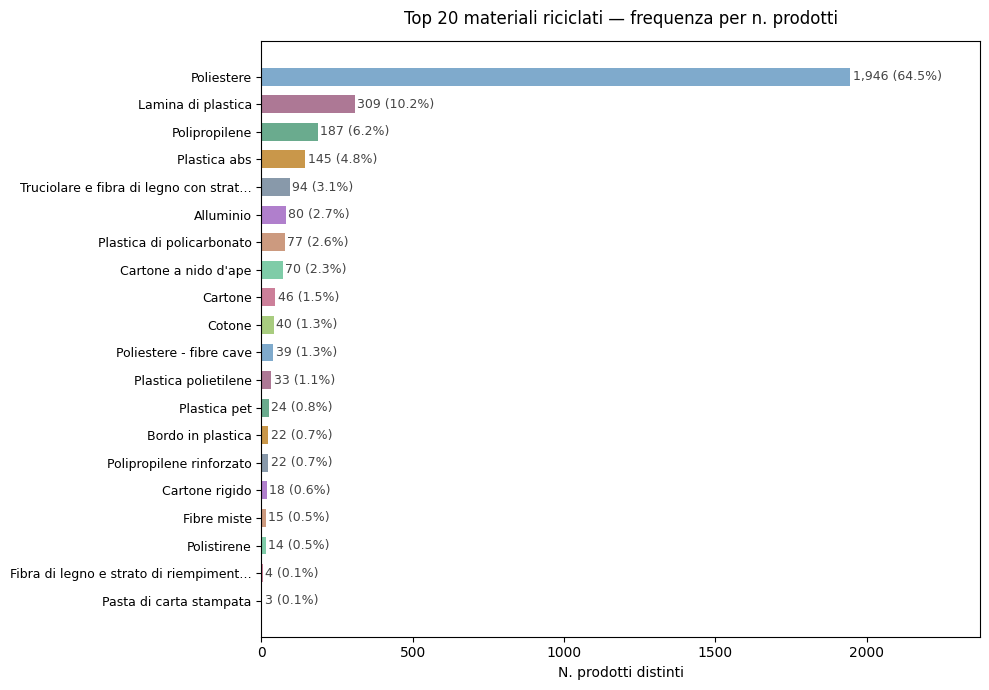

In [87]:
# Top 20 materiali riciclati per numero di prodotti

# Parser dei blocchi normalizzati
_RE_BLOCCO = re.compile(r'^(?P<mat>.+?)' r'(?:\s*\((?P<mat_pct>\d+(?:[.,]\d+)?)%\))?' r'\s*\[(?P<ric_raw>[^\]]+)\]' r'(?:\s*\((?P<ric_mat>[^)]+)\))?' r'\s*$')

# Restituisce un dizionario con i campi del blocco, oppure None se non parsabile
def parse_blocco(blocco: str) -> dict | None:
    m = _RE_BLOCCO.match(blocco.strip())
    if not m:
        return None
    ric_raw = m.group('ric_raw').strip()
    if ric_raw == 'ric. presente':
        ric_pct  = None
        ric_tipo = 'generico'
    else:
        is_min   = bool(re.match(r'min', ric_raw, re.IGNORECASE))
        pct_m    = re.search(r'(\d+(?:[.,]\d+)?)\s*%', ric_raw)
        ric_pct  = float(pct_m.group(1).replace(',', '.')) if pct_m else None
        ric_tipo = 'minimo' if is_min else 'esatto'

    mat_pct_raw = m.group('mat_pct')
    return {'materiale':    m.group('mat').strip(),
        'mat_pct':      float(mat_pct_raw.replace(',', '.')) if mat_pct_raw else None,
        'ric_pct':      ric_pct,
        'ric_tipo':     ric_tipo,
        'ric_mat_int':  m.group('ric_mat').strip() if m.group('ric_mat') else None,}

# Scompone l'intera stringa Riciclato_componenti nei suoi blocchi
def parse_riga(stringa: str) -> list[dict]:
    if pd.isna(stringa):
        return []
    blocchi = []
    for b in str(stringa).split(' | '):
        parsed = parse_blocco(b)
        if parsed:
            blocchi.append(parsed)
    return blocchi

records = []

for idx, row in df[df['Riciclato_componenti'].notna()].iterrows():
    for b in parse_riga(row['Riciclato_componenti']):
        b['_idx'] = idx
        records.append(b)

df_flat = pd.DataFrame(records)

# Conteggio prodotti distinti per materiale
freq_mat = (df_flat.groupby('materiale')['_idx'].nunique().sort_values(ascending=False).head(20).reset_index())
freq_mat.columns = ['materiale', 'n_prodotti']
freq_mat['pct'] = (freq_mat['n_prodotti']/ df_flat['_idx'].nunique()* 100).round(1)

n_materiali_distinti = df_flat['materiale'].nunique()
n_prodotti_con_ric = df_flat['_idx'].nunique()

def abbrev(s, n=38):
    return s if len(s) <= n else s[:n-1] + '…'

labels = [abbrev(m) for m in freq_mat['materiale']]
palette = ['#7faacc', '#ad7895', '#6aab8e', '#c9974a', '#8899aa','#b07fcc', '#cc9a7f', '#7fcca8', '#cc7f99', '#a8cc7f']
colors = [palette[i % len(palette)] for i in range(len(freq_mat))]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(labels[::-1],freq_mat['n_prodotti'].values[::-1],color=colors[::-1],height=0.65)

for bar, val, pct in zip(bars, freq_mat['n_prodotti'].values[::-1], freq_mat['pct'].values[::-1]):
    ax.text(bar.get_width() + 8,bar.get_y() + bar.get_height()/2,f'{val:,} ({pct:.1f}%)',va='center',ha='left',fontsize=9,color='#444')

ax.set_xlabel('N. prodotti distinti')
ax.set_title('Top 20 materiali riciclati — frequenza per n. prodotti', pad=12)
ax.set_xlim(0, freq_mat['n_prodotti'].max() * 1.22)
ax.tick_params(axis='y', labelsize=9)
plt.tight_layout()
print(f"Materiali riciclati distinti trovati: {n_materiali_distinti}.")
plt.show()

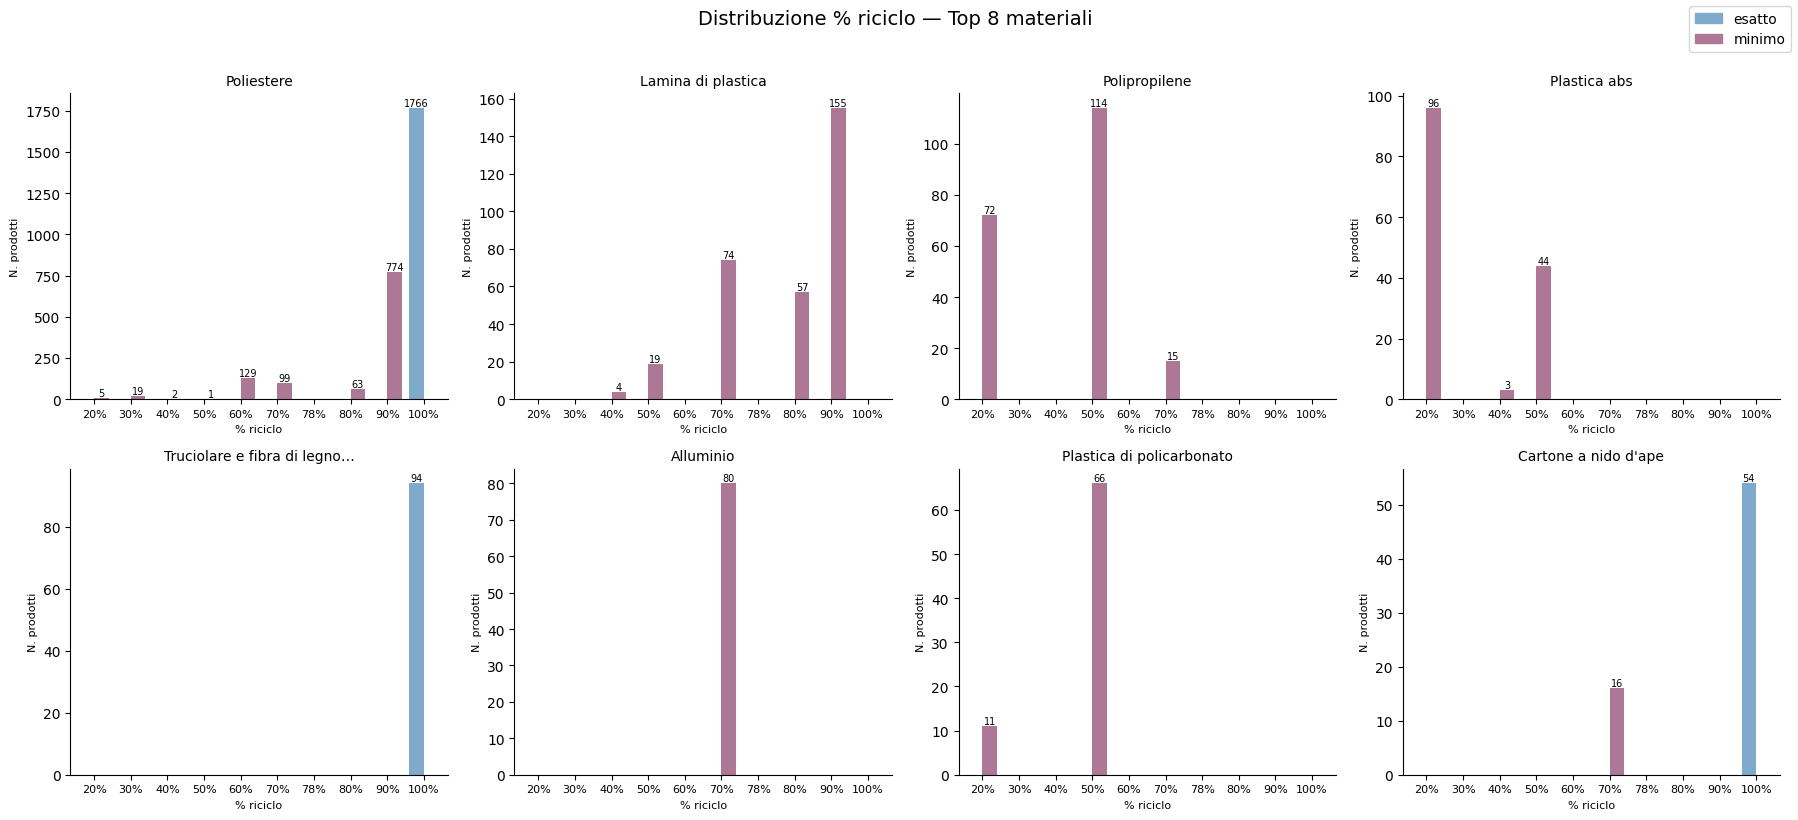

In [88]:
df_pct = df_flat[df_flat['ric_pct'].notna()].copy()
df_pct['ric_pct'] = df_pct['ric_pct'].astype(int)
top_mat_pct = (df_pct.groupby('materiale')['_idx'].nunique().sort_values(ascending=False).head(8).index.tolist())

COLOR_MAP = {'esatto': '#7faacc', 'minimo': '#ad7895'}

all_pcts = sorted(df_pct['ric_pct'].unique())
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Distribuzione % riciclo — Top 8 materiali', fontsize=14, y=1.02)

for ax, mat in zip(axes.flatten(), top_mat_pct):
    sub = df_pct[df_pct['materiale'] == mat]
    freq = (sub.groupby(['ric_pct', 'ric_tipo']).size().reset_index(name='Conteggio'))
    pivot = freq.pivot(index='ric_pct', columns='ric_tipo', values='Conteggio')
    pivot = pivot.reindex(all_pcts)
    pivot = pivot.reindex(columns=['esatto', 'minimo'])
    pivot.plot(kind='bar', ax=ax, color=[COLOR_MAP[c] for c in pivot.columns if c in COLOR_MAP], width=0.8)

    for container in ax.containers:
        labels = [f"{int(v)}" if pd.notna(v) and v > 0 else ""
            for v in container.datavalues]
        ax.bar_label(container, labels=labels, fontsize=7)

    ax.set_xticklabels([f"{p}%" for p in all_pcts], rotation=0, fontsize=8)
    ax.set_title(abbrev(mat, 28), fontsize=10)
    ax.set_xlabel('% riciclo', fontsize=8)
    ax.set_ylabel('N. prodotti', fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if ax.get_legend():
        ax.get_legend().remove()

handles = [mpatches.Patch(color='#7faacc', label='esatto'),mpatches.Patch(color='#ad7895', label='minimo')]
fig.legend(handles=handles, loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

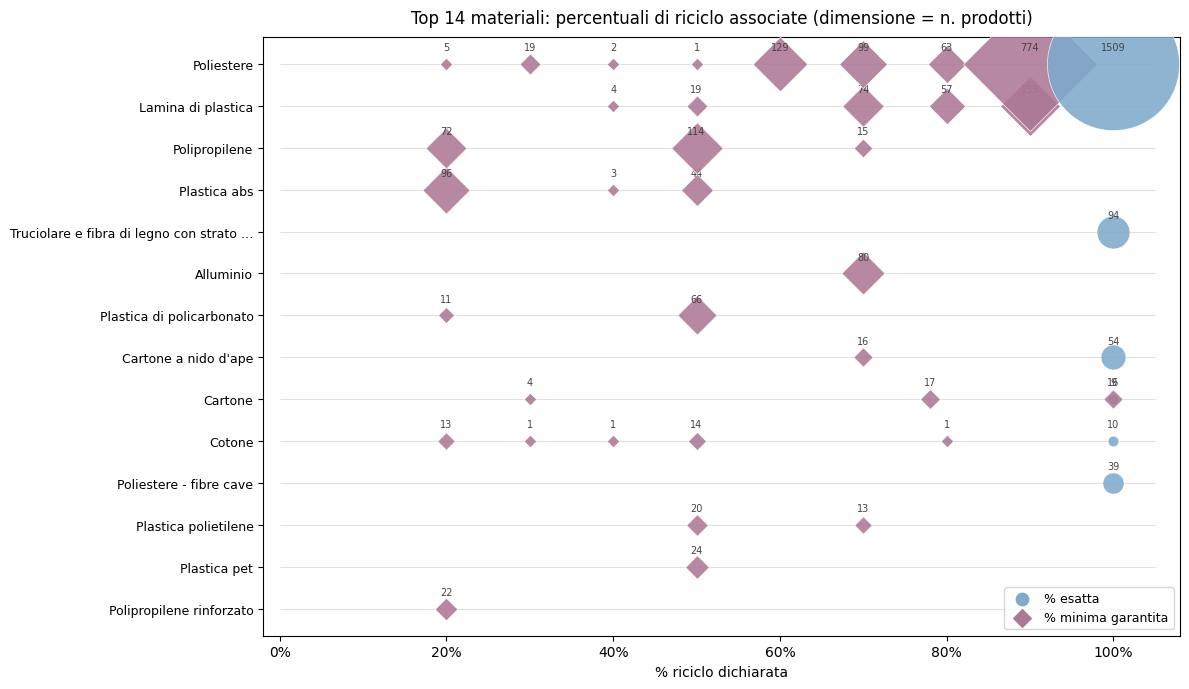

In [89]:
top_n = 14
top_mats = (df_pct.groupby('materiale')['_idx'].nunique().sort_values(ascending=False).head(top_n).index.tolist())

# Aggregazione: per ogni (materiale, ric_pct, ric_tipo) → n prodotti
agg = (df_pct[df_pct['materiale'].isin(top_mats)].groupby(['materiale', 'ric_pct', 'ric_tipo'])['_idx'].nunique().reset_index())
agg.columns = ['materiale', 'ric_pct', 'ric_tipo', 'n']
mat_order = top_mats[::-1]  # dal più freq in alto
mat_idx   = {m: i for i, m in enumerate(mat_order)}

fig, ax = plt.subplots(figsize=(12, 7))

for mat in mat_order:
    y = mat_idx[mat]
    ax.hlines(y, 0, 105, colors='#e0e0e0', linewidth=0.8, zorder=0)

for _, row in agg.iterrows():
    y = mat_idx[row['materiale']]
    x  = row['ric_pct']
    size = max(40, row['n'] * 6)
    color  = '#7faacc'  if row['ric_tipo'] == 'esatto' else '#ad7895'
    marker = 'o' if row['ric_tipo'] == 'esatto' else 'D'
    ax.scatter(x, y, s=size, color=color, marker=marker, alpha=0.88, zorder=3, edgecolors='white', linewidths=0.5)
    ax.text(x, y + 0.28, f'{int(row["n"])}', ha='center', va='bottom', fontsize=7, color='#444')

ax.set_yticks(range(len(mat_order)))
ax.set_yticklabels([abbrev(m, 40) for m in mat_order], fontsize=9)
ax.set_xlabel('% riciclo dichiarata', fontsize=10)
ax.set_xlim(-2, 108)
ax.set_title(f'Top {top_n} materiali: percentuali di riciclo associate (dimensione = n. prodotti)', pad=10)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%g%%'))
handles = [plt.scatter([], [], s=80, color='#7faacc', marker='o', label='% esatta'), plt.scatter([], [], s=80, color='#ad7895', marker='D', label='% minima garantita'),]
ax.legend(handles=handles, fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

Prodotti multi-componente riciclato: 926.
Coppie distinte identificate: 24.



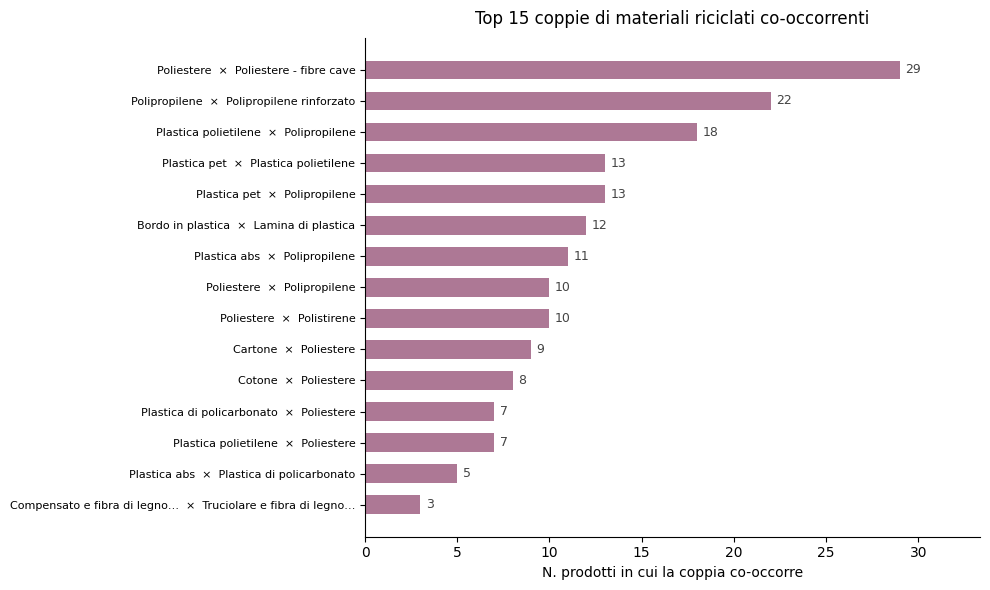

In [90]:
# Prodotti con 2+ componenti riciclati
multi = df_flat.groupby('_idx')['materiale'].apply(list)
multi = multi[multi.apply(len) >= 2]

# Conteggio coppie
pair_counts = defaultdict(int)
for mats in multi:
    uniq = list(dict.fromkeys(mats))  # deduplicazione preservando ordine
    for a, b in combinations(sorted(uniq), 2):
        pair_counts[(a, b)] += 1

df_pairs = (pd.DataFrame([(a, b, c) for (a,b), c in pair_counts.items()], columns=['mat_a', 'mat_b', 'count']).sort_values('count', ascending=False).head(15).reset_index(drop=True))
print(f"Prodotti multi-componente riciclato: {len(multi):,}.")
print(f"Coppie distinte identificate: {len(pair_counts):,}.\n")

df_pairs['coppia'] = df_pairs['mat_a'].apply(lambda x: abbrev(x,28)) + '  ×  ' + df_pairs['mat_b'].apply(lambda x: abbrev(x,28))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_pairs['coppia'].values[::-1], df_pairs['count'].values[::-1], color='#ad7895', height=0.6)
for bar, val in zip(bars, df_pairs['count'].values[::-1]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9, color='#444')
ax.set_xlabel('N. prodotti in cui la coppia co-occorre')
ax.set_title('Top 15 coppie di materiali riciclati co-occorrenti', pad=10)
ax.set_xlim(0, df_pairs['count'].max() * 1.15)
ax.tick_params(axis='y', labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

In [91]:
df.drop(columns=['Materiali', 'Riciclato_n_componenti', 'Riciclato_pct_max'], inplace=True)

## **Conclusioni e Salvataggio**

In [92]:
col_order = ['ID Prodotto',
    'Numero Articolo Catalogo',
    'Descrizione Completa',
    'Cura',
    'Buono a sapersi + Sicurezza e conformità',
    'Disponibilità',
    'Condizione Usato',
    'Motivo Vendita',
    'Nota Classificata',
    'Imballaggio Presente',
    'Prezzo Originale',
    'Prezzo Scontato',
    'Sconto',
    'Nome Negozio',
    'Tipologia Negozio',
    'Designer Nome',
    'Riciclato_componenti',
    'Classe efficienza energetica',
    'Classe efficienza energetica cavita',
    'Consumo energetico annuo (kWh/anno)',
    'Flusso luminoso nominale (lm)',
    'Portata max 3 bar (l/min)',
    'Efficienza fluidodinamica (%)',
    'Misure Standardizzata',]

df_finale = df[col_order]

print(f"Shape finale: {df_finale.shape}.")

# Colonne
nomi_colonne = list(df_finale.columns)
num_colonne_visive = 3
num_righe = math.ceil(len(nomi_colonne) / num_colonne_visive)

html_colonne = "<table style='width:100%; border:none; text-align:left;'>"
for r in range(num_righe):
    html_colonne += "<tr>"
    for c in range(num_colonne_visive):
        idx = c * num_righe + r
        if idx < len(nomi_colonne):
            num = idx + 1
            html_colonne += f"<td style='padding:4px 8px;'><code>{num}. {nomi_colonne[idx]}</code></td>"
        else:
            html_colonne += "<td></td>"
    html_colonne += "</tr>"
html_colonne += "</table>"

display(HTML(html_colonne))

Shape finale: (9405, 24).


1. ID Prodotto,9. Nota Classificata,17. Riciclato_componenti
2. Numero Articolo Catalogo,10. Imballaggio Presente,18. Classe efficienza energetica
3. Descrizione Completa,11. Prezzo Originale,19. Classe efficienza energetica cavita
4. Cura,12. Prezzo Scontato,20. Consumo energetico annuo (kWh/anno)
5. Buono a sapersi + Sicurezza e conformità,13. Sconto,21. Flusso luminoso nominale (lm)
6. Disponibilità,14. Nome Negozio,22. Portata max 3 bar (l/min)
7. Condizione Usato,15. Tipologia Negozio,23. Efficienza fluidodinamica (%)
8. Motivo Vendita,16. Designer Nome,24. Misure Standardizzata


In [93]:
cartella_destinazione = os.path.join("Circular Second Hand", "Analisi", "Analisi - Usato", "Risultati Analisi - Usato")
if not os.path.exists(cartella_destinazione):
    os.makedirs(cartella_destinazione)

nome_file_pulito = f"1_cleaning__usato.csv"
percorso_salvataggio = os.path.join(cartella_destinazione, nome_file_pulito)
df_finale.to_csv(percorso_salvataggio, index=False)

display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML(f"""<h4><b>Salvataggio completato</b>:</h4> <ul>
             <li>Il dataset pulito e formattato è stato salvato con successo in: <b>{percorso_salvataggio}</b>.</li> </ul>"""))